In [2]:
# ============================================================
# STEP 1: Import and Check Required Libraries
# ============================================================

import os
import sys
import glob
import time
import json
import random
import zipfile
import warnings

import numpy as np
import pandas as pd

import scipy
from scipy import stats
from scipy import signal

import matplotlib.pyplot as plt

import sklearn
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Check versions and GPU
print("=" * 55)
print("LIBRARY AND ENVIRONMENT CHECK")
print("=" * 55)

print("Python       :", sys.version.split()[0])
print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("SciPy        :", scipy.__version__)
print("Scikit-learn :", sklearn.__version__)
print("TensorFlow   :", tf.__version__)

print("\nGPU available:", tf.config.list_physical_devices("GPU"))

print("\nAll required libraries imported successfully.")

LIBRARY AND ENVIRONMENT CHECK
Python       : 3.13.15
NumPy        : 2.1.3
Pandas       : 2.2.3
SciPy        : 1.16.3
Scikit-learn : 1.6.1
TensorFlow   : 2.20.0

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

All required libraries imported successfully.


In [3]:
# ============================================================
# STEP 2: Mount Google Drive and Locate MobiFall Dataset
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# Search Google Drive for ZIP files containing "mobi" in the name
import os

drive_root = "/content/drive/MyDrive"

mobifall_files = []

for root, dirs, files in os.walk(drive_root):
    for file in files:
        if "mobi" in file.lower() and file.lower().endswith(".zip"):
            mobifall_files.append(os.path.join(root, file))

print("=" * 60)
print("MOBIFALL DATASET SEARCH")
print("=" * 60)

if mobifall_files:
    print(f"\nFound {len(mobifall_files)} possible MobiFall ZIP file(s):\n")

    for i, file_path in enumerate(mobifall_files, start=1):
        file_size_mb = os.path.getsize(file_path) / (1024 ** 2)

        print(f"{i}. {file_path}")
        print(f"   Size: {file_size_mb:.2f} MB")
else:
    print("\nNo MobiFall ZIP file was found in Google Drive.")

print("\n" + "=" * 60)
print("STEP 2 COMPLETED")
print("=" * 60)

Mounted at /content/drive
MOBIFALL DATASET SEARCH

Found 1 possible MobiFall ZIP file(s):

1. /content/drive/MyDrive/GWO-BiLSTN/MobiFall_Dataset_v2.0.zip
   Size: 90.23 MB

STEP 2 COMPLETED


In [4]:
# ============================================================
# STEP 3: Inspect MobiFall ZIP File Structure
# ============================================================

import zipfile
import os
from collections import Counter

# Use the first MobiFall ZIP found in Step 2
if len(mobifall_files) == 0:
    raise FileNotFoundError("No MobiFall ZIP file was found in Step 2.")

zip_path = mobifall_files[0]

print("=" * 65)
print("MOBIFALL ZIP FILE INSPECTION")
print("=" * 65)

print("\nZIP file:")
print(zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:

    file_list = zip_ref.namelist()

    # Remove folder-only entries
    actual_files = [
        f for f in file_list
        if not f.endswith("/")
    ]

    print(f"\nTotal entries : {len(file_list)}")
    print(f"Actual files  : {len(actual_files)}")

    # ------------------------------------------
    # File extensions
    # ------------------------------------------
    extensions = []

    for f in actual_files:
        ext = os.path.splitext(f)[1].lower()

        if ext == "":
            ext = "[no extension]"

        extensions.append(ext)

    extension_counts = Counter(extensions)

    print("\nFile types:")
    for ext, count in extension_counts.most_common():
        print(f"{ext:15s}: {count}")

    # ------------------------------------------
    # Top-level folders
    # ------------------------------------------
    top_folders = Counter()

    for f in file_list:
        parts = f.split("/")

        if len(parts) > 1:
            top_folders[parts[0]] += 1

    print("\nTop-level folders:")
    for folder, count in top_folders.items():
        print(f"{folder}: {count} entries")

    # ------------------------------------------
    # Show first 50 paths
    # ------------------------------------------
    print("\nFirst 50 entries:")
    print("-" * 65)

    for i, f in enumerate(file_list[:50], start=1):
        print(f"{i:3d}. {f}")

print("\n" + "=" * 65)
print("STEP 3 COMPLETED")
print("=" * 65)

MOBIFALL ZIP FILE INSPECTION

ZIP file:
/content/drive/MyDrive/GWO-BiLSTN/MobiFall_Dataset_v2.0.zip

Total entries : 1891
Actual files  : 1891

File types:
.txt           : 1891

Top-level folders:
MobiFall_Dataset_v2.0: 1891 entries

First 50 entries:
-----------------------------------------------------------------
  1. MobiFall_Dataset_v2.0/Readme.txt
  2. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_acc_1_1.txt
  3. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_acc_1_2.txt
  4. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_acc_1_3.txt
  5. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_gyro_1_1.txt
  6. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_gyro_1_2.txt
  7. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_gyro_1_3.txt
  8. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_ori_1_1.txt
  9. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_ori_1_2.txt
 10. MobiFall_Dataset_v2.0/sub1/FALLS/BSC/BSC_ori_1_3.txt
 11. MobiFall_Dataset_v2.0/sub1/FALLS/FKL/FKL_acc_1_1.txt
 12. MobiFall_Dataset_v2.0/sub1/FALLS/FKL/FKL_acc_1_2.txt
 1

In [5]:
# ============================================================
# STEP 4: Extract MobiFall v2.0 Dataset
# ============================================================

import os
import zipfile

# ZIP path identified in Step 3
zip_path = "/content/drive/MyDrive/GWO-BiLSTN/MobiFall_Dataset_v2.0.zip"

# Extract to Colab local storage for faster processing
extract_path = "/content/MobiFall"

print("=" * 60)
print("EXTRACTING MOBIFALL v2.0")
print("=" * 60)

# Extract only if not already extracted
if not os.path.exists(extract_path):
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("\nDataset extracted successfully.")
else:
    print("\nExtraction folder already exists.")
    print("Skipping extraction.")

# Dataset root
dataset_root = os.path.join(
    extract_path,
    "MobiFall_Dataset_v2.0"
)

print("\nDataset root:")
print(dataset_root)

# Check dataset root
if os.path.exists(dataset_root):
    print("\nDataset root verified successfully.")
else:
    print("\nWARNING: Dataset root was not found.")

# Count extracted TXT files
txt_files = []

for root, dirs, files in os.walk(dataset_root):
    for file in files:
        if file.lower().endswith(".txt"):
            txt_files.append(os.path.join(root, file))

print(f"\nTotal extracted TXT files: {len(txt_files)}")

# Identify subject folders
subject_folders = sorted([
    folder
    for folder in os.listdir(dataset_root)
    if folder.lower().startswith("sub")
])

print(f"Number of subject folders: {len(subject_folders)}")
print("Subject folders:")
print(subject_folders)

print("\n" + "=" * 60)
print("STEP 4 COMPLETED")
print("=" * 60)

EXTRACTING MOBIFALL v2.0

Dataset extracted successfully.

Dataset root:
/content/MobiFall/MobiFall_Dataset_v2.0

Dataset root verified successfully.

Total extracted TXT files: 1891
Number of subject folders: 24
Subject folders:
['sub1', 'sub10', 'sub11', 'sub12', 'sub13', 'sub14', 'sub15', 'sub16', 'sub17', 'sub18', 'sub19', 'sub2', 'sub20', 'sub21', 'sub29', 'sub3', 'sub30', 'sub31', 'sub4', 'sub5', 'sub6', 'sub7', 'sub8', 'sub9']

STEP 4 COMPLETED


In [6]:
# ============================================================
# STEP 5: Inspect README and Sample Sensor Files
# ============================================================

import os
import glob

dataset_root = "/content/MobiFall/MobiFall_Dataset_v2.0"

print("=" * 65)
print("MOBIFALL FILE FORMAT INSPECTION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Read README
# ------------------------------------------------------------
readme_path = os.path.join(dataset_root, "Readme.txt")

print("\nREADME CONTENT")
print("-" * 65)

if os.path.exists(readme_path):
    with open(readme_path, "r", errors="ignore") as f:
        readme_text = f.read()

    print(readme_text)
else:
    print("Readme.txt not found.")


# ------------------------------------------------------------
# 2. Find one sample from each sensor type
# ------------------------------------------------------------
acc_files = glob.glob(
    os.path.join(dataset_root, "**", "*_acc_*.txt"),
    recursive=True
)

gyro_files = glob.glob(
    os.path.join(dataset_root, "**", "*_gyro_*.txt"),
    recursive=True
)

ori_files = glob.glob(
    os.path.join(dataset_root, "**", "*_ori_*.txt"),
    recursive=True
)


print("\n" + "=" * 65)
print("SENSOR FILE COUNTS")
print("=" * 65)

print("Accelerometer files :", len(acc_files))
print("Gyroscope files     :", len(gyro_files))
print("Orientation files   :", len(ori_files))


# ------------------------------------------------------------
# 3. Function to inspect raw file
# ------------------------------------------------------------
def inspect_file(file_path, n_lines=12):

    print("\n" + "=" * 65)
    print("FILE:")
    print(file_path)
    print("-" * 65)

    with open(file_path, "r", errors="ignore") as f:
        for i in range(n_lines):
            line = f.readline()

            if not line:
                break

            print(f"{i+1:02d}: {line.rstrip()}")


# ------------------------------------------------------------
# 4. Inspect one file of each type
# ------------------------------------------------------------
if acc_files:
    print("\n\nACCELEROMETER SAMPLE")
    inspect_file(acc_files[0])

if gyro_files:
    print("\n\nGYROSCOPE SAMPLE")
    inspect_file(gyro_files[0])

if ori_files:
    print("\n\nORIENTATION SAMPLE")
    inspect_file(ori_files[0])


print("\n" + "=" * 65)
print("STEP 5 COMPLETED")
print("=" * 65)

MOBIFALL FILE FORMAT INSPECTION

README CONTENT
-----------------------------------------------------------------
===========================MobiFallDatasetv2.0===========================


Filename format:
<ADL OR FALL_CODE>_<SENSOR_CODE>_<SUBJECT_ID>_<TRIAL_NO>.txt


examples:
1 -->	WAL_acc_5_1.txt
2 -->	STD_ori_9_5.txt
3 -->	FKL_gyro_3_2.txt


Subjects:
+----+-------+---------+-----+--------+--------+--------+
| id | Name  | Surname | Age | Height | Weight | Gender |
+----+-------+---------+-----+--------+--------+--------+
| 1  | pat1  | pat1    | 32  | 180    | 85     | M      |
| 2  | pat2  | pat2    | 26  | 169    | 64     | M      |
| 3  | pat3  | pat3    | 26  | 164    | 55     | F      |
| 4  | pat4  | pat4    | 32  | 186    | 93     | M      |
| 5  | pat5  | pat5    | 36  | 160    | 50     | F      |
| 6  | pat6  | pat6    | 22  | 172    | 62     | F      |
| 7  | pat7  | pat7    | 25  | 189    | 80     | M      |
| 8  | pat8  | pat8    | 22  | 183    | 93     | M      |
| 9

In [7]:
# ============================================================
# STEP 6: Inspect Actual Numerical Sensor Data
# ============================================================

def show_sensor_data(file_path, n_lines=10):
    """
    Display the first numerical data rows from a MobiFall file.
    Lines beginning with # are metadata and are ignored.
    """

    print("=" * 70)
    print("FILE:")
    print(file_path)
    print("-" * 70)

    data_lines = []

    with open(file_path, "r", errors="ignore") as f:

        for line in f:

            line = line.strip()

            # Skip metadata and empty lines
            if not line or line.startswith("#"):
                continue

            data_lines.append(line)

            if len(data_lines) >= n_lines:
                break

    for i, line in enumerate(data_lines, start=1):
        print(f"{i:02d}: {line}")


# ------------------------------------------------------------
# Accelerometer
# ------------------------------------------------------------

print("\nACCELEROMETER DATA\n")
show_sensor_data(acc_files[0])


# ------------------------------------------------------------
# Gyroscope
# ------------------------------------------------------------

print("\n\nGYROSCOPE DATA\n")
show_sensor_data(gyro_files[0])


# ------------------------------------------------------------
# Orientation
# ------------------------------------------------------------

print("\n\nORIENTATION DATA\n")
show_sensor_data(ori_files[0])


print("\n" + "=" * 70)
print("STEP 6 COMPLETED")
print("=" * 70)


ACCELEROMETER DATA

FILE:
/content/MobiFall/MobiFall_Dataset_v2.0/sub10/ADL/JOG/JOG_acc_10_1.txt
----------------------------------------------------------------------
01: @DATA
02: 2352167833000, -1.541866, 9.787497, -1.043872
03: 2352367946000, -2.2218192, 9.002198, -2.2409728
04: 2352379977000, -2.1930888, 9.021352, -2.4037786
05: 2352389264000, -2.1068976, 9.126697, -2.4708161
06: 2352399324000, -2.0111294, 9.346964, -2.3654714
07: 2352410141000, -1.8483237, 9.5385, -2.231396
08: 2352420109000, -1.733402, 9.672575, -1.8866309
09: 2352430288000, -1.4077905, 9.768343, -1.8004397
10: 2352441852000, -1.2066777, 9.864111, -1.8004397


GYROSCOPE DATA

FILE:
/content/MobiFall/MobiFall_Dataset_v2.0/sub10/ADL/JOG/JOG_gyro_10_2.txt
----------------------------------------------------------------------
01: @DATA
02: 2445892988000, -9.305005, 7.5356336, -1.3448198
03: 2445897942000, -9.305005, 1.8454239, -0.6768387
04: 2445902991000, 7.1006975, 0.74067414, 0.035124753
05: 2445907995000, -1.16

In [8]:
# ============================================================
# STEP 7: Create Complete MobiFall Dataset Inventory
# ============================================================

import os
import re
import pandas as pd

dataset_root = "/content/MobiFall/MobiFall_Dataset_v2.0"

records = []

# ------------------------------------------------------------
# Scan all sensor files
# ------------------------------------------------------------

for root, dirs, files in os.walk(dataset_root):

    for file in files:

        if not file.endswith(".txt"):
            continue

        # Ignore README
        if file.lower() == "readme.txt":
            continue

        # Expected filename:
        # ACTIVITY_SENSOR_SUBJECT_TRIAL.txt

        match = re.match(
            r"([A-Za-z]+)_(acc|gyro|ori)_(\d+)_(\d+)\.txt",
            file
        )

        if match is None:
            continue

        activity = match.group(1).upper()
        sensor = match.group(2).lower()
        subject = int(match.group(3))
        trial = int(match.group(4))

        # Determine FALL or ADL from folder
        if "FALLS" in root.upper():
            category = "FALL"
        elif "ADL" in root.upper():
            category = "ADL"
        else:
            category = "UNKNOWN"

        records.append({
            "subject": subject,
            "category": category,
            "activity": activity,
            "trial": trial,
            "sensor": sensor,
            "file_path": os.path.join(root, file)
        })


# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

inventory = pd.DataFrame(records)

inventory = inventory.sort_values(
    ["subject", "category", "activity", "trial", "sensor"]
).reset_index(drop=True)


# ------------------------------------------------------------
# Basic dataset summary
# ------------------------------------------------------------

print("=" * 65)
print("MOBIFALL DATASET INVENTORY")
print("=" * 65)

print("\nTotal sensor files:")
print(len(inventory))

print("\nNumber of subjects:")
print(inventory["subject"].nunique())

print("\nSubject IDs:")
print(sorted(inventory["subject"].unique()))

print("\nNumber of activities:")
print(inventory["activity"].nunique())

print("\nActivity codes:")
print(sorted(inventory["activity"].unique()))


# ------------------------------------------------------------
# Category distribution
# ------------------------------------------------------------

print("\nFiles by category:")
print(
    inventory["category"]
    .value_counts()
)


# ------------------------------------------------------------
# Sensor distribution
# ------------------------------------------------------------

print("\nFiles by sensor:")
print(
    inventory["sensor"]
    .value_counts()
)


# ------------------------------------------------------------
# Activities and number of recordings
# ------------------------------------------------------------

print("\nActivity distribution:")
activity_summary = (
    inventory
    .groupby(["category", "activity"])
    .size()
    .reset_index(name="sensor_files")
)

print(activity_summary.to_string(index=False))


# ------------------------------------------------------------
# Count unique recording trials
# A recording = subject + activity + trial
# ------------------------------------------------------------

recordings = (
    inventory[
        ["subject", "category", "activity", "trial"]
    ]
    .drop_duplicates()
)

print("\nTotal unique recordings:")
print(len(recordings))

print("\nUnique recordings by category:")
print(
    recordings["category"]
    .value_counts()
)


# ------------------------------------------------------------
# Subjects with ADL and FALL recordings
# ------------------------------------------------------------

subject_categories = (
    recordings
    .groupby("subject")["category"]
    .apply(lambda x: sorted(x.unique()))
)

print("\nData available for each subject:")
print(subject_categories.to_string())


# ------------------------------------------------------------
# Check sensor completeness
# ------------------------------------------------------------

sensor_check = (
    inventory
    .groupby(
        ["subject", "category", "activity", "trial"]
    )["sensor"]
    .nunique()
    .reset_index(name="number_of_sensors")
)

incomplete = sensor_check[
    sensor_check["number_of_sensors"] != 3
]

print("\nRecordings without all 3 sensor types:")

if len(incomplete) == 0:
    print("None. All recordings contain acc, gyro and ori.")
else:
    print(incomplete.to_string(index=False))


print("\n" + "=" * 65)
print("STEP 7 COMPLETED")
print("=" * 65)

MOBIFALL DATASET INVENTORY

Total sensor files:
1890

Number of subjects:
24

Subject IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(29), np.int64(30), np.int64(31)]

Number of activities:
13

Activity codes:
['BSC', 'CSI', 'CSO', 'FKL', 'FOL', 'JOG', 'JUM', 'SCH', 'SDL', 'STD', 'STN', 'STU', 'WAL']

Files by category:
category
ADL     1026
FALL     864
Name: count, dtype: int64

Files by sensor:
sensor
acc     630
gyro    630
ori     630
Name: count, dtype: int64

Activity distribution:
category activity  sensor_files
     ADL      CSI           162
     ADL      CSO           162
     ADL      JOG            81
     ADL      JUM            81
     ADL      SCH           162
     ADL      STD            27
     ADL      STN           16

In [9]:
# ============================================================
# STEP 8: Check Sensor Data Quality and Sampling Characteristics
# ============================================================

import numpy as np
import pandas as pd


def read_mobifall_sensor(file_path):
    """
    Read numerical data from one MobiFall sensor file.
    Returns: timestamp, x, y, z
    """

    rows = []

    with open(file_path, "r", errors="ignore") as f:

        data_started = False

        for line in f:

            line = line.strip()

            if line == "@DATA":
                data_started = True
                continue

            if not data_started or not line:
                continue

            try:
                values = [float(v.strip()) for v in line.split(",")]

                if len(values) == 4:
                    rows.append(values)

            except ValueError:
                continue

    return np.asarray(rows, dtype=np.float64)


# ------------------------------------------------------------
# Analyze every sensor file
# ------------------------------------------------------------

quality_records = []

for i, row in inventory.iterrows():

    data = read_mobifall_sensor(row["file_path"])

    if len(data) > 0:

        timestamps = data[:, 0]

        # Timestamp differences
        dt = np.diff(timestamps)

        # Keep positive intervals only
        positive_dt = dt[dt > 0]

        if len(positive_dt) > 0:

            median_dt_ns = np.median(positive_dt)

            # Convert nanoseconds to seconds
            median_dt_sec = median_dt_ns / 1e9

            sampling_rate = (
                1 / median_dt_sec
                if median_dt_sec > 0
                else np.nan
            )

            duration_sec = (
                timestamps[-1] - timestamps[0]
            ) / 1e9

        else:

            sampling_rate = np.nan
            duration_sec = np.nan

        missing_values = np.isnan(data).sum()

        infinite_values = np.isinf(data).sum()

    else:

        sampling_rate = np.nan
        duration_sec = np.nan
        missing_values = 0
        infinite_values = 0

    quality_records.append({

        "subject": row["subject"],
        "category": row["category"],
        "activity": row["activity"],
        "trial": row["trial"],
        "sensor": row["sensor"],

        "samples": len(data),

        "duration_sec": duration_sec,

        "estimated_sampling_hz": sampling_rate,

        "missing_values": missing_values,

        "infinite_values": infinite_values
    })


quality_df = pd.DataFrame(quality_records)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 70)
print("MOBIFALL DATA QUALITY CHECK")
print("=" * 70)

print("\nTotal files analysed:")
print(len(quality_df))


print("\nFiles containing no numerical samples:")
print((quality_df["samples"] == 0).sum())


print("\nTotal missing values:")
print(quality_df["missing_values"].sum())


print("\nTotal infinite values:")
print(quality_df["infinite_values"].sum())


# ------------------------------------------------------------
# Samples by sensor
# ------------------------------------------------------------

print("\nSample count statistics by sensor:")

print(
    quality_df
    .groupby("sensor")["samples"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)


# ------------------------------------------------------------
# Duration
# ------------------------------------------------------------

print("\nRecording duration statistics (seconds):")

print(
    quality_df
    .groupby("sensor")["duration_sec"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)


# ------------------------------------------------------------
# Estimated sampling frequency
# ------------------------------------------------------------

print("\nEstimated sampling frequency (Hz):")

print(
    quality_df
    .groupby("sensor")["estimated_sampling_hz"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)


# ------------------------------------------------------------
# Separate ADL and FALL durations
# ------------------------------------------------------------

print("\nDuration by category and sensor:")

print(
    quality_df
    .groupby(
        ["category", "sensor"]
    )["duration_sec"]
    .agg(["median", "mean"])
    .round(2)
)


print("\n" + "=" * 70)
print("STEP 8 COMPLETED")
print("=" * 70)

MOBIFALL DATA QUALITY CHECK

Total files analysed:
1890

Files containing no numerical samples:
0

Total missing values:
0

Total infinite values:
0

Sample count statistics by sensor:
         min  median     mean    max
sensor                              
acc      333   819.0  1658.36  28938
gyro    1010  1999.0  3793.00  60000
ori     1009  1978.0  3762.65  59990

Recording duration statistics (seconds):
         min  median   mean     max
sensor                             
acc     5.05    9.87  18.87  300.01
gyro    5.04    9.99  18.96  300.00
ori     5.04    9.99  18.96  300.00

Estimated sampling frequency (Hz):
           min  median    mean     max
sensor                                
acc      80.89   93.87   93.56   99.05
gyro    199.92  200.12  200.15  200.56
ori     199.88  200.12  200.12  200.56

Duration by category and sensor:
                 median   mean
category sensor               
ADL      acc       9.81  26.41
         gyro      9.99  26.50
         ori       

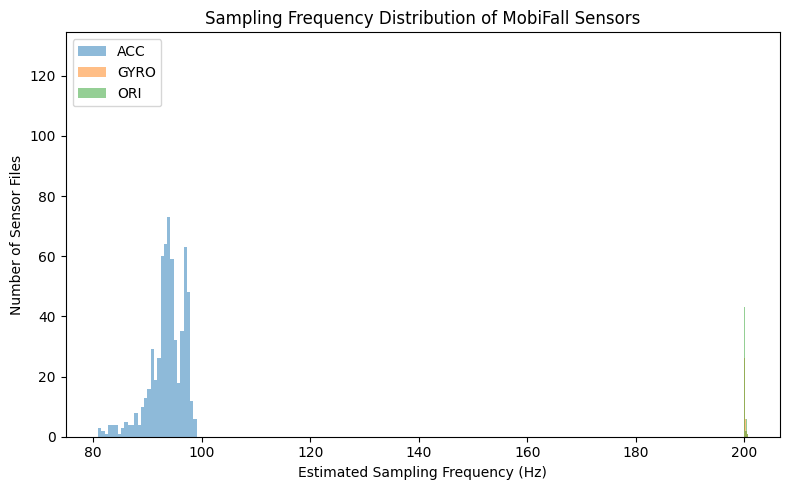

MEDIAN SAMPLING FREQUENCIES
ACC  : 93.87 Hz
GYRO : 200.12 Hz
ORI  : 200.12 Hz


In [10]:
# ============================================================
# STEP 9: Visualize Sensor Sampling Frequencies
# ============================================================

import matplotlib.pyplot as plt

# Keep valid sampling frequencies
plot_df = quality_df[
    quality_df["estimated_sampling_hz"].notna()
].copy()

# Create one figure
fig, ax = plt.subplots(figsize=(8, 5))

for sensor_name in ["acc", "gyro", "ori"]:

    values = plot_df.loc[
        plot_df["sensor"] == sensor_name,
        "estimated_sampling_hz"
    ]

    ax.hist(
        values,
        bins=30,
        alpha=0.5,
        label=sensor_name.upper()
    )

ax.set_xlabel("Estimated Sampling Frequency (Hz)")
ax.set_ylabel("Number of Sensor Files")
ax.set_title("Sampling Frequency Distribution of MobiFall Sensors")

ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Print median values
# ------------------------------------------------------------

print("=" * 55)
print("MEDIAN SAMPLING FREQUENCIES")
print("=" * 55)

for sensor_name in ["acc", "gyro", "ori"]:

    median_hz = plot_df.loc[
        plot_df["sensor"] == sensor_name,
        "estimated_sampling_hz"
    ].median()

    print(
        f"{sensor_name.upper():5s}: "
        f"{median_hz:.2f} Hz"
    )

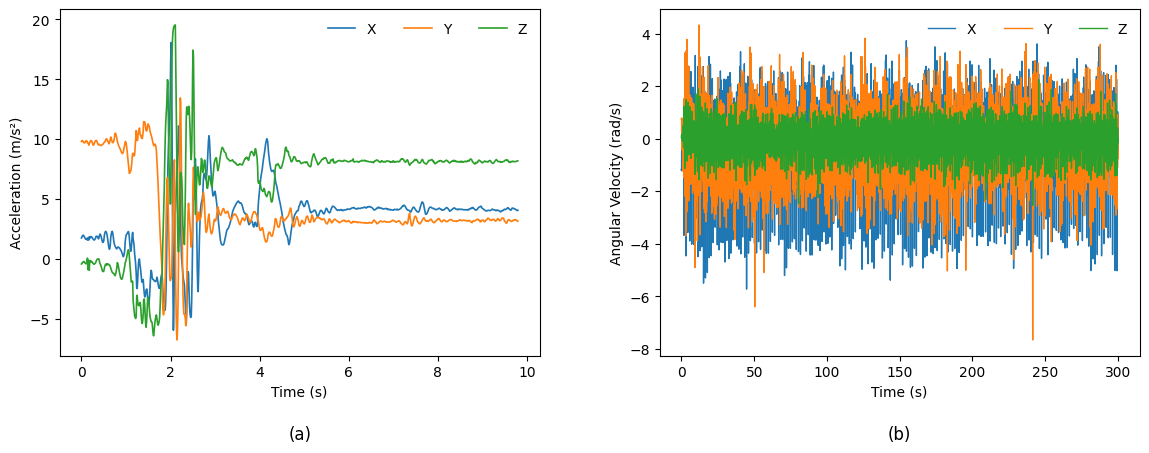

Figure saved to:
/content/drive/MyDrive/GWO-BiLSTN/MobiFall_Raw_Signal_Comparison.png


In [11]:
# ============================================================
# STEP 10: Raw Signal Comparison
# (a) Accelerometer - Forward Fall
# (b) Gyroscope - Walking
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Function to load MobiFall sensor file
# ------------------------------------------------------------

def load_sensor_file(file_path):

    rows = []

    with open(file_path, "r", errors="ignore") as f:

        data_started = False

        for line in f:

            line = line.strip()

            if line == "@DATA":
                data_started = True
                continue

            if not data_started or not line:
                continue

            try:
                values = [
                    float(v.strip())
                    for v in line.split(",")
                ]

                if len(values) == 4:
                    rows.append(values)

            except ValueError:
                continue

    return np.asarray(rows, dtype=np.float64)


# ------------------------------------------------------------
# 2. Convert timestamp to relative time in seconds
# ------------------------------------------------------------

def relative_time(data):

    timestamps = data[:, 0]

    return (
        timestamps - timestamps[0]
    ) / 1e9


# ------------------------------------------------------------
# 3. Select subject and recordings
# ------------------------------------------------------------

subject_id = 2

fall_activity = "FOL"
fall_trial = 1

walk_activity = "WAL"
walk_trial = 1


# ------------------------------------------------------------
# 4. File paths
# ------------------------------------------------------------

fall_acc_path = os.path.join(
    dataset_root,
    f"sub{subject_id}",
    "FALLS",
    fall_activity,
    f"{fall_activity}_acc_{subject_id}_{fall_trial}.txt"
)

walk_gyro_path = os.path.join(
    dataset_root,
    f"sub{subject_id}",
    "ADL",
    walk_activity,
    f"{walk_activity}_gyro_{subject_id}_{walk_trial}.txt"
)


# ------------------------------------------------------------
# 5. Check files
# ------------------------------------------------------------

if not os.path.exists(fall_acc_path):
    raise FileNotFoundError(fall_acc_path)

if not os.path.exists(walk_gyro_path):
    raise FileNotFoundError(walk_gyro_path)


# ------------------------------------------------------------
# 6. Load data
# ------------------------------------------------------------

fall_acc = load_sensor_file(fall_acc_path)
walk_gyro = load_sensor_file(walk_gyro_path)

fall_acc_time = relative_time(fall_acc)
walk_gyro_time = relative_time(walk_gyro)


# ------------------------------------------------------------
# 7. Create side-by-side figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5)
)


# ============================================================
# (a) Accelerometer signal for Forward Fall
# ============================================================

axes[0].plot(
    fall_acc_time,
    fall_acc[:, 1],
    label="X",
    linewidth=1.2
)

axes[0].plot(
    fall_acc_time,
    fall_acc[:, 2],
    label="Y",
    linewidth=1.2
)

axes[0].plot(
    fall_acc_time,
    fall_acc[:, 3],
    label="Z",
    linewidth=1.2
)

axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Acceleration (m/s²)")

axes[0].legend(
    frameon=False,
    ncol=3,
    loc="upper right"
)

axes[0].text(
    0.5,
    -0.20,
    "(a)",
    transform=axes[0].transAxes,
    ha="center",
    va="top",
    fontsize=12
)


# ============================================================
# (b) Gyroscope signal for Walking
# ============================================================

axes[1].plot(
    walk_gyro_time,
    walk_gyro[:, 1],
    label="X",
    linewidth=1.0
)

axes[1].plot(
    walk_gyro_time,
    walk_gyro[:, 2],
    label="Y",
    linewidth=1.0
)

axes[1].plot(
    walk_gyro_time,
    walk_gyro[:, 3],
    label="Z",
    linewidth=1.0
)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Angular Velocity (rad/s)")

axes[1].legend(
    frameon=False,
    ncol=3,
    loc="upper right"
)

axes[1].text(
    0.5,
    -0.20,
    "(b)",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=12
)


# ------------------------------------------------------------
# 8. Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.97,
    bottom=0.20,
    wspace=0.25
)


# ------------------------------------------------------------
# 9. Save high-resolution figure
# ------------------------------------------------------------

figure_path = (
    "/content/drive/MyDrive/GWO-BiLSTN/"
    "MobiFall_Raw_Signal_Comparison.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(figure_path)

In [12]:
# ============================================================
# STEP 11: Synchronize ACC and GYRO and Resample to 100 Hz
# Test on One Forward-Fall Recording
# ============================================================

import numpy as np
import pandas as pd
import os


# ------------------------------------------------------------
# 1. Target sampling frequency
# ------------------------------------------------------------

TARGET_FS = 100  # Hz


# ------------------------------------------------------------
# 2. Function to synchronize and resample ACC + GYRO
# ------------------------------------------------------------

def synchronize_acc_gyro(acc_data, gyro_data, target_fs=100):

    # Original timestamps in nanoseconds
    acc_t = acc_data[:, 0]
    gyro_t = gyro_data[:, 0]

    # --------------------------------------------------------
    # Find common time interval
    # --------------------------------------------------------

    start_time = max(acc_t[0], gyro_t[0])
    end_time = min(acc_t[-1], gyro_t[-1])

    if end_time <= start_time:
        raise ValueError("ACC and GYRO have no overlapping time interval.")

    # --------------------------------------------------------
    # Create common timeline
    # --------------------------------------------------------

    step_ns = 1e9 / target_fs

    common_t = np.arange(
        start_time,
        end_time,
        step_ns
    )

    # --------------------------------------------------------
    # Linear interpolation
    # --------------------------------------------------------

    acc_x = np.interp(common_t, acc_t, acc_data[:, 1])
    acc_y = np.interp(common_t, acc_t, acc_data[:, 2])
    acc_z = np.interp(common_t, acc_t, acc_data[:, 3])

    gyro_x = np.interp(common_t, gyro_t, gyro_data[:, 1])
    gyro_y = np.interp(common_t, gyro_t, gyro_data[:, 2])
    gyro_z = np.interp(common_t, gyro_t, gyro_data[:, 3])

    # Relative time in seconds
    relative_t = (
        common_t - common_t[0]
    ) / 1e9

    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    synchronized = pd.DataFrame({

        "time": relative_t,

        "acc_x": acc_x,
        "acc_y": acc_y,
        "acc_z": acc_z,

        "gyro_x": gyro_x,
        "gyro_y": gyro_y,
        "gyro_z": gyro_z
    })

    return synchronized


# ------------------------------------------------------------
# 3. Select one Forward Fall recording
# ------------------------------------------------------------

subject_id = 2
activity = "FOL"
trial = 1

acc_path = os.path.join(
    dataset_root,
    f"sub{subject_id}",
    "FALLS",
    activity,
    f"{activity}_acc_{subject_id}_{trial}.txt"
)

gyro_path = os.path.join(
    dataset_root,
    f"sub{subject_id}",
    "FALLS",
    activity,
    f"{activity}_gyro_{subject_id}_{trial}.txt"
)


# ------------------------------------------------------------
# 4. Load original signals
# ------------------------------------------------------------

acc_data = load_sensor_file(acc_path)
gyro_data = load_sensor_file(gyro_path)


# ------------------------------------------------------------
# 5. Synchronize and resample
# ------------------------------------------------------------

synced_data = synchronize_acc_gyro(
    acc_data,
    gyro_data,
    target_fs=TARGET_FS
)


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("=" * 65)
print("ACC + GYRO SYNCHRONIZATION TEST")
print("=" * 65)

print("\nSubject :", subject_id)
print("Activity:", activity)
print("Trial   :", trial)

print("\nOriginal data:")
print("ACC samples :", len(acc_data))
print("GYRO samples:", len(gyro_data))

print("\nAfter synchronization:")
print("Samples     :", len(synced_data))
print("Channels    :", 6)

print(
    "Duration (s):",
    round(synced_data["time"].iloc[-1], 2)
)

# Check new sampling frequency
time_difference = np.diff(
    synced_data["time"].values
)

estimated_fs = 1 / np.median(time_difference)

print(
    "Sampling frequency:",
    round(estimated_fs, 2),
    "Hz"
)

print("\nFirst 10 synchronized samples:")
print(
    synced_data.head(10).to_string(index=False)
)

print("\nMissing values:")
print(synced_data.isna().sum())

print("\n" + "=" * 65)
print("STEP 11 COMPLETED")
print("=" * 65)

ACC + GYRO SYNCHRONIZATION TEST

Subject : 2
Activity: FOL
Trial   : 1

Original data:
ACC samples : 947
GYRO samples: 1999

After synchronization:
Samples     : 980
Channels    : 6
Duration (s): 9.79
Sampling frequency: 100.0 Hz

First 10 synchronized samples:
 time    acc_x    acc_y     acc_z    gyro_x    gyro_y    gyro_z
 0.00 1.752556 9.806650 -0.421380  0.004012  0.034542 -0.025755
 0.01 1.819028 9.863627 -0.373899  0.006752  0.037604 -0.022843
 0.02 1.921942 9.881169 -0.305263  0.007666  0.012758 -0.009663
 0.03 1.959721 9.858059 -0.296881  0.026869 -0.010854  0.001682
 0.04 1.987963 9.796860 -0.247445  0.029286 -0.025019  0.010579
 0.05 1.949701 9.719857 -0.222510  0.019816 -0.046232  0.031526
 0.06 1.889663 9.703106 -0.220267  0.007865 -0.053131  0.021656
 0.07 1.805194 9.694120 -0.277755 -0.010865 -0.036380  0.022275
 0.08 1.741691 9.737923 -0.336477 -0.011861 -0.018038  0.019242
 0.09 1.672418 9.803748 -0.373620 -0.003125  0.012837  0.017605

Missing values:
time      0
acc_x

In [13]:
# ============================================================
# STEP 12: Synchronize All MobiFall Recordings at 100 Hz
# ============================================================

import numpy as np
import pandas as pd
import time


print("=" * 70)
print("SYNCHRONIZING ALL MOBIFALL RECORDINGS")
print("=" * 70)

start_processing = time.time()


# ------------------------------------------------------------
# 1. Get unique recordings
# ------------------------------------------------------------

unique_recordings = (
    inventory[
        ["subject", "category", "activity", "trial"]
    ]
    .drop_duplicates()
    .sort_values(
        ["subject", "category", "activity", "trial"]
    )
    .reset_index(drop=True)
)


print("\nTotal recordings to process:")
print(len(unique_recordings))


# ------------------------------------------------------------
# 2. Storage
# ------------------------------------------------------------

synchronized_recordings = []

processing_summary = []

failed_recordings = []


# ------------------------------------------------------------
# 3. Process each recording
# ------------------------------------------------------------

for idx, rec in unique_recordings.iterrows():

    subject = int(rec["subject"])
    category = rec["category"]
    activity = rec["activity"]
    trial = int(rec["trial"])


    # --------------------------------------------------------
    # Locate ACC file
    # --------------------------------------------------------

    acc_match = inventory[
        (inventory["subject"] == subject) &
        (inventory["category"] == category) &
        (inventory["activity"] == activity) &
        (inventory["trial"] == trial) &
        (inventory["sensor"] == "acc")
    ]


    # --------------------------------------------------------
    # Locate GYRO file
    # --------------------------------------------------------

    gyro_match = inventory[
        (inventory["subject"] == subject) &
        (inventory["category"] == category) &
        (inventory["activity"] == activity) &
        (inventory["trial"] == trial) &
        (inventory["sensor"] == "gyro")
    ]


    if len(acc_match) != 1 or len(gyro_match) != 1:

        failed_recordings.append({
            "subject": subject,
            "category": category,
            "activity": activity,
            "trial": trial,
            "reason": "ACC or GYRO file missing"
        })

        continue


    acc_path = acc_match.iloc[0]["file_path"]
    gyro_path = gyro_match.iloc[0]["file_path"]


    try:

        # ----------------------------------------------------
        # Load raw sensor signals
        # ----------------------------------------------------

        acc_data = load_sensor_file(acc_path)
        gyro_data = load_sensor_file(gyro_path)


        # ----------------------------------------------------
        # Synchronize at 100 Hz
        # ----------------------------------------------------

        synced = synchronize_acc_gyro(
            acc_data,
            gyro_data,
            target_fs=TARGET_FS
        )


        # ----------------------------------------------------
        # Add metadata
        # ----------------------------------------------------

        synced["subject"] = subject
        synced["category"] = category
        synced["activity"] = activity
        synced["trial"] = trial

        # Binary label
        # 0 = ADL
        # 1 = FALL

        synced["fall_label"] = (
            1 if category == "FALL" else 0
        )


        # Unique recording ID
        synced["recording_id"] = (
            f"S{subject}_{activity}_T{trial}"
        )


        synchronized_recordings.append(synced)


        # ----------------------------------------------------
        # Save processing information
        # ----------------------------------------------------

        processing_summary.append({

            "subject": subject,
            "category": category,
            "activity": activity,
            "trial": trial,

            "acc_original_samples": len(acc_data),
            "gyro_original_samples": len(gyro_data),

            "synchronized_samples": len(synced),

            "duration_sec":
                synced["time"].iloc[-1]
                if len(synced) > 0
                else np.nan
        })


    except Exception as e:

        failed_recordings.append({

            "subject": subject,
            "category": category,
            "activity": activity,
            "trial": trial,
            "reason": str(e)

        })


# ------------------------------------------------------------
# 4. Processing summary
# ------------------------------------------------------------

processing_summary_df = pd.DataFrame(
    processing_summary
)

failed_recordings_df = pd.DataFrame(
    failed_recordings
)


# ------------------------------------------------------------
# 5. Combine synchronized recordings
# ------------------------------------------------------------

if len(synchronized_recordings) > 0:

    mobifall_synced = pd.concat(
        synchronized_recordings,
        ignore_index=True
    )

else:

    raise RuntimeError(
        "No recordings were successfully synchronized."
    )


# ------------------------------------------------------------
# 6. Processing time
# ------------------------------------------------------------

processing_time = time.time() - start_processing


# ------------------------------------------------------------
# 7. Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SYNCHRONIZATION RESULTS")
print("=" * 70)

print("\nSuccessfully synchronized recordings:")
print(len(processing_summary_df))

print("\nFailed recordings:")
print(len(failed_recordings_df))

print("\nTotal synchronized samples:")
print(f"{len(mobifall_synced):,}")


print("\nSamples by category:")
print(
    mobifall_synced["category"]
    .value_counts()
)


print("\nSamples by fall label:")
print(
    mobifall_synced["fall_label"]
    .value_counts()
    .sort_index()
)


print("\nSynchronized samples per recording:")

print(
    processing_summary_df[
        "synchronized_samples"
    ]
    .describe()
    .round(2)
)


print("\nRecording duration after synchronization:")

print(
    processing_summary_df[
        "duration_sec"
    ]
    .describe()
    .round(2)
)


# ------------------------------------------------------------
# 8. Check missing values
# ------------------------------------------------------------

sensor_columns = [
    "acc_x",
    "acc_y",
    "acc_z",
    "gyro_x",
    "gyro_y",
    "gyro_z"
]

print("\nMissing sensor values:")

print(
    mobifall_synced[
        sensor_columns
    ]
    .isna()
    .sum()
)


# ------------------------------------------------------------
# 9. Check infinite values
# ------------------------------------------------------------

infinite_count = np.isinf(
    mobifall_synced[
        sensor_columns
    ].values
).sum()

print("\nInfinite sensor values:")
print(infinite_count)


# ------------------------------------------------------------
# 10. Activity distribution
# ------------------------------------------------------------

print("\nRecordings by activity:")

print(
    processing_summary_df
    .groupby(
        ["category", "activity"]
    )
    .size()
)


# ------------------------------------------------------------
# 11. Processing time
# ------------------------------------------------------------

print(
    f"\nProcessing time: "
    f"{processing_time:.2f} seconds"
)


# ------------------------------------------------------------
# 12. Failed recordings if any
# ------------------------------------------------------------

if len(failed_recordings_df) > 0:

    print("\nFAILED RECORDINGS:")
    print(
        failed_recordings_df.to_string(
            index=False
        )
    )


print("\n" + "=" * 70)
print("STEP 12 COMPLETED")
print("=" * 70)

SYNCHRONIZING ALL MOBIFALL RECORDINGS

Total recordings to process:
630

SYNCHRONIZATION RESULTS

Successfully synchronized recordings:
630

Failed recordings:
0

Total synchronized samples:
1,189,032

Samples by category:
category
ADL     903254
FALL    285778
Name: count, dtype: int64

Samples by fall label:
fall_label
0    903254
1    285778
Name: count, dtype: int64

Synchronized samples per recording:
count      630.00
mean      1887.35
std       4862.99
min        503.00
25%        599.00
50%        988.00
75%        996.00
max      30000.00
Name: synchronized_samples, dtype: float64

Recording duration after synchronization:
count    630.00
mean      18.86
std       48.63
min        5.02
25%        5.98
50%        9.87
75%        9.95
max      299.99
Name: duration_sec, dtype: float64

Missing sensor values:
acc_x     0
acc_y     0
acc_z     0
gyro_x    0
gyro_y    0
gyro_z    0
dtype: int64

Infinite sensor values:
0

Recordings by activity:
category  activity
ADL       CSI    

In [14]:
# ============================================================
# STEP 13: Inspect Subject-Level Activity Coverage
# ============================================================

subject_summary = (
    processing_summary_df
    .groupby(["subject", "category"])
    .size()
    .unstack(fill_value=0)
)

# Make sure both columns exist
for col in ["ADL", "FALL"]:
    if col not in subject_summary.columns:
        subject_summary[col] = 0

subject_summary = subject_summary[
    ["ADL", "FALL"]
]

subject_summary["Total"] = (
    subject_summary["ADL"] +
    subject_summary["FALL"]
)

subject_summary["Coverage"] = np.where(
    (subject_summary["ADL"] > 0) &
    (subject_summary["FALL"] > 0),
    "ADL + FALL",
    np.where(
        subject_summary["ADL"] > 0,
        "ADL only",
        "FALL only"
    )
)


print("=" * 65)
print("SUBJECT-LEVEL RECORDING DISTRIBUTION")
print("=" * 65)

print(
    subject_summary.to_string()
)


print("\n" + "=" * 65)
print("SUBJECT COVERAGE SUMMARY")
print("=" * 65)

print(
    subject_summary["Coverage"]
    .value_counts()
)


print("\nSubjects with both ADL and FALL:")
print(
    subject_summary[
        subject_summary["Coverage"] == "ADL + FALL"
    ].index.tolist()
)


print("\nSubjects with FALL only:")
print(
    subject_summary[
        subject_summary["Coverage"] == "FALL only"
    ].index.tolist()
)


print("\nSubjects with ADL only:")
print(
    subject_summary[
        subject_summary["Coverage"] == "ADL only"
    ].index.tolist()
)


print("\n" + "=" * 65)
print("STEP 13 COMPLETED")
print("=" * 65)

SUBJECT-LEVEL RECORDING DISTRIBUTION
category  ADL  FALL  Total    Coverage
subject                               
1           0    12     12   FALL only
2          38    12     50  ADL + FALL
3          38    12     50  ADL + FALL
4          38    12     50  ADL + FALL
5          38    12     50  ADL + FALL
6           0    12     12   FALL only
7          38    12     50  ADL + FALL
8          38    12     50  ADL + FALL
9          38    12     50  ADL + FALL
10         38    12     50  ADL + FALL
11         38    12     50  ADL + FALL
12          0    12     12   FALL only
13          0    12     12   FALL only
14          0    12     12   FALL only
15          0    12     12   FALL only
16          0    12     12   FALL only
17          0    12     12   FALL only
18          0    12     12   FALL only
19          0    12     12   FALL only
20          0    12     12   FALL only
21          0    12     12   FALL only
29          0    12     12   FALL only
30          0    12     12 

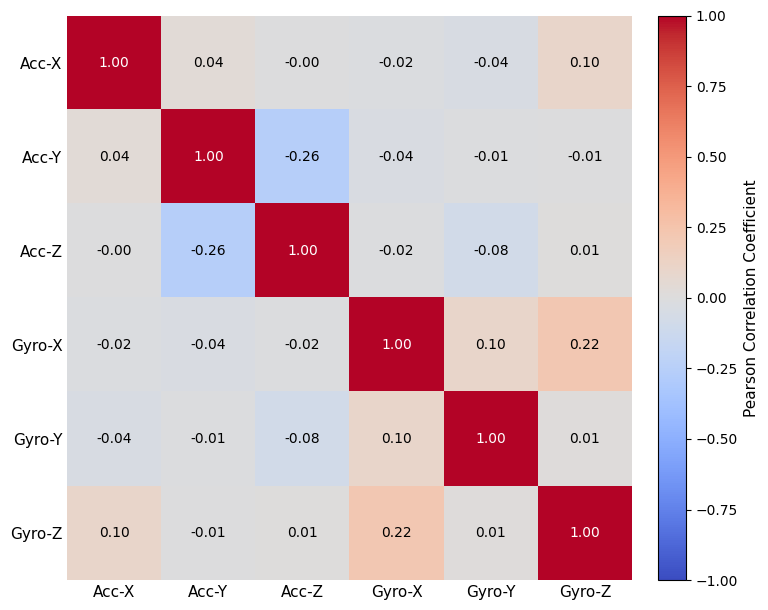

SENSOR-CHANNEL CORRELATION MATRIX
        Acc-X  Acc-Y  Acc-Z  Gyro-X  Gyro-Y  Gyro-Z
Acc-X   1.000  0.038 -0.004  -0.018  -0.039   0.096
Acc-Y   0.038  1.000 -0.263  -0.039  -0.010  -0.006
Acc-Z  -0.004 -0.263  1.000  -0.016  -0.079   0.006
Gyro-X -0.018 -0.039 -0.016   1.000   0.101   0.222
Gyro-Y -0.039 -0.010 -0.079   0.101   1.000   0.012
Gyro-Z  0.096 -0.006  0.006   0.222   0.012   1.000

Figure saved to:
/content/drive/MyDrive/GWO-BiLSTN/Sensor_Channel_Correlation_Matrix.png

STEP 14 COMPLETED


In [15]:
# ============================================================
# STEP 14: Sensor-Channel Correlation Matrix
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Sensor channels
# ------------------------------------------------------------

sensor_columns = [
    "acc_x",
    "acc_y",
    "acc_z",
    "gyro_x",
    "gyro_y",
    "gyro_z"
]


# ------------------------------------------------------------
# 2. Calculate Pearson correlation
# ------------------------------------------------------------

correlation_matrix = (
    mobifall_synced[sensor_columns]
    .corr(method="pearson")
)


# ------------------------------------------------------------
# 3. Cleaner labels for publication
# ------------------------------------------------------------

labels = [
    "Acc-X",
    "Acc-Y",
    "Acc-Z",
    "Gyro-X",
    "Gyro-Y",
    "Gyro-Z"
]


# ------------------------------------------------------------
# 4. Plot correlation matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.5, 6.2)
)

im = ax.imshow(
    correlation_matrix.values,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)


# ------------------------------------------------------------
# 5. Axis labels
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(len(labels))
)

ax.set_yticks(
    np.arange(len(labels))
)

ax.set_xticklabels(
    labels,
    fontsize=11
)

ax.set_yticklabels(
    labels,
    fontsize=11
)


# ------------------------------------------------------------
# 6. Correlation values inside cells
# ------------------------------------------------------------

for i in range(len(labels)):

    for j in range(len(labels)):

        value = correlation_matrix.iloc[i, j]

        text_color = (
            "white"
            if abs(value) > 0.55
            else "black"
        )

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=10,
            color=text_color
        )


# ------------------------------------------------------------
# 7. Color bar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson Correlation Coefficient",
    fontsize=11
)


# ------------------------------------------------------------
# 8. Clean publication layout
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    length=0
)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()


# ------------------------------------------------------------
# 9. Save high-resolution figure
# ------------------------------------------------------------

figure_path = (
    "/content/drive/MyDrive/GWO-BiLSTN/"
    "Sensor_Channel_Correlation_Matrix.png"
)

plt.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 10. Print numerical matrix
# ------------------------------------------------------------

print("=" * 65)
print("SENSOR-CHANNEL CORRELATION MATRIX")
print("=" * 65)

correlation_display = correlation_matrix.copy()

correlation_display.index = labels
correlation_display.columns = labels

print(
    correlation_display.round(3)
)

print("\nFigure saved to:")
print(figure_path)

print("\n" + "=" * 65)
print("STEP 14 COMPLETED")
print("=" * 65)

In [16]:
# ============================================================
# STEP 15: Acceleration and Gyroscope Magnitude Analysis
# ADL vs FALL
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Calculate acceleration magnitude
# ------------------------------------------------------------

mobifall_synced["acc_mag"] = np.sqrt(
    mobifall_synced["acc_x"]**2 +
    mobifall_synced["acc_y"]**2 +
    mobifall_synced["acc_z"]**2
)


# ------------------------------------------------------------
# 2. Calculate gyroscope magnitude
# ------------------------------------------------------------

mobifall_synced["gyro_mag"] = np.sqrt(
    mobifall_synced["gyro_x"]**2 +
    mobifall_synced["gyro_y"]**2 +
    mobifall_synced["gyro_z"]**2
)


# ------------------------------------------------------------
# 3. Descriptive statistics by category
# ------------------------------------------------------------

summary = (
    mobifall_synced
    .groupby("category")[["acc_mag", "gyro_mag"]]
    .agg([
        "mean",
        "std",
        "median",
        "min",
        "max"
    ])
    .round(3)
)


# ------------------------------------------------------------
# 4. Percentiles
# ------------------------------------------------------------

percentiles = (
    mobifall_synced
    .groupby("category")[["acc_mag", "gyro_mag"]]
    .quantile([0.25, 0.50, 0.75, 0.95, 0.99])
    .round(3)
)


# ------------------------------------------------------------
# 5. Print results
# ------------------------------------------------------------

print("=" * 70)
print("MAGNITUDE ANALYSIS: ADL vs FALL")
print("=" * 70)

print("\nDESCRIPTIVE STATISTICS")
print("-" * 70)

print(summary)


print("\nPERCENTILES")
print("-" * 70)

print(percentiles)


# ------------------------------------------------------------
# 6. Check for invalid values
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUALITY CHECK")
print("=" * 70)

print(
    "Missing acceleration magnitude:",
    mobifall_synced["acc_mag"].isna().sum()
)

print(
    "Missing gyroscope magnitude:",
    mobifall_synced["gyro_mag"].isna().sum()
)

print(
    "Infinite acceleration magnitude:",
    np.isinf(
        mobifall_synced["acc_mag"]
    ).sum()
)

print(
    "Infinite gyroscope magnitude:",
    np.isinf(
        mobifall_synced["gyro_mag"]
    ).sum()
)


print("\n" + "=" * 70)
print("STEP 15 COMPLETED")
print("=" * 70)

MAGNITUDE ANALYSIS: ADL vs FALL

DESCRIPTIVE STATISTICS
----------------------------------------------------------------------
         acc_mag                              gyro_mag                     \
            mean    std median    min     max     mean    std median  min   
category                                                                    
ADL       10.253  3.673  9.903  0.061  32.442    1.155  1.252  0.875  0.0   
FALL       9.882  1.799  9.711  0.342  32.521    0.436  0.945  0.042  0.0   

                  
             max  
category          
ADL       13.783  
FALL      16.069  

PERCENTILES
----------------------------------------------------------------------
               acc_mag  gyro_mag
category                        
ADL      0.25    9.339     0.059
         0.50    9.903     0.875
         0.75   10.722     1.801
         0.95   18.122     3.503
         0.99   21.967     5.216
FALL     0.25    9.611     0.022
         0.50    9.711     0.042
         0.

In [17]:
# ============================================================
# STEP 16: Recording-Level Magnitude Features
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. RMS function
# ------------------------------------------------------------

def rms(x):
    return np.sqrt(np.mean(np.square(x)))


# ------------------------------------------------------------
# 2. Calculate features for each recording
# ------------------------------------------------------------

recording_features = (
    mobifall_synced
    .groupby(
        [
            "recording_id",
            "subject",
            "category",
            "activity",
            "trial"
        ],
        as_index=False
    )
    .agg(
        acc_mean=("acc_mag", "mean"),
        acc_std=("acc_mag", "std"),
        acc_peak=("acc_mag", "max"),

        gyro_mean=("gyro_mag", "mean"),
        gyro_std=("gyro_mag", "std"),
        gyro_peak=("gyro_mag", "max")
    )
)


# ------------------------------------------------------------
# 3. Calculate RMS separately
# ------------------------------------------------------------

rms_features = (
    mobifall_synced
    .groupby("recording_id")
    .agg(
        acc_rms=(
            "acc_mag",
            lambda x: rms(x.to_numpy())
        ),
        gyro_rms=(
            "gyro_mag",
            lambda x: rms(x.to_numpy())
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. Merge RMS features
# ------------------------------------------------------------

recording_features = recording_features.merge(
    rms_features,
    on="recording_id",
    how="left"
)


# ------------------------------------------------------------
# 5. Arrange columns
# ------------------------------------------------------------

recording_features = recording_features[
    [
        "recording_id",
        "subject",
        "category",
        "activity",
        "trial",

        "acc_mean",
        "acc_std",
        "acc_rms",
        "acc_peak",

        "gyro_mean",
        "gyro_std",
        "gyro_rms",
        "gyro_peak"
    ]
]


# ------------------------------------------------------------
# 6. Summary by ADL and FALL
# ------------------------------------------------------------

feature_columns = [
    "acc_mean",
    "acc_std",
    "acc_rms",
    "acc_peak",
    "gyro_mean",
    "gyro_std",
    "gyro_rms",
    "gyro_peak"
]


feature_summary = (
    recording_features
    .groupby("category")[feature_columns]
    .median()
    .round(3)
)


# ------------------------------------------------------------
# 7. Print results
# ------------------------------------------------------------

print("=" * 75)
print("RECORDING-LEVEL FEATURE ANALYSIS")
print("=" * 75)

print("\nNumber of recordings:")
print(
    recording_features["category"]
    .value_counts()
)


print("\nMedian feature values by category:")
print(
    feature_summary.T
)


print("\nMissing values:")
print(
    recording_features[
        feature_columns
    ]
    .isna()
    .sum()
)


print("\n" + "=" * 75)
print("STEP 16 COMPLETED")
print("=" * 75)

RECORDING-LEVEL FEATURE ANALYSIS

Number of recordings:
category
ADL     342
FALL    288
Name: count, dtype: int64

Median feature values by category:
category      ADL    FALL
acc_mean    9.956   9.877
acc_std     1.863   1.776
acc_rms    10.189  10.033
acc_peak   18.955  25.804
gyro_mean   1.004   0.415
gyro_std    0.836   0.897
gyro_rms    1.323   0.992
gyro_peak   4.153   6.070

Missing values:
acc_mean     0
acc_std      0
acc_rms      0
acc_peak     0
gyro_mean    0
gyro_std     0
gyro_rms     0
gyro_peak    0
dtype: int64

STEP 16 COMPLETED


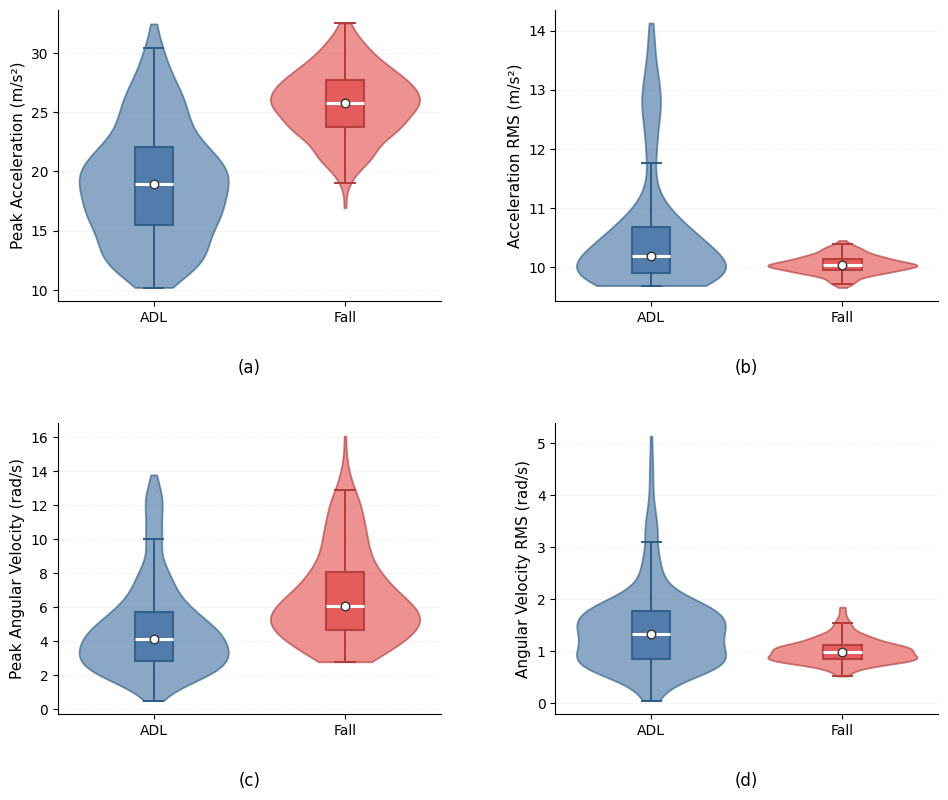

FEATURE DISTRIBUTION MEDIANS
(a) acc_peak     | ADL = 18.955 | FALL = 25.804
(b) acc_rms      | ADL = 10.189 | FALL = 10.033
(c) gyro_peak    | ADL = 4.153 | FALL = 6.070
(d) gyro_rms     | ADL = 1.323 | FALL = 0.992

PNG saved to:
/content/drive/MyDrive/GWO-BiLSTN/ADL_Fall_Feature_Distributions.png

PDF saved to:
/content/drive/MyDrive/GWO-BiLSTN/ADL_Fall_Feature_Distributions.pdf

STEP 17 COMPLETED


In [18]:
# ============================================================
# STEP 17: Recording-Level Feature Distribution
# ADL vs FALL
# Improved Publication-Quality Version
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Features to visualize
# ------------------------------------------------------------

features = [
    ("acc_peak", "Peak Acceleration (m/s²)", "(a)"),
    ("acc_rms", "Acceleration RMS (m/s²)", "(b)"),
    ("gyro_peak", "Peak Angular Velocity (rad/s)", "(c)"),
    ("gyro_rms", "Angular Velocity RMS (rad/s)", "(d)")
]


# ------------------------------------------------------------
# 2. Extract ADL and FALL data
# ------------------------------------------------------------

adl_data = recording_features[
    recording_features["category"] == "ADL"
]

fall_data = recording_features[
    recording_features["category"] == "FALL"
]


# ------------------------------------------------------------
# 3. Colors
# ------------------------------------------------------------

adl_color = "#4C78A8"
fall_color = "#E45756"

adl_edge = "#2C5D87"
fall_edge = "#B33B3A"

median_color = "#FFFFFF"


# ------------------------------------------------------------
# 4. Create 2 × 2 figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 8),
    facecolor="white"
)

axes = axes.flatten()


# ------------------------------------------------------------
# 5. Draw each feature
# ------------------------------------------------------------

for ax, (feature, ylabel, panel) in zip(
    axes,
    features
):

    data = [
        adl_data[feature].values,
        fall_data[feature].values
    ]


    # ========================================================
    # Violin plot
    # ========================================================

    violin = ax.violinplot(
        data,
        positions=[1, 2],
        widths=0.78,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )


    # ADL violin
    violin["bodies"][0].set_facecolor(
        adl_color
    )

    violin["bodies"][0].set_edgecolor(
        adl_edge
    )

    violin["bodies"][0].set_linewidth(
        1.3
    )

    violin["bodies"][0].set_alpha(
        0.65
    )


    # FALL violin
    violin["bodies"][1].set_facecolor(
        fall_color
    )

    violin["bodies"][1].set_edgecolor(
        fall_edge
    )

    violin["bodies"][1].set_linewidth(
        1.3
    )

    violin["bodies"][1].set_alpha(
        0.65
    )


    # ========================================================
    # Boxplot
    # ========================================================

    box = ax.boxplot(
        data,
        positions=[1, 2],
        widths=0.20,
        patch_artist=True,
        showfliers=False,

        medianprops=dict(
            color=median_color,
            linewidth=2.2
        ),

        whiskerprops=dict(
            linewidth=1.4
        ),

        capprops=dict(
            linewidth=1.4
        )
    )


    # --------------------------------------------------------
    # Give each box its own attractive color
    # --------------------------------------------------------

    box["boxes"][0].set_facecolor(
        adl_color
    )

    box["boxes"][0].set_edgecolor(
        adl_edge
    )

    box["boxes"][0].set_linewidth(
        1.5
    )

    box["boxes"][0].set_alpha(
        0.90
    )


    box["boxes"][1].set_facecolor(
        fall_color
    )

    box["boxes"][1].set_edgecolor(
        fall_edge
    )

    box["boxes"][1].set_linewidth(
        1.5
    )

    box["boxes"][1].set_alpha(
        0.90
    )


    # --------------------------------------------------------
    # Whisker colors
    # --------------------------------------------------------

    box["whiskers"][0].set_color(
        adl_edge
    )

    box["whiskers"][1].set_color(
        adl_edge
    )

    box["caps"][0].set_color(
        adl_edge
    )

    box["caps"][1].set_color(
        adl_edge
    )


    box["whiskers"][2].set_color(
        fall_edge
    )

    box["whiskers"][3].set_color(
        fall_edge
    )

    box["caps"][2].set_color(
        fall_edge
    )

    box["caps"][3].set_color(
        fall_edge
    )


    # ========================================================
    # Median points
    # ========================================================

    medians = [
        np.median(data[0]),
        np.median(data[1])
    ]

    ax.scatter(
        [1, 2],
        medians,
        s=38,
        facecolor="white",
        edgecolor="#333333",
        linewidth=1.0,
        zorder=6
    )


    # ========================================================
    # Axis formatting
    # ========================================================

    ax.set_xticks(
        [1, 2]
    )

    ax.set_xticklabels(
        ["ADL", "Fall"],
        fontsize=11
    )

    ax.set_ylabel(
        ylabel,
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )


    # --------------------------------------------------------
    # Very light horizontal reference lines
    # --------------------------------------------------------

    ax.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.20
    )

    ax.set_axisbelow(True)


    # --------------------------------------------------------
    # Clean borders
    # --------------------------------------------------------

    ax.spines["top"].set_visible(
        False
    )

    ax.spines["right"].set_visible(
        False
    )

    ax.spines["left"].set_linewidth(
        0.8
    )

    ax.spines["bottom"].set_linewidth(
        0.8
    )


    # ========================================================
    # Panel label
    # ========================================================

    ax.text(
        0.5,
        -0.20,
        panel,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=12
    )


# ------------------------------------------------------------
# 6. Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.98,
    bottom=0.10,
    wspace=0.30,
    hspace=0.42
)


# ------------------------------------------------------------
# 7. Save high-resolution figure
# ------------------------------------------------------------

png_path = (
    "/content/drive/MyDrive/GWO-BiLSTN/"
    "ADL_Fall_Feature_Distributions.png"
)

pdf_path = (
    "/content/drive/MyDrive/GWO-BiLSTN/"
    "ADL_Fall_Feature_Distributions.pdf"
)


plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ------------------------------------------------------------
# 8. Print median values
# ------------------------------------------------------------

print("=" * 70)
print("FEATURE DISTRIBUTION MEDIANS")
print("=" * 70)

for feature, ylabel, panel in features:

    adl_median = (
        adl_data[feature].median()
    )

    fall_median = (
        fall_data[feature].median()
    )

    print(
        f"{panel} {feature:12s} | "
        f"ADL = {adl_median:.3f} | "
        f"FALL = {fall_median:.3f}"
    )


print("\nPNG saved to:")
print(png_path)

print("\nPDF saved to:")
print(pdf_path)

print("\n" + "=" * 70)
print("STEP 17 COMPLETED")
print("=" * 70)

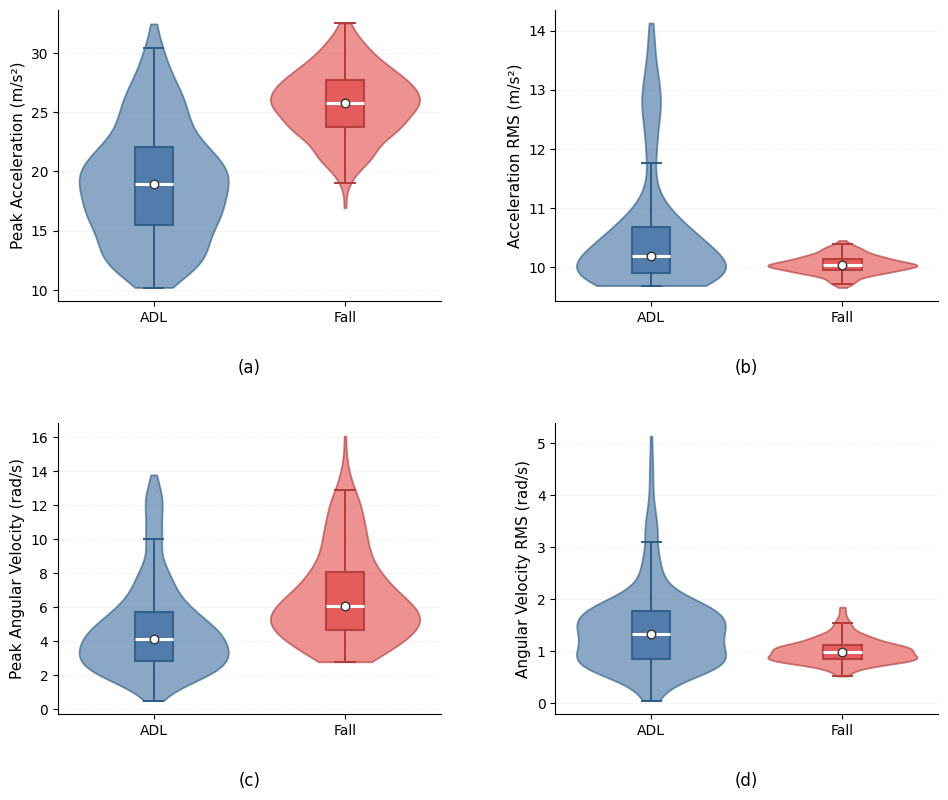

FEATURE DISTRIBUTION MEDIANS
(a) acc_peak     | ADL = 18.955 | FALL = 25.804
(b) acc_rms      | ADL = 10.189 | FALL = 10.033
(c) gyro_peak    | ADL = 4.153 | FALL = 6.070
(d) gyro_rms     | ADL = 1.323 | FALL = 0.992

PNG saved to:
/content/drive/MyDrive/GWO-BiLSTN/ADL_Fall_Feature_Distributions.png

PDF saved to:
/content/drive/MyDrive/GWO-BiLSTN/ADL_Fall_Feature_Distributions.pdf

STEP 17 COMPLETED


In [19]:
# ============================================================
# STEP 17: Recording-Level Feature Distribution
# ADL vs FALL
# Improved Publication-Quality Version
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Features to visualize
# ------------------------------------------------------------

features = [
    ("acc_peak", "Peak Acceleration (m/s²)", "(a)"),
    ("acc_rms", "Acceleration RMS (m/s²)", "(b)"),
    ("gyro_peak", "Peak Angular Velocity (rad/s)", "(c)"),
    ("gyro_rms", "Angular Velocity RMS (rad/s)", "(d)")
]


# ------------------------------------------------------------
# 2. Extract ADL and FALL data
# ------------------------------------------------------------

adl_data = recording_features[
    recording_features["category"] == "ADL"
]

fall_data = recording_features[
    recording_features["category"] == "FALL"
]


# ------------------------------------------------------------
# 3. Colors
# ------------------------------------------------------------

adl_color = "#4C78A8"
fall_color = "#E45756"

adl_edge = "#2C5D87"
fall_edge = "#B33B3A"

median_color = "#FFFFFF"


# ------------------------------------------------------------
# 4. Create 2 × 2 figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 8),
    facecolor="white"
)

axes = axes.flatten()


# ------------------------------------------------------------
# 5. Draw each feature
# ------------------------------------------------------------

for ax, (feature, ylabel, panel) in zip(
    axes,
    features
):

    data = [
        adl_data[feature].values,
        fall_data[feature].values
    ]


    # ========================================================
    # Violin plot
    # ========================================================

    violin = ax.violinplot(
        data,
        positions=[1, 2],
        widths=0.78,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )


    # ADL violin
    violin["bodies"][0].set_facecolor(
        adl_color
    )

    violin["bodies"][0].set_edgecolor(
        adl_edge
    )

    violin["bodies"][0].set_linewidth(
        1.3
    )

    violin["bodies"][0].set_alpha(
        0.65
    )


    # FALL violin
    violin["bodies"][1].set_facecolor(
        fall_color
    )

    violin["bodies"][1].set_edgecolor(
        fall_edge
    )

    violin["bodies"][1].set_linewidth(
        1.3
    )

    violin["bodies"][1].set_alpha(
        0.65
    )


    # ========================================================
    # Boxplot
    # ========================================================

    box = ax.boxplot(
        data,
        positions=[1, 2],
        widths=0.20,
        patch_artist=True,
        showfliers=False,

        medianprops=dict(
            color=median_color,
            linewidth=2.2
        ),

        whiskerprops=dict(
            linewidth=1.4
        ),

        capprops=dict(
            linewidth=1.4
        )
    )


    # --------------------------------------------------------
    # Give each box its own attractive color
    # --------------------------------------------------------

    box["boxes"][0].set_facecolor(
        adl_color
    )

    box["boxes"][0].set_edgecolor(
        adl_edge
    )

    box["boxes"][0].set_linewidth(
        1.5
    )

    box["boxes"][0].set_alpha(
        0.90
    )


    box["boxes"][1].set_facecolor(
        fall_color
    )

    box["boxes"][1].set_edgecolor(
        fall_edge
    )

    box["boxes"][1].set_linewidth(
        1.5
    )

    box["boxes"][1].set_alpha(
        0.90
    )


    # --------------------------------------------------------
    # Whisker colors
    # --------------------------------------------------------

    box["whiskers"][0].set_color(
        adl_edge
    )

    box["whiskers"][1].set_color(
        adl_edge
    )

    box["caps"][0].set_color(
        adl_edge
    )

    box["caps"][1].set_color(
        adl_edge
    )


    box["whiskers"][2].set_color(
        fall_edge
    )

    box["whiskers"][3].set_color(
        fall_edge
    )

    box["caps"][2].set_color(
        fall_edge
    )

    box["caps"][3].set_color(
        fall_edge
    )


    # ========================================================
    # Median points
    # ========================================================

    medians = [
        np.median(data[0]),
        np.median(data[1])
    ]

    ax.scatter(
        [1, 2],
        medians,
        s=38,
        facecolor="white",
        edgecolor="#333333",
        linewidth=1.0,
        zorder=6
    )


    # ========================================================
    # Axis formatting
    # ========================================================

    ax.set_xticks(
        [1, 2]
    )

    ax.set_xticklabels(
        ["ADL", "Fall"],
        fontsize=11
    )

    ax.set_ylabel(
        ylabel,
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )


    # --------------------------------------------------------
    # Very light horizontal reference lines
    # --------------------------------------------------------

    ax.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.20
    )

    ax.set_axisbelow(True)


    # --------------------------------------------------------
    # Clean borders
    # --------------------------------------------------------

    ax.spines["top"].set_visible(
        False
    )

    ax.spines["right"].set_visible(
        False
    )

    ax.spines["left"].set_linewidth(
        0.8
    )

    ax.spines["bottom"].set_linewidth(
        0.8
    )


    # ========================================================
    # Panel label
    # ========================================================

    ax.text(
        0.5,
        -0.20,
        panel,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=12
    )


# ------------------------------------------------------------
# 6. Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.98,
    bottom=0.10,
    wspace=0.30,
    hspace=0.42
)


# ------------------------------------------------------------
# 7. Save high-resolution figure
# ------------------------------------------------------------

png_path = (
    "/content/drive/MyDrive/GWO-BiLSTN/"
    "ADL_Fall_Feature_Distributions.png"
)

pdf_path = (
    "/content/drive/MyDrive/GWO-BiLSTN/"
    "ADL_Fall_Feature_Distributions.pdf"
)


plt.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ------------------------------------------------------------
# 8. Print median values
# ------------------------------------------------------------

print("=" * 70)
print("FEATURE DISTRIBUTION MEDIANS")
print("=" * 70)

for feature, ylabel, panel in features:

    adl_median = (
        adl_data[feature].median()
    )

    fall_median = (
        fall_data[feature].median()
    )

    print(
        f"{panel} {feature:12s} | "
        f"ADL = {adl_median:.3f} | "
        f"FALL = {fall_median:.3f}"
    )


print("\nPNG saved to:")
print(png_path)

print("\nPDF saved to:")
print(pdf_path)

print("\n" + "=" * 70)
print("STEP 17 COMPLETED")
print("=" * 70)

In [20]:
# ============================================================
# STEP 18: Reproducible Subject-Independent Split
# ============================================================

import numpy as np


# ------------------------------------------------------------
# 1. Subjects by coverage type
# ------------------------------------------------------------

complete_subjects = np.array(
    [2, 3, 4, 5, 7, 8, 9, 10, 11]
)

fall_only_subjects = np.array(
    [1, 6, 12, 13, 14, 15, 16, 17,
     18, 19, 20, 21, 29, 30, 31]
)


# ------------------------------------------------------------
# 2. Reproducible shuffle
# ------------------------------------------------------------

rng = np.random.default_rng(42)

complete_shuffled = rng.permutation(
    complete_subjects
)

fall_only_shuffled = rng.permutation(
    fall_only_subjects
)


# ------------------------------------------------------------
# 3. Split complete subjects
#
# 5 Train
# 2 Validation
# 2 Test
# ------------------------------------------------------------

train_complete = complete_shuffled[:5]

val_complete = complete_shuffled[5:7]

test_complete = complete_shuffled[7:9]


# ------------------------------------------------------------
# 4. Split FALL-only subjects
#
# 11 Train
# 2 Validation
# 2 Test
# ------------------------------------------------------------

train_fall_only = fall_only_shuffled[:11]

val_fall_only = fall_only_shuffled[11:13]

test_fall_only = fall_only_shuffled[13:15]


# ------------------------------------------------------------
# 5. Combine subject groups
# ------------------------------------------------------------

train_subjects = sorted(
    np.concatenate([
        train_complete,
        train_fall_only
    ]).tolist()
)

val_subjects = sorted(
    np.concatenate([
        val_complete,
        val_fall_only
    ]).tolist()
)

test_subjects = sorted(
    np.concatenate([
        test_complete,
        test_fall_only
    ]).tolist()
)


# ------------------------------------------------------------
# 6. Leakage checks
# ------------------------------------------------------------

train_set = set(train_subjects)
val_set = set(val_subjects)
test_set = set(test_subjects)

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

assert (
    train_set | val_set | test_set
) == set(subject_summary.index)


# ------------------------------------------------------------
# 7. Display split
# ------------------------------------------------------------

print("=" * 70)
print("SUBJECT-INDEPENDENT SPLIT")
print("=" * 70)

print("\nTRAIN")
print("Subjects:", train_subjects)
print("Number  :", len(train_subjects))

print("\nVALIDATION")
print("Subjects:", val_subjects)
print("Number  :", len(val_subjects))

print("\nTEST")
print("Subjects:", test_subjects)
print("Number  :", len(test_subjects))


print("\n" + "=" * 70)
print("COVERAGE")
print("=" * 70)

print(
    "Train complete subjects     :",
    sorted(train_complete.tolist())
)

print(
    "Train fall-only subjects    :",
    sorted(train_fall_only.tolist())
)

print(
    "\nValidation complete subjects:",
    sorted(val_complete.tolist())
)

print(
    "Validation fall-only        :",
    sorted(val_fall_only.tolist())
)

print(
    "\nTest complete subjects      :",
    sorted(test_complete.tolist())
)

print(
    "Test fall-only subjects     :",
    sorted(test_fall_only.tolist())
)


print("\n" + "=" * 70)
print("LEAKAGE CHECK")
print("=" * 70)

print(
    "Train ∩ Validation:",
    train_set.intersection(val_set)
)

print(
    "Train ∩ Test:",
    train_set.intersection(test_set)
)

print(
    "Validation ∩ Test:",
    val_set.intersection(test_set)
)

print("\nSTEP 18 COMPLETED")

SUBJECT-INDEPENDENT SPLIT

TRAIN
Subjects: [1, 2, 4, 5, 7, 10, 12, 13, 14, 16, 17, 18, 19, 20, 30, 31]
Number  : 16

VALIDATION
Subjects: [3, 6, 9, 29]
Number  : 4

TEST
Subjects: [8, 11, 15, 21]
Number  : 4

COVERAGE
Train complete subjects     : [2, 4, 5, 7, 10]
Train fall-only subjects    : [1, 12, 13, 14, 16, 17, 18, 19, 20, 30, 31]

Validation complete subjects: [3, 9]
Validation fall-only        : [6, 29]

Test complete subjects      : [8, 11]
Test fall-only subjects     : [15, 21]

LEAKAGE CHECK
Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()

STEP 18 COMPLETED


In [21]:
# ============================================================
# STEP 19: Preview Sliding-Window Distribution
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Window configuration
# ------------------------------------------------------------

TARGET_FS = 100

WINDOW_SECONDS = 2.0
OVERLAP = 0.50

WINDOW_SIZE = int(
    TARGET_FS * WINDOW_SECONDS
)

STEP_SIZE = int(
    WINDOW_SIZE * (1 - OVERLAP)
)


print("=" * 70)
print("WINDOW CONFIGURATION")
print("=" * 70)

print(
    f"Sampling frequency : {TARGET_FS} Hz"
)

print(
    f"Window duration    : {WINDOW_SECONDS:.1f} seconds"
)

print(
    f"Window size        : {WINDOW_SIZE} samples"
)

print(
    f"Overlap            : {OVERLAP * 100:.0f}%"
)

print(
    f"Step size          : {STEP_SIZE} samples"
)

print(
    f"Model input shape  : ({WINDOW_SIZE}, 6)"
)


# ------------------------------------------------------------
# 2. Assign split to recording summary
# ------------------------------------------------------------

def get_split(subject):

    if subject in train_subjects:
        return "Train"

    elif subject in val_subjects:
        return "Validation"

    elif subject in test_subjects:
        return "Test"

    return "Unknown"


processing_summary_df["split"] = (
    processing_summary_df["subject"]
    .apply(get_split)
)


# ------------------------------------------------------------
# 3. Calculate number of windows per recording
# ------------------------------------------------------------

def count_windows(n_samples):

    if n_samples < WINDOW_SIZE:
        return 0

    return (
        (n_samples - WINDOW_SIZE)
        // STEP_SIZE
    ) + 1


processing_summary_df[
    "n_windows"
] = (
    processing_summary_df[
        "synchronized_samples"
    ]
    .apply(count_windows)
)


# ------------------------------------------------------------
# 4. Total windows by split
# ------------------------------------------------------------

windows_by_split = (
    processing_summary_df
    .groupby("split")["n_windows"]
    .sum()
)


print("\n" + "=" * 70)
print("WINDOWS BY SPLIT")
print("=" * 70)

print(windows_by_split)


# ------------------------------------------------------------
# 5. Windows by split and category
# ------------------------------------------------------------

windows_by_category = (
    processing_summary_df
    .groupby(
        ["split", "category"]
    )["n_windows"]
    .sum()
    .unstack(fill_value=0)
)


print("\n" + "=" * 70)
print("WINDOWS BY SPLIT AND CATEGORY")
print("=" * 70)

print(windows_by_category)


# ------------------------------------------------------------
# 6. Percentage distribution
# ------------------------------------------------------------

category_percentage = (
    windows_by_category
    .div(
        windows_by_category.sum(axis=1),
        axis=0
    )
    * 100
)


print("\nCategory percentage:")
print(
    category_percentage.round(2)
)


# ------------------------------------------------------------
# 7. Windows by activity
# ------------------------------------------------------------

windows_by_activity = (
    processing_summary_df
    .groupby(
        ["split", "category", "activity"]
    )["n_windows"]
    .sum()
)


print("\n" + "=" * 70)
print("WINDOWS BY ACTIVITY")
print("=" * 70)

print(windows_by_activity)


# ------------------------------------------------------------
# 8. Check recordings too short for windowing
# ------------------------------------------------------------

short_recordings = (
    processing_summary_df[
        processing_summary_df[
            "n_windows"
        ] == 0
    ]
)


print("\n" + "=" * 70)
print("WINDOWING QUALITY CHECK")
print("=" * 70)

print(
    "Recordings producing zero windows:",
    len(short_recordings)
)


# ------------------------------------------------------------
# 9. Overall total
# ------------------------------------------------------------

total_windows = (
    processing_summary_df[
        "n_windows"
    ].sum()
)


print(
    "\nTotal windows:",
    f"{total_windows:,}"
)


print("\n" + "=" * 70)
print("STEP 19 COMPLETED")
print("=" * 70)

WINDOW CONFIGURATION
Sampling frequency : 100 Hz
Window duration    : 2.0 seconds
Window size        : 200 samples
Overlap            : 50%
Step size          : 100 samples
Model input shape  : (200, 6)

WINDOWS BY SPLIT
split
Test          2249
Train         6198
Validation    2256
Name: n_windows, dtype: int64

WINDOWS BY SPLIT AND CATEGORY
category     ADL  FALL
split                 
Test        1865   384
Train       4662  1536
Validation  1864   392

Category percentage:
category      ADL   FALL
split                   
Test        82.93  17.07
Train       75.22  24.78
Validation  82.62  17.38

WINDOWS BY ACTIVITY
split       category  activity
Test        ADL       CSI           48
                      CSO           48
                      JOG          168
                      JUM          168
                      SCH           48
                      STD          597
                      STN           96
                      STU           96
                      WAL    

In [22]:
# ============================================================
# STEP 20: Examine Fall Impact Locations
# ============================================================

fall_peak_info = []

for rec in synchronized_recordings:

    if rec["category"].iloc[0] != "FALL":
        continue

    # Acceleration magnitude
    acc_mag = np.sqrt(
        rec["acc_x"].values ** 2 +
        rec["acc_y"].values ** 2 +
        rec["acc_z"].values ** 2
    )

    # Peak acceleration location
    peak_idx = np.argmax(acc_mag)

    peak_time = rec["time"].iloc[peak_idx]

    duration = (
        rec["time"].iloc[-1] -
        rec["time"].iloc[0]
    )

    relative_position = (
        peak_idx / (len(rec) - 1)
    )

    fall_peak_info.append({
        "subject": rec["subject"].iloc[0],
        "activity": rec["activity"].iloc[0],
        "trial": rec["trial"].iloc[0],
        "samples": len(rec),
        "duration_sec": duration,
        "peak_acc": acc_mag[peak_idx],
        "peak_time_sec": peak_time,
        "relative_peak_position": relative_position
    })


fall_peak_df = pd.DataFrame(fall_peak_info)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("=" * 70)
print("FALL IMPACT LOCATION ANALYSIS")
print("=" * 70)

print("\nNumber of fall recordings:")
print(len(fall_peak_df))


print("\nPeak acceleration magnitude:")
print(
    fall_peak_df["peak_acc"]
    .describe()
    .round(3)
)


print("\nRelative peak position within recording:")
print(
    fall_peak_df["relative_peak_position"]
    .describe()
    .round(3)
)


print("\nPeak position percentages:")

print(
    (
        fall_peak_df["relative_peak_position"]
        * 100
    )
    .describe()
    .round(2)
)


print("\nMedian peak position by fall activity:")

print(
    fall_peak_df
    .groupby("activity")[
        "relative_peak_position"
    ]
    .median()
    .mul(100)
    .round(2)
)


print("\n" + "=" * 70)
print("STEP 20 COMPLETED")
print("=" * 70)

FALL IMPACT LOCATION ANALYSIS

Number of fall recordings:
288

Peak acceleration magnitude:
count    288.000
mean      25.751
std        2.866
min       16.931
25%       23.719
50%       25.804
75%       27.695
max       32.521
Name: peak_acc, dtype: float64

Relative peak position within recording:
count    288.000
mean       0.221
std        0.041
min        0.132
25%        0.194
50%        0.215
75%        0.246
max        0.357
Name: relative_peak_position, dtype: float64

Peak position percentages:
count    288.00
mean      22.13
std        4.15
min       13.16
25%       19.45
50%       21.52
75%       24.62
max       35.69
Name: relative_peak_position, dtype: float64

Median peak position by fall activity:
activity
BSC    21.62
FKL    21.37
FOL    23.16
SDL    20.46
Name: relative_peak_position, dtype: float64

STEP 20 COMPLETED


In [23]:
# ============================================================
# STEP 21: Peak-Centered FALL Window Extraction
# ============================================================

FALL_WINDOW_SIZE = 200
HALF_WINDOW = FALL_WINDOW_SIZE // 2

fall_windows = []
fall_metadata = []


# ------------------------------------------------------------
# Extract one impact-centered window per fall recording
# ------------------------------------------------------------

for rec in synchronized_recordings:

    if rec["category"].iloc[0] != "FALL":
        continue

    # Acceleration magnitude
    acc_mag = np.sqrt(
        rec["acc_x"].values ** 2 +
        rec["acc_y"].values ** 2 +
        rec["acc_z"].values ** 2
    )

    # Impact location
    peak_idx = np.argmax(acc_mag)

    start = peak_idx - HALF_WINDOW
    end = start + FALL_WINDOW_SIZE


    # --------------------------------------------------------
    # Boundary protection
    # --------------------------------------------------------

    if start < 0:
        start = 0
        end = FALL_WINDOW_SIZE

    if end > len(rec):
        end = len(rec)
        start = end - FALL_WINDOW_SIZE


    # --------------------------------------------------------
    # Extract six sensor channels
    # --------------------------------------------------------

    window = rec[
        [
            "acc_x",
            "acc_y",
            "acc_z",
            "gyro_x",
            "gyro_y",
            "gyro_z"
        ]
    ].iloc[start:end].values


    # Safety check
    if len(window) != FALL_WINDOW_SIZE:
        continue


    # --------------------------------------------------------
    # Subject split
    # --------------------------------------------------------

    subject = int(
        rec["subject"].iloc[0]
    )

    if subject in train_subjects:
        split_name = "Train"

    elif subject in val_subjects:
        split_name = "Validation"

    elif subject in test_subjects:
        split_name = "Test"

    else:
        split_name = "Unknown"


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    fall_windows.append(window)

    fall_metadata.append({
        "subject": subject,
        "activity": rec["activity"].iloc[0],
        "trial": rec["trial"].iloc[0],
        "split": split_name,
        "peak_index": peak_idx,
        "window_start": start,
        "window_end": end
    })


# ------------------------------------------------------------
# Convert
# ------------------------------------------------------------

fall_windows = np.asarray(
    fall_windows,
    dtype=np.float32
)

fall_metadata_df = pd.DataFrame(
    fall_metadata
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 70)
print("PEAK-CENTERED FALL WINDOWS")
print("=" * 70)

print(
    "\nWindow array shape:",
    fall_windows.shape
)

print(
    "\nWindows by split:"
)

print(
    fall_metadata_df[
        "split"
    ].value_counts()
)


print(
    "\nWindows by activity:"
)

print(
    pd.crosstab(
        fall_metadata_df["split"],
        fall_metadata_df["activity"]
    )
)


print(
    "\nWindow length check:"
)

print(
    "Expected:",
    FALL_WINDOW_SIZE
)

print(
    "Actual:",
    fall_windows.shape[1]
)


print("\n" + "=" * 70)
print("STEP 21 COMPLETED")
print("=" * 70)

PEAK-CENTERED FALL WINDOWS

Window array shape: (288, 200, 6)

Windows by split:
split
Train         192
Validation     48
Test           48
Name: count, dtype: int64

Windows by activity:
activity    BSC  FKL  FOL  SDL
split                         
Test         12   12   12   12
Train        48   48   48   48
Validation   12   12   12   12

Window length check:
Expected: 200
Actual: 200

STEP 21 COMPLETED


In [24]:
# ============================================================
# STEP 22: Generate ADL Candidate Windows
# ============================================================

ADL_WINDOW_SIZE = 200
ADL_STEP_SIZE = 100

adl_windows = []
adl_metadata = []


# ------------------------------------------------------------
# Generate sliding windows from ADL recordings
# ------------------------------------------------------------

for rec in synchronized_recordings:

    if rec["category"].iloc[0] != "ADL":
        continue


    # --------------------------------------------------------
    # Recording information
    # --------------------------------------------------------

    subject = int(
        rec["subject"].iloc[0]
    )

    activity = rec[
        "activity"
    ].iloc[0]

    trial = rec[
        "trial"
    ].iloc[0]


    # --------------------------------------------------------
    # Determine split
    # --------------------------------------------------------

    if subject in train_subjects:
        split_name = "Train"

    elif subject in val_subjects:
        split_name = "Validation"

    elif subject in test_subjects:
        split_name = "Test"

    else:
        split_name = "Unknown"


    # --------------------------------------------------------
    # Six sensor channels
    # --------------------------------------------------------

    sensor_data = rec[
        [
            "acc_x",
            "acc_y",
            "acc_z",
            "gyro_x",
            "gyro_y",
            "gyro_z"
        ]
    ].values


    # --------------------------------------------------------
    # Sliding windows
    # --------------------------------------------------------

    for start in range(
        0,
        len(sensor_data) - ADL_WINDOW_SIZE + 1,
        ADL_STEP_SIZE
    ):

        end = start + ADL_WINDOW_SIZE

        window = sensor_data[
            start:end
        ]


        # Safety check
        if len(window) != ADL_WINDOW_SIZE:
            continue


        # ----------------------------------------------------
        # Store window
        # ----------------------------------------------------

        adl_windows.append(
            window
        )

        adl_metadata.append({
            "subject": subject,
            "activity": activity,
            "trial": trial,
            "split": split_name,
            "window_start": start,
            "window_end": end
        })


# ------------------------------------------------------------
# Convert to arrays/dataframe
# ------------------------------------------------------------

adl_windows = np.asarray(
    adl_windows,
    dtype=np.float32
)

adl_metadata_df = pd.DataFrame(
    adl_metadata
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 70)
print("ADL CANDIDATE WINDOWS")
print("=" * 70)

print(
    "\nWindow array shape:",
    adl_windows.shape
)


print("\nWindows by split:")

print(
    adl_metadata_df[
        "split"
    ].value_counts()
)


print("\nWindows by activity and split:")

print(
    pd.crosstab(
        adl_metadata_df["activity"],
        adl_metadata_df["split"]
    )
)


print("\nWindow length:")
print(
    adl_windows.shape[1]
)

print(
    "Number of channels:",
    adl_windows.shape[2]
)


print("\n" + "=" * 70)
print("STEP 22 COMPLETED")
print("=" * 70)

ADL CANDIDATE WINDOWS

Window array shape: (8391, 200, 6)

Windows by split:
split
Train         4662
Test          1865
Validation    1864
Name: count, dtype: int64

Windows by activity and split:
split     Test  Train  Validation
activity                         
CSI         48    121          48
CSO         48    120          48
JOG        168    422         168
JUM        168    420         168
SCH         48    120          48
STD        597   1491         596
STN         96    240          96
STU         96    238          96
WAL        596   1490         596

Window length:
200
Number of channels: 6

STEP 22 COMPLETED


In [25]:
# ============================================================
# STEP 23: Balance Training ADL Candidate Windows
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

BALANCE_SEED = 42
rng = np.random.default_rng(BALANCE_SEED)


# ------------------------------------------------------------
# 2. Maximum training windows per ADL activity
# ------------------------------------------------------------

MAX_ADL_PER_ACTIVITY = 192


# ------------------------------------------------------------
# 3. Identify training ADL windows
# ------------------------------------------------------------

train_indices = np.where(
    adl_metadata_df["split"].values == "Train"
)[0]


selected_train_indices = []


# ------------------------------------------------------------
# 4. Sample each ADL activity independently
# ------------------------------------------------------------

activities = sorted(
    adl_metadata_df.loc[
        train_indices,
        "activity"
    ].unique()
)


for activity in activities:

    activity_indices = np.where(
        (
            adl_metadata_df["split"].values
            == "Train"
        )
        &
        (
            adl_metadata_df["activity"].values
            == activity
        )
    )[0]


    n_available = len(
        activity_indices
    )


    n_select = min(
        n_available,
        MAX_ADL_PER_ACTIVITY
    )


    selected = rng.choice(
        activity_indices,
        size=n_select,
        replace=False
    )


    selected_train_indices.extend(
        selected.tolist()
    )


# ------------------------------------------------------------
# 5. Sort indices for reproducibility
# ------------------------------------------------------------

selected_train_indices = np.array(
    sorted(selected_train_indices)
)


# ------------------------------------------------------------
# 6. Create balanced training ADL set
# ------------------------------------------------------------

adl_train_balanced = (
    adl_windows[
        selected_train_indices
    ]
)

adl_train_metadata_balanced = (
    adl_metadata_df
    .iloc[selected_train_indices]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Keep validation and test unchanged
# ------------------------------------------------------------

val_indices = np.where(
    adl_metadata_df["split"].values
    == "Validation"
)[0]

test_indices = np.where(
    adl_metadata_df["split"].values
    == "Test"
)[0]


adl_val = adl_windows[
    val_indices
]

adl_test = adl_windows[
    test_indices
]


adl_val_metadata = (
    adl_metadata_df
    .iloc[val_indices]
    .reset_index(drop=True)
)

adl_test_metadata = (
    adl_metadata_df
    .iloc[test_indices]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. Display training distribution
# ------------------------------------------------------------

print("=" * 70)
print("BALANCED TRAINING ADL WINDOWS")
print("=" * 70)


print("\nBefore balancing:")

print(
    adl_metadata_df[
        adl_metadata_df["split"]
        == "Train"
    ]["activity"]
    .value_counts()
    .sort_index()
)


print("\nAfter balancing:")

print(
    adl_train_metadata_balanced[
        "activity"
    ]
    .value_counts()
    .sort_index()
)


print(
    "\nBalanced training ADL shape:",
    adl_train_balanced.shape
)


# ------------------------------------------------------------
# 9. Validation and test remain untouched
# ------------------------------------------------------------

print(
    "\nValidation ADL shape:",
    adl_val.shape
)

print(
    "Test ADL shape:",
    adl_test.shape
)


# ------------------------------------------------------------
# 10. Final checks
# ------------------------------------------------------------

print("\nMissing values:")

print(
    "Train:",
    np.isnan(adl_train_balanced).sum()
)

print(
    "Validation:",
    np.isnan(adl_val).sum()
)

print(
    "Test:",
    np.isnan(adl_test).sum()
)


print("\n" + "=" * 70)
print("STEP 23 COMPLETED")
print("=" * 70)

BALANCED TRAINING ADL WINDOWS

Before balancing:
activity
CSI     121
CSO     120
JOG     422
JUM     420
SCH     120
STD    1491
STN     240
STU     238
WAL    1490
Name: count, dtype: int64

After balancing:
activity
CSI    121
CSO    120
JOG    192
JUM    192
SCH    120
STD    192
STN    192
STU    192
WAL    192
Name: count, dtype: int64

Balanced training ADL shape: (1513, 200, 6)

Validation ADL shape: (1864, 200, 6)
Test ADL shape: (1865, 200, 6)

Missing values:
Train: 0
Validation: 0
Test: 0

STEP 23 COMPLETED


In [26]:
# ============================================================
# STEP 24: Build Unified Train / Validation / Test Datasets
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Separate FALL windows by split
# ------------------------------------------------------------

fall_train_idx = np.where(
    fall_metadata_df["split"].values == "Train"
)[0]

fall_val_idx = np.where(
    fall_metadata_df["split"].values == "Validation"
)[0]

fall_test_idx = np.where(
    fall_metadata_df["split"].values == "Test"
)[0]


fall_train = fall_windows[fall_train_idx]
fall_val = fall_windows[fall_val_idx]
fall_test = fall_windows[fall_test_idx]


fall_train_meta = (
    fall_metadata_df
    .iloc[fall_train_idx]
    .reset_index(drop=True)
)

fall_val_meta = (
    fall_metadata_df
    .iloc[fall_val_idx]
    .reset_index(drop=True)
)

fall_test_meta = (
    fall_metadata_df
    .iloc[fall_test_idx]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Add binary labels to ADL metadata
# ------------------------------------------------------------

adl_train_meta = (
    adl_train_metadata_balanced.copy()
)

adl_val_meta = (
    adl_val_metadata.copy()
)

adl_test_meta = (
    adl_test_metadata.copy()
)


adl_train_meta["binary_label"] = 0
adl_val_meta["binary_label"] = 0
adl_test_meta["binary_label"] = 0


# ------------------------------------------------------------
# 3. Add binary labels to FALL metadata
# ------------------------------------------------------------

fall_train_meta["binary_label"] = 1
fall_val_meta["binary_label"] = 1
fall_test_meta["binary_label"] = 1


# ------------------------------------------------------------
# 4. Combine sensor windows
# ------------------------------------------------------------

X_train_raw = np.concatenate(
    [
        adl_train_balanced,
        fall_train
    ],
    axis=0
)

X_val_raw = np.concatenate(
    [
        adl_val,
        fall_val
    ],
    axis=0
)

X_test_raw = np.concatenate(
    [
        adl_test,
        fall_test
    ],
    axis=0
)


# ------------------------------------------------------------
# 5. Combine metadata
# ------------------------------------------------------------

train_meta = pd.concat(
    [
        adl_train_meta,
        fall_train_meta
    ],
    ignore_index=True
)

val_meta = pd.concat(
    [
        adl_val_meta,
        fall_val_meta
    ],
    ignore_index=True
)

test_meta = pd.concat(
    [
        adl_test_meta,
        fall_test_meta
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# 6. Binary labels
# ------------------------------------------------------------

y_train_binary = (
    train_meta["binary_label"]
    .to_numpy(dtype=np.int32)
)

y_val_binary = (
    val_meta["binary_label"]
    .to_numpy(dtype=np.int32)
)

y_test_binary = (
    test_meta["binary_label"]
    .to_numpy(dtype=np.int32)
)


# ------------------------------------------------------------
# 7. Activity labels
# ------------------------------------------------------------

y_train_activity = (
    train_meta["activity"]
    .to_numpy()
)

y_val_activity = (
    val_meta["activity"]
    .to_numpy()
)

y_test_activity = (
    test_meta["activity"]
    .to_numpy()
)


# ------------------------------------------------------------
# 8. Basic verification
# ------------------------------------------------------------

print("=" * 70)
print("UNIFIED DATASETS")
print("=" * 70)

print("\nInput shapes")

print(
    "Train      :",
    X_train_raw.shape
)

print(
    "Validation :",
    X_val_raw.shape
)

print(
    "Test       :",
    X_test_raw.shape
)


print("\nBinary distribution")

print(
    "\nTrain:"
)

print(
    pd.Series(y_train_binary)
    .value_counts()
    .sort_index()
)

print(
    "\nValidation:"
)

print(
    pd.Series(y_val_binary)
    .value_counts()
    .sort_index()
)

print(
    "\nTest:"
)

print(
    pd.Series(y_test_binary)
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 9. Multiclass distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ACTIVITY DISTRIBUTION")
print("=" * 70)


print("\nTrain:")

print(
    pd.Series(y_train_activity)
    .value_counts()
    .sort_index()
)


print("\nValidation:")

print(
    pd.Series(y_val_activity)
    .value_counts()
    .sort_index()
)


print("\nTest:")

print(
    pd.Series(y_test_activity)
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 10. Check all 13 classes
# ------------------------------------------------------------

train_classes = set(
    y_train_activity
)

val_classes = set(
    y_val_activity
)

test_classes = set(
    y_test_activity
)


all_classes = sorted(
    train_classes |
    val_classes |
    test_classes
)


print("\n" + "=" * 70)
print("CLASS COVERAGE")
print("=" * 70)

print(
    "Number of activity classes:",
    len(all_classes)
)

print(
    "Classes:",
    all_classes
)

print(
    "\nMissing from Train:",
    sorted(set(all_classes) - train_classes)
)

print(
    "Missing from Validation:",
    sorted(set(all_classes) - val_classes)
)

print(
    "Missing from Test:",
    sorted(set(all_classes) - test_classes)
)


# ------------------------------------------------------------
# 11. Subject leakage verification
# ------------------------------------------------------------

train_subject_check = set(
    train_meta["subject"]
)

val_subject_check = set(
    val_meta["subject"]
)

test_subject_check = set(
    test_meta["subject"]
)


print("\n" + "=" * 70)
print("FINAL SUBJECT LEAKAGE CHECK")
print("=" * 70)

print(
    "Train ∩ Validation:",
    train_subject_check & val_subject_check
)

print(
    "Train ∩ Test:",
    train_subject_check & test_subject_check
)

print(
    "Validation ∩ Test:",
    val_subject_check & test_subject_check
)


print("\n" + "=" * 70)
print("STEP 24 COMPLETED")
print("=" * 70)

UNIFIED DATASETS

Input shapes
Train      : (1705, 200, 6)
Validation : (1912, 200, 6)
Test       : (1913, 200, 6)

Binary distribution

Train:
0    1513
1     192
Name: count, dtype: int64

Validation:
0    1864
1      48
Name: count, dtype: int64

Test:
0    1865
1      48
Name: count, dtype: int64

ACTIVITY DISTRIBUTION

Train:
BSC     48
CSI    121
CSO    120
FKL     48
FOL     48
JOG    192
JUM    192
SCH    120
SDL     48
STD    192
STN    192
STU    192
WAL    192
Name: count, dtype: int64

Validation:
BSC     12
CSI     48
CSO     48
FKL     12
FOL     12
JOG    168
JUM    168
SCH     48
SDL     12
STD    596
STN     96
STU     96
WAL    596
Name: count, dtype: int64

Test:
BSC     12
CSI     48
CSO     48
FKL     12
FOL     12
JOG    168
JUM    168
SCH     48
SDL     12
STD    597
STN     96
STU     96
WAL    596
Name: count, dtype: int64

CLASS COVERAGE
Number of activity classes: 13
Classes: ['BSC', 'CSI', 'CSO', 'FKL', 'FOL', 'JOG', 'JUM', 'SCH', 'SDL', 'STD', 'STN', 'STU',

In [27]:
# ============================================================
# STEP 25: Training-Only Sensor Channel Normalization
# ============================================================

import numpy as np


# ------------------------------------------------------------
# 1. Channel names
# ------------------------------------------------------------

channel_names = [
    "Acc-X",
    "Acc-Y",
    "Acc-Z",
    "Gyro-X",
    "Gyro-Y",
    "Gyro-Z"
]


# ------------------------------------------------------------
# 2. Calculate statistics from TRAINING data only
# ------------------------------------------------------------

train_mean = X_train_raw.mean(
    axis=(0, 1),
    keepdims=True
)

train_std = X_train_raw.std(
    axis=(0, 1),
    keepdims=True
)


# ------------------------------------------------------------
# 3. Protect against zero standard deviation
# ------------------------------------------------------------

train_std = np.where(
    train_std < 1e-8,
    1.0,
    train_std
)


# ------------------------------------------------------------
# 4. Normalize all sets using TRAINING statistics
# ------------------------------------------------------------

X_train = (
    (X_train_raw - train_mean)
    / train_std
).astype(np.float32)

X_val = (
    (X_val_raw - train_mean)
    / train_std
).astype(np.float32)

X_test = (
    (X_test_raw - train_mean)
    / train_std
).astype(np.float32)


# ------------------------------------------------------------
# 5. Display training statistics
# ------------------------------------------------------------

print("=" * 70)
print("TRAINING NORMALIZATION STATISTICS")
print("=" * 70)

for i, channel in enumerate(channel_names):

    print(
        f"{channel:8s} | "
        f"Mean = {train_mean[0, 0, i]:9.4f} | "
        f"Std = {train_std[0, 0, i]:9.4f}"
    )


# ------------------------------------------------------------
# 6. Verify normalized training data
# ------------------------------------------------------------

normalized_mean = X_train.mean(
    axis=(0, 1)
)

normalized_std = X_train.std(
    axis=(0, 1)
)


print("\n" + "=" * 70)
print("NORMALIZED TRAINING DATA CHECK")
print("=" * 70)

for i, channel in enumerate(channel_names):

    print(
        f"{channel:8s} | "
        f"Mean = {normalized_mean[i]: .6f} | "
        f"Std = {normalized_std[i]:.6f}"
    )


# ------------------------------------------------------------
# 7. Dataset shapes
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NORMALIZED DATASET SHAPES")
print("=" * 70)

print(
    "Train      :",
    X_train.shape
)

print(
    "Validation :",
    X_val.shape
)

print(
    "Test       :",
    X_test.shape
)


# ------------------------------------------------------------
# 8. Data-quality checks
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA QUALITY CHECK")
print("=" * 70)

print(
    "Train NaN:",
    np.isnan(X_train).sum(),
    "| Inf:",
    np.isinf(X_train).sum()
)

print(
    "Validation NaN:",
    np.isnan(X_val).sum(),
    "| Inf:",
    np.isinf(X_val).sum()
)

print(
    "Test NaN:",
    np.isnan(X_test).sum(),
    "| Inf:",
    np.isinf(X_test).sum()
)


print("\nData type:")
print(
    X_train.dtype,
    X_val.dtype,
    X_test.dtype
)


print("\n" + "=" * 70)
print("STEP 25 COMPLETED")
print("=" * 70)

TRAINING NORMALIZATION STATISTICS
Acc-X    | Mean =    0.1334 | Std =    3.8613
Acc-Y    | Mean =    7.3214 | Std =    5.6537
Acc-Z    | Mean =    1.7409 | Std =    4.2702
Gyro-X   | Mean =   -0.0577 | Std =    1.3198
Gyro-Y   | Mean =   -0.0387 | Std =    1.1442
Gyro-Z   | Mean =   -0.0186 | Std =    0.7687

NORMALIZED TRAINING DATA CHECK
Acc-X    | Mean = -0.000000 | Std = 1.000018
Acc-Y    | Mean =  0.000034 | Std = 1.000000
Acc-Z    | Mean = -0.000002 | Std = 0.999995
Gyro-X   | Mean =  0.000000 | Std = 1.000000
Gyro-Y   | Mean =  0.000001 | Std = 0.999986
Gyro-Z   | Mean =  0.000000 | Std = 0.999997

NORMALIZED DATASET SHAPES
Train      : (1705, 200, 6)
Validation : (1912, 200, 6)
Test       : (1913, 200, 6)

DATA QUALITY CHECK
Train NaN: 0 | Inf: 0
Validation NaN: 0 | Inf: 0
Test NaN: 0 | Inf: 0

Data type:
float32 float32 float32

STEP 25 COMPLETED


In [28]:
# ============================================================
# STEP 26: Label Encoding and Class Weights
# ============================================================

import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight


# ------------------------------------------------------------
# 1. Encode the 13 activity classes
# Fit ONLY on training labels
# ------------------------------------------------------------

activity_encoder = LabelEncoder()

y_train_multi = activity_encoder.fit_transform(
    y_train_activity
)

y_val_multi = activity_encoder.transform(
    y_val_activity
)

y_test_multi = activity_encoder.transform(
    y_test_activity
)


# ------------------------------------------------------------
# 2. Display class mapping
# ------------------------------------------------------------

print("=" * 70)
print("13-CLASS ACTIVITY LABEL MAPPING")
print("=" * 70)

for index, activity in enumerate(
    activity_encoder.classes_
):
    print(
        f"{index:2d} -> {activity}"
    )


# ------------------------------------------------------------
# 3. Binary class weights
# ------------------------------------------------------------

binary_classes = np.unique(
    y_train_binary
)

binary_weights = compute_class_weight(
    class_weight="balanced",
    classes=binary_classes,
    y=y_train_binary
)

binary_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(
        binary_classes,
        binary_weights
    )
}


# ------------------------------------------------------------
# 4. Multiclass class weights
# ------------------------------------------------------------

multi_classes = np.unique(
    y_train_multi
)

multi_weights = compute_class_weight(
    class_weight="balanced",
    classes=multi_classes,
    y=y_train_multi
)

multiclass_class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(
        multi_classes,
        multi_weights
    )
}


# ------------------------------------------------------------
# 5. Display binary weights
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BINARY CLASS WEIGHTS")
print("=" * 70)

print(
    "0 = ADL"
)

print(
    "1 = Fall"
)

for cls, weight in binary_class_weights.items():

    print(
        f"Class {cls}: {weight:.4f}"
    )


# ------------------------------------------------------------
# 6. Display multiclass weights
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MULTICLASS CLASS WEIGHTS")
print("=" * 70)

for cls, weight in multiclass_class_weights.items():

    activity = (
        activity_encoder
        .inverse_transform([cls])[0]
    )

    print(
        f"{cls:2d} | "
        f"{activity:3s} | "
        f"Weight = {weight:.4f}"
    )


# ------------------------------------------------------------
# 7. Final label shapes
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LABEL SHAPES")
print("=" * 70)

print(
    "Binary Train      :",
    y_train_binary.shape
)

print(
    "Binary Validation :",
    y_val_binary.shape
)

print(
    "Binary Test       :",
    y_test_binary.shape
)


print(
    "\nMulticlass Train      :",
    y_train_multi.shape
)

print(
    "Multiclass Validation :",
    y_val_multi.shape
)

print(
    "Multiclass Test       :",
    y_test_multi.shape
)


# ------------------------------------------------------------
# 8. Safety checks
# ------------------------------------------------------------

assert len(np.unique(y_train_multi)) == 13
assert len(np.unique(y_val_multi)) == 13
assert len(np.unique(y_test_multi)) == 13

assert X_train.shape[0] == len(y_train_binary)
assert X_train.shape[0] == len(y_train_multi)

assert X_val.shape[0] == len(y_val_binary)
assert X_val.shape[0] == len(y_val_multi)

assert X_test.shape[0] == len(y_test_binary)
assert X_test.shape[0] == len(y_test_multi)


print("\nAll label and shape checks passed.")

print("\n" + "=" * 70)
print("STEP 26 COMPLETED")
print("=" * 70)

13-CLASS ACTIVITY LABEL MAPPING
 0 -> BSC
 1 -> CSI
 2 -> CSO
 3 -> FKL
 4 -> FOL
 5 -> JOG
 6 -> JUM
 7 -> SCH
 8 -> SDL
 9 -> STD
10 -> STN
11 -> STU
12 -> WAL

BINARY CLASS WEIGHTS
0 = ADL
1 = Fall
Class 0: 0.5635
Class 1: 4.4401

MULTICLASS CLASS WEIGHTS
 0 | BSC | Weight = 2.7324
 1 | CSI | Weight = 1.0839
 2 | CSO | Weight = 1.0929
 3 | FKL | Weight = 2.7324
 4 | FOL | Weight = 2.7324
 5 | JOG | Weight = 0.6831
 6 | JUM | Weight = 0.6831
 7 | SCH | Weight = 1.0929
 8 | SDL | Weight = 2.7324
 9 | STD | Weight = 0.6831
10 | STN | Weight = 0.6831
11 | STU | Weight = 0.6831
12 | WAL | Weight = 0.6831

LABEL SHAPES
Binary Train      : (1705,)
Binary Validation : (1912,)
Binary Test       : (1913,)

Multiclass Train      : (1705,)
Multiclass Validation : (1912,)
Multiclass Test       : (1913,)

All label and shape checks passed.

STEP 26 COMPLETED


In [29]:
# ============================================================
# STEP 27: Define Baseline BiLSTM for Binary Fall Detection
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Bidirectional,
    LSTM,
    Dropout,
    Dense
)


# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(42)


# ------------------------------------------------------------
# 2. Build baseline BiLSTM
# ------------------------------------------------------------

baseline_bilstm = Sequential([

    Input(
        shape=(200, 6),
        name="sensor_input"
    ),

    Bidirectional(
        LSTM(
            64,
            return_sequences=True
        ),
        name="bilstm_1"
    ),

    Dropout(
        0.30,
        name="dropout_1"
    ),

    Bidirectional(
        LSTM(
            32,
            return_sequences=False
        ),
        name="bilstm_2"
    ),

    Dropout(
        0.30,
        name="dropout_2"
    ),

    Dense(
        32,
        activation="relu",
        name="dense_1"
    ),

    Dense(
        1,
        activation="sigmoid",
        name="binary_output"
    )
])


# ------------------------------------------------------------
# 3. Compile
# ------------------------------------------------------------

baseline_bilstm.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.AUC(
            name="roc_auc"
        ),

        tf.keras.metrics.AUC(
            curve="PR",
            name="pr_auc"
        )
    ]
)


# ------------------------------------------------------------
# 4. Display architecture
# ------------------------------------------------------------

print("=" * 70)
print("BASELINE BiLSTM MODEL")
print("=" * 70)

baseline_bilstm.summary()


print("\nInput shape:")
print(
    baseline_bilstm.input_shape
)

print("\nOutput shape:")
print(
    baseline_bilstm.output_shape
)

print("\nTotal parameters:")
print(
    f"{baseline_bilstm.count_params():,}"
)


print("\n" + "=" * 70)
print("STEP 27 COMPLETED")
print("=" * 70)

BASELINE BiLSTM MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bilstm_1 (Bidirectional)        │ (None, 200, 128)       │        36,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 200, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_2 (Bidirectional)        │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary_output (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,681 (311.25 KB)

 Trainable params: 79,681 (311.25 KB)

 Non-trainable params: 0 (0.00 B)


Input shape:
(None, 200, 6)

Output shape:
(None, 1)

Total parameters:
79,681

STEP 27 COMPLETED


In [30]:
# ============================================================
# STEP 28: Experiment Storage and Existing-Result Check
# ============================================================

import os
import json


# ------------------------------------------------------------
# 1. Main experiment directory
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/"
    "Experiments"
)

BINARY_BASELINE_DIR = os.path.join(
    BASE_DIR,
    "Binary_Baseline_BiLSTM"
)

os.makedirs(
    BINARY_BASELINE_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. File paths
# ------------------------------------------------------------

BASELINE_MODEL_PATH = os.path.join(
    BINARY_BASELINE_DIR,
    "best_baseline_bilstm.keras"
)

BASELINE_HISTORY_PATH = os.path.join(
    BINARY_BASELINE_DIR,
    "training_history.csv"
)

BASELINE_METRICS_PATH = os.path.join(
    BINARY_BASELINE_DIR,
    "test_metrics.json"
)

BASELINE_PREDICTIONS_PATH = os.path.join(
    BINARY_BASELINE_DIR,
    "test_predictions.csv"
)

BASELINE_CONFIG_PATH = os.path.join(
    BINARY_BASELINE_DIR,
    "experiment_config.json"
)

BASELINE_TIMING_PATH = os.path.join(
    BINARY_BASELINE_DIR,
    "timing.json"
)


# ------------------------------------------------------------
# 3. Check existing files
# ------------------------------------------------------------

files_to_check = {

    "Best model":
        BASELINE_MODEL_PATH,

    "Training history":
        BASELINE_HISTORY_PATH,

    "Test metrics":
        BASELINE_METRICS_PATH,

    "Test predictions":
        BASELINE_PREDICTIONS_PATH,

    "Experiment configuration":
        BASELINE_CONFIG_PATH,

    "Timing information":
        BASELINE_TIMING_PATH
}


print("=" * 72)
print("BASELINE EXPERIMENT STORAGE CHECK")
print("=" * 72)


for name, path in files_to_check.items():

    status = (
        "FOUND"
        if os.path.exists(path)
        else "NOT FOUND"
    )

    print(
        f"{name:26s}: {status}"
    )


# ------------------------------------------------------------
# 4. Determine whether training is needed
# ------------------------------------------------------------

MODEL_EXISTS = os.path.exists(
    BASELINE_MODEL_PATH
)

HISTORY_EXISTS = os.path.exists(
    BASELINE_HISTORY_PATH
)


if MODEL_EXISTS and HISTORY_EXISTS:

    print(
        "\nSaved model and training history found."
    )

    print(
        "Baseline training will NOT need to be repeated."
    )

else:

    print(
        "\nComplete saved training results were not found."
    )

    print(
        "Baseline model will need to be trained."
    )


# ------------------------------------------------------------
# 5. Save experiment configuration
# ------------------------------------------------------------

experiment_config = {

    "task":
        "Binary Fall Detection",

    "model":
        "Baseline BiLSTM",

    "sampling_frequency_hz":
        100,

    "window_size_samples":
        200,

    "window_duration_seconds":
        2.0,

    "window_overlap_percent":
        50,

    "input_channels": [
        "Acc-X",
        "Acc-Y",
        "Acc-Z",
        "Gyro-X",
        "Gyro-Y",
        "Gyro-Z"
    ],

    "input_shape": [
        200,
        6
    ],

    "train_windows":
        int(X_train.shape[0]),

    "validation_windows":
        int(X_val.shape[0]),

    "test_windows":
        int(X_test.shape[0]),

    "train_subjects":
        [int(x) for x in train_subjects],

    "validation_subjects":
        [int(x) for x in val_subjects],

    "test_subjects":
        [int(x) for x in test_subjects],

    "random_seed":
        42
}


with open(
    BASELINE_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 6. Display storage location
# ------------------------------------------------------------

print("\nExperiment directory:")

print(
    BINARY_BASELINE_DIR
)


print("\n" + "=" * 72)
print("STEP 28 COMPLETED")
print("=" * 72)

BASELINE EXPERIMENT STORAGE CHECK
Best model                : FOUND
Training history          : FOUND
Test metrics              : FOUND
Test predictions          : FOUND
Experiment configuration  : FOUND
Timing information        : FOUND

Saved model and training history found.
Baseline training will NOT need to be repeated.

Experiment directory:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM

STEP 28 COMPLETED


In [31]:
# ============================================================
# STEP 29: Train or Load Baseline Binary BiLSTM
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import tensorflow as tf


# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)


# ------------------------------------------------------------
# 2. Training configuration
# ------------------------------------------------------------

MAX_EPOCHS = 50
BATCH_SIZE = 32
INITIAL_LR = 0.001
EARLY_STOPPING_PATIENCE = 10
LR_PATIENCE = 4
LR_REDUCTION_FACTOR = 0.5
MIN_LR = 1e-6


# ------------------------------------------------------------
# 3. Epoch timing callback
# ------------------------------------------------------------

class EpochTimer(tf.keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):

        elapsed = (
            time.time()
            - self.epoch_start_time
        )

        self.epoch_times.append(elapsed)


# ------------------------------------------------------------
# 4. Helper function to build model
# ------------------------------------------------------------

def build_baseline_bilstm():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(200, 6),
            name="sensor_input"
        ),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                64,
                return_sequences=True
            ),
            name="bilstm_1"
        ),

        tf.keras.layers.Dropout(
            0.30,
            name="dropout_1"
        ),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                32,
                return_sequences=False
            ),
            name="bilstm_2"
        ),

        tf.keras.layers.Dropout(
            0.30,
            name="dropout_2"
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu",
            name="dense_1"
        ),

        tf.keras.layers.Dense(
            1,
            activation="sigmoid",
            name="binary_output"
        )
    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=INITIAL_LR
        ),

        loss="binary_crossentropy",

        metrics=[

            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            tf.keras.metrics.Precision(
                name="precision"
            ),

            tf.keras.metrics.Recall(
                name="recall"
            ),

            tf.keras.metrics.AUC(
                name="roc_auc"
            ),

            tf.keras.metrics.AUC(
                curve="PR",
                name="pr_auc"
            )
        ]
    )

    return model


# ------------------------------------------------------------
# 5. Check saved training
# ------------------------------------------------------------

model_exists = os.path.exists(
    BASELINE_MODEL_PATH
)

history_exists = os.path.exists(
    BASELINE_HISTORY_PATH
)

timing_exists = os.path.exists(
    BASELINE_TIMING_PATH
)


# ------------------------------------------------------------
# 6. LOAD if already available
# ------------------------------------------------------------

if model_exists and history_exists:

    print("=" * 72)
    print("SAVED BASELINE TRAINING FOUND")
    print("=" * 72)

    print("\nLoading saved model...")

    baseline_bilstm = (
        tf.keras.models.load_model(
            BASELINE_MODEL_PATH
        )
    )

    print("Loading saved training history...")

    baseline_history_df = pd.read_csv(
        BASELINE_HISTORY_PATH
    )

    if timing_exists:

        with open(
            BASELINE_TIMING_PATH,
            "r"
        ) as f:

            baseline_timing = json.load(f)

    else:

        baseline_timing = {}

    print("\nModel and history loaded successfully.")

    TRAINING_PERFORMED = False


# ------------------------------------------------------------
# 7. TRAIN if saved results are unavailable
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("SAVED TRAINING NOT FOUND")
    print("=" * 72)

    print("\nBuilding and training baseline BiLSTM...")

    baseline_bilstm = (
        build_baseline_bilstm()
    )


    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    epoch_timer = EpochTimer()


    model_checkpoint = (
        tf.keras.callbacks.ModelCheckpoint(

            filepath=BASELINE_MODEL_PATH,

            monitor="val_pr_auc",

            mode="max",

            save_best_only=True,

            verbose=1
        )
    )


    early_stopping = (
        tf.keras.callbacks.EarlyStopping(

            monitor="val_pr_auc",

            mode="max",

            patience=EARLY_STOPPING_PATIENCE,

            restore_best_weights=True,

            verbose=1
        )
    )


    reduce_lr = (
        tf.keras.callbacks.ReduceLROnPlateau(

            monitor="val_pr_auc",

            mode="max",

            factor=LR_REDUCTION_FACTOR,

            patience=LR_PATIENCE,

            min_lr=MIN_LR,

            verbose=1
        )
    )


    # --------------------------------------------------------
    # Learning-rate logger
    # --------------------------------------------------------

    class LearningRateLogger(
        tf.keras.callbacks.Callback
    ):

        def on_train_begin(
            self,
            logs=None
        ):

            self.learning_rates = []


        def on_epoch_end(
            self,
            epoch,
            logs=None
        ):

            lr = float(
                tf.keras.backend.get_value(
                    self.model.optimizer.learning_rate
                )
            )

            self.learning_rates.append(lr)


    lr_logger = LearningRateLogger()


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    training_start = time.time()


    history = baseline_bilstm.fit(

        X_train,
        y_train_binary,

        validation_data=(
            X_val,
            y_val_binary
        ),

        epochs=MAX_EPOCHS,

        batch_size=BATCH_SIZE,

        class_weight=binary_class_weights,

        callbacks=[
            model_checkpoint,
            early_stopping,
            reduce_lr,
            epoch_timer,
            lr_logger
        ],

        verbose=1
    )


    total_training_time = (
        time.time()
        - training_start
    )


    # --------------------------------------------------------
    # Reload actual best checkpoint
    # --------------------------------------------------------

    baseline_bilstm = (
        tf.keras.models.load_model(
            BASELINE_MODEL_PATH
        )
    )


    # --------------------------------------------------------
    # Create history DataFrame
    # --------------------------------------------------------

    baseline_history_df = pd.DataFrame(
        history.history
    )


    baseline_history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(baseline_history_df) + 1
        )
    )


    baseline_history_df[
        "learning_rate"
    ] = lr_logger.learning_rates


    baseline_history_df[
        "epoch_time_seconds"
    ] = epoch_timer.epoch_times


    # --------------------------------------------------------
    # Calculate best epoch
    # --------------------------------------------------------

    best_epoch = int(

        baseline_history_df[
            "val_pr_auc"
        ].idxmax()

        + 1
    )


    best_val_pr_auc = float(

        baseline_history_df[
            "val_pr_auc"
        ].max()
    )


    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    baseline_history_df.to_csv(

        BASELINE_HISTORY_PATH,

        index=False
    )


    # --------------------------------------------------------
    # Save timing information
    # --------------------------------------------------------

    baseline_timing = {

        "total_training_time_seconds":
            float(total_training_time),

        "epochs_completed":
            int(
                len(
                    baseline_history_df
                )
            ),

        "best_epoch":
            best_epoch,

        "best_validation_pr_auc":
            best_val_pr_auc,

        "batch_size":
            BATCH_SIZE,

        "maximum_epochs":
            MAX_EPOCHS,

        "initial_learning_rate":
            INITIAL_LR,

        "early_stopping_patience":
            EARLY_STOPPING_PATIENCE,

        "lr_patience":
            LR_PATIENCE,

        "lr_reduction_factor":
            LR_REDUCTION_FACTOR,

        "minimum_learning_rate":
            MIN_LR,

        "model_parameters":
            int(
                baseline_bilstm.count_params()
            )
    }


    with open(
        BASELINE_TIMING_PATH,
        "w"
    ) as f:

        json.dump(
            baseline_timing,
            f,
            indent=4
        )


    TRAINING_PERFORMED = True


# ------------------------------------------------------------
# 8. Display training summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("BASELINE TRAINING SUMMARY")
print("=" * 72)


print(
    "Training performed now:",
    TRAINING_PERFORMED
)


print(
    "Epochs available:",
    len(baseline_history_df)
)


if "val_pr_auc" in baseline_history_df.columns:

    best_epoch = int(

        baseline_history_df[
            "val_pr_auc"
        ].idxmax()

        + 1
    )

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best validation PR-AUC:",
        f"{baseline_history_df['val_pr_auc'].max():.6f}"
    )


if baseline_timing:

    if "total_training_time_seconds" in baseline_timing:

        print(
            "Total training time:",
            f"{baseline_timing['total_training_time_seconds']:.2f}",
            "seconds"
        )


print(
    "Model parameters:",
    f"{baseline_bilstm.count_params():,}"
)


print("\nSaved model:")
print(
    BASELINE_MODEL_PATH
)

print("\nSaved epoch history:")
print(
    BASELINE_HISTORY_PATH
)

print("\nSaved timing:")
print(
    BASELINE_TIMING_PATH
)


print("\nHistory columns:")

print(
    list(
        baseline_history_df.columns
    )
)


print("\n" + "=" * 72)
print("STEP 29 COMPLETED")
print("=" * 72)

SAVED BASELINE TRAINING FOUND

Loading saved model...
Loading saved training history...

Model and history loaded successfully.

BASELINE TRAINING SUMMARY
Training performed now: False
Epochs available: 11
Best epoch: 1
Best validation PR-AUC: 0.793389
Total training time: 399.04 seconds
Model parameters: 79,681

Saved model:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM/best_baseline_bilstm.keras

Saved epoch history:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM/training_history.csv

Saved timing:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM/timing.json

History columns:
['epoch', 'accuracy', 'loss', 'pr_auc', 'precision', 'recall', 'roc_auc', 'val_accuracy', 'val_loss', 'val_pr_auc', 'val_precision', 'val_recall', 'val_roc_auc', 'learning_rate', 'epoch_time_seconds']

STEP 29 COMPLETED


In [32]:
# ============================================================
# STEP 30: Final Baseline Test Evaluation
#          Load if saved, otherwise evaluate and save
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. Check whether final test results already exist
# ------------------------------------------------------------

metrics_exist = os.path.exists(
    BASELINE_METRICS_PATH
)

predictions_exist = os.path.exists(
    BASELINE_PREDICTIONS_PATH
)


# ------------------------------------------------------------
# 2. LOAD existing results
# ------------------------------------------------------------

if metrics_exist and predictions_exist:

    print("=" * 72)
    print("SAVED TEST RESULTS FOUND")
    print("=" * 72)

    with open(
        BASELINE_METRICS_PATH,
        "r"
    ) as f:

        baseline_test_metrics = json.load(f)

    baseline_test_predictions = pd.read_csv(
        BASELINE_PREDICTIONS_PATH
    )

    TEST_EVALUATION_PERFORMED = False


# ------------------------------------------------------------
# 3. OTHERWISE evaluate best model
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("SAVED TEST RESULTS NOT FOUND")
    print("=" * 72)

    print("\nEvaluating the best saved model on test data...")


    # --------------------------------------------------------
    # Prediction timing
    # --------------------------------------------------------

    inference_start = time.time()

    y_test_probability = (
        baseline_bilstm.predict(
            X_test,
            batch_size=32,
            verbose=1
        )
        .ravel()
    )

    total_inference_time = (
        time.time()
        - inference_start
    )


    # --------------------------------------------------------
    # Binary predictions using standard 0.5 threshold
    # --------------------------------------------------------

    DECISION_THRESHOLD = 0.5

    y_test_pred = (
        y_test_probability >= DECISION_THRESHOLD
    ).astype(np.int32)


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_test_binary,
        y_test_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # Core metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test_binary,
        y_test_pred
    )

    precision = precision_score(
        y_test_binary,
        y_test_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test_binary,
        y_test_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    f1 = f1_score(
        y_test_binary,
        y_test_pred,
        zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test_binary,
        y_test_pred
    )

    mcc = matthews_corrcoef(
        y_test_binary,
        y_test_pred
    )

    roc_auc = roc_auc_score(
        y_test_binary,
        y_test_probability
    )

    pr_auc = average_precision_score(
        y_test_binary,
        y_test_probability
    )


    # --------------------------------------------------------
    # Inference efficiency
    # --------------------------------------------------------

    n_test_windows = len(
        y_test_binary
    )

    inference_ms_per_window = (
        total_inference_time
        / n_test_windows
        * 1000
    )


    # --------------------------------------------------------
    # Save all test metrics
    # --------------------------------------------------------

    baseline_test_metrics = {

        "decision_threshold":
            float(DECISION_THRESHOLD),

        "accuracy":
            float(accuracy),

        "precision":
            float(precision),

        "recall_sensitivity":
            float(sensitivity),

        "specificity":
            float(specificity),

        "f1_score":
            float(f1),

        "balanced_accuracy":
            float(balanced_accuracy),

        "mcc":
            float(mcc),

        "roc_auc":
            float(roc_auc),

        "pr_auc":
            float(pr_auc),

        "true_negative":
            int(tn),

        "false_positive":
            int(fp),

        "false_negative":
            int(fn),

        "true_positive":
            int(tp),

        "test_windows":
            int(n_test_windows),

        "total_inference_time_seconds":
            float(total_inference_time),

        "inference_time_ms_per_window":
            float(inference_ms_per_window),

        "model_parameters":
            int(
                baseline_bilstm.count_params()
            )
    }


    with open(
        BASELINE_METRICS_PATH,
        "w"
    ) as f:

        json.dump(
            baseline_test_metrics,
            f,
            indent=4
        )


    # --------------------------------------------------------
    # Save individual predictions
    # --------------------------------------------------------

    baseline_test_predictions = pd.DataFrame({

        "subject":
            test_meta["subject"].to_numpy(),

        "activity":
            test_meta["activity"].to_numpy(),

        "true_binary_label":
            y_test_binary,

        "predicted_probability":
            y_test_probability,

        "predicted_binary_label":
            y_test_pred
    })


    baseline_test_predictions.to_csv(
        BASELINE_PREDICTIONS_PATH,
        index=False
    )


    TEST_EVALUATION_PERFORMED = True


# ------------------------------------------------------------
# 4. Display final results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("BASELINE BiLSTM TEST PERFORMANCE")
print("=" * 72)

print(
    f"Accuracy             : "
    f"{baseline_test_metrics['accuracy']:.4f}"
)

print(
    f"Precision            : "
    f"{baseline_test_metrics['precision']:.4f}"
)

print(
    f"Recall / Sensitivity : "
    f"{baseline_test_metrics['recall_sensitivity']:.4f}"
)

print(
    f"Specificity          : "
    f"{baseline_test_metrics['specificity']:.4f}"
)

print(
    f"F1-score             : "
    f"{baseline_test_metrics['f1_score']:.4f}"
)

print(
    f"Balanced Accuracy    : "
    f"{baseline_test_metrics['balanced_accuracy']:.4f}"
)

print(
    f"MCC                  : "
    f"{baseline_test_metrics['mcc']:.4f}"
)

print(
    f"ROC-AUC              : "
    f"{baseline_test_metrics['roc_auc']:.4f}"
)

print(
    f"PR-AUC               : "
    f"{baseline_test_metrics['pr_auc']:.4f}"
)


# ------------------------------------------------------------
# 5. Confusion matrix values
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("CONFUSION MATRIX")
print("=" * 72)

print(
    "True Negative  :",
    baseline_test_metrics["true_negative"]
)

print(
    "False Positive :",
    baseline_test_metrics["false_positive"]
)

print(
    "False Negative :",
    baseline_test_metrics["false_negative"]
)

print(
    "True Positive  :",
    baseline_test_metrics["true_positive"]
)


# ------------------------------------------------------------
# 6. Computational performance
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("COMPUTATIONAL PERFORMANCE")
print("=" * 72)

print(
    f"Total inference time      : "
    f"{baseline_test_metrics['total_inference_time_seconds']:.4f} s"
)

print(
    f"Inference time per window : "
    f"{baseline_test_metrics['inference_time_ms_per_window']:.4f} ms"
)

print(
    f"Model parameters          : "
    f"{baseline_test_metrics['model_parameters']:,}"
)


print("\nEvaluation performed now:",
      TEST_EVALUATION_PERFORMED)


print("\nMetrics saved to:")
print(
    BASELINE_METRICS_PATH
)

print("\nPredictions saved to:")
print(
    BASELINE_PREDICTIONS_PATH
)


print("\n" + "=" * 72)
print("STEP 30 COMPLETED")
print("=" * 72)

SAVED TEST RESULTS FOUND

BASELINE BiLSTM TEST PERFORMANCE
Accuracy             : 0.9571
Precision            : 0.3534
Recall / Sensitivity : 0.8542
Specificity          : 0.9598
F1-score             : 0.5000
Balanced Accuracy    : 0.9070
MCC                  : 0.5334
ROC-AUC              : 0.9798
PR-AUC               : 0.5847

CONFUSION MATRIX
True Negative  : 1790
False Positive : 75
False Negative : 7
True Positive  : 41

COMPUTATIONAL PERFORMANCE
Total inference time      : 5.2096 s
Inference time per window : 2.7232 ms
Model parameters          : 79,681

Evaluation performed now: False

Metrics saved to:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM/test_metrics.json

Predictions saved to:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM/test_predictions.csv

STEP 30 COMPLETED


In [33]:
# ============================================================
# STEP 31: Consolidated Baseline Experiment Summary
# ============================================================

import os
import json
import pandas as pd


BASELINE_SUMMARY_PATH = os.path.join(
    BINARY_BASELINE_DIR,
    "baseline_complete_summary.csv"
)


# ------------------------------------------------------------
# 1. Load if already available
# ------------------------------------------------------------

if os.path.exists(BASELINE_SUMMARY_PATH):

    print("=" * 72)
    print("SAVED BASELINE SUMMARY FOUND")
    print("=" * 72)

    baseline_summary_df = pd.read_csv(
        BASELINE_SUMMARY_PATH
    )

    SUMMARY_CREATED_NOW = False


# ------------------------------------------------------------
# 2. Otherwise create and save
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("SAVED BASELINE SUMMARY NOT FOUND")
    print("=" * 72)

    print("\nCreating consolidated baseline summary...")


    # Load saved timing
    with open(
        BASELINE_TIMING_PATH,
        "r"
    ) as f:

        timing_data = json.load(f)


    # Load saved test metrics
    with open(
        BASELINE_METRICS_PATH,
        "r"
    ) as f:

        metric_data = json.load(f)


    # --------------------------------------------------------
    # Consolidated record
    # --------------------------------------------------------

    summary = {

        "Model":
            "BiLSTM",

        "Task":
            "Binary Fall Detection",

        "Window_Size":
            200,

        "Window_Duration_s":
            2.0,

        "Sampling_Rate_Hz":
            100,

        "Channels":
            6,

        "Train_Windows":
            len(X_train),

        "Validation_Windows":
            len(X_val),

        "Test_Windows":
            len(X_test),

        "Parameters":
            metric_data["model_parameters"],

        "Epochs_Completed":
            timing_data["epochs_completed"],

        "Best_Epoch":
            timing_data["best_epoch"],

        "Best_Validation_PR_AUC":
            timing_data["best_validation_pr_auc"],

        "Training_Time_s":
            timing_data["total_training_time_seconds"],

        "Inference_Time_ms_Window":
            metric_data["inference_time_ms_per_window"],

        "Accuracy":
            metric_data["accuracy"],

        "Precision":
            metric_data["precision"],

        "Sensitivity":
            metric_data["recall_sensitivity"],

        "Specificity":
            metric_data["specificity"],

        "F1_Score":
            metric_data["f1_score"],

        "Balanced_Accuracy":
            metric_data["balanced_accuracy"],

        "MCC":
            metric_data["mcc"],

        "ROC_AUC":
            metric_data["roc_auc"],

        "PR_AUC":
            metric_data["pr_auc"],

        "TN":
            metric_data["true_negative"],

        "FP":
            metric_data["false_positive"],

        "FN":
            metric_data["false_negative"],

        "TP":
            metric_data["true_positive"]
    }


    baseline_summary_df = pd.DataFrame(
        [summary]
    )


    baseline_summary_df.to_csv(
        BASELINE_SUMMARY_PATH,
        index=False
    )


    SUMMARY_CREATED_NOW = True


# ------------------------------------------------------------
# 3. Display compact summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("BASELINE REFERENCE RESULTS")
print("=" * 72)

display_columns = [

    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1_Score",
    "Balanced_Accuracy",
    "MCC",
    "ROC_AUC",
    "PR_AUC"
]


print(
    baseline_summary_df[
        display_columns
    ].round(4).to_string(
        index=False
    )
)


print("\nBest epoch:",
      int(baseline_summary_df["Best_Epoch"].iloc[0]))

print(
    "Parameters:",
    f"{int(baseline_summary_df['Parameters'].iloc[0]):,}"
)

print(
    "Training time:",
    f"{baseline_summary_df['Training_Time_s'].iloc[0]:.2f} s"
)

print(
    "Inference time:",
    f"{baseline_summary_df['Inference_Time_ms_Window'].iloc[0]:.4f} ms/window"
)


print("\nSummary created now:",
      SUMMARY_CREATED_NOW)

print("\nSaved to:")
print(
    BASELINE_SUMMARY_PATH
)


print("\n" + "=" * 72)
print("STEP 31 COMPLETED")
print("=" * 72)

SAVED BASELINE SUMMARY FOUND

BASELINE REFERENCE RESULTS
 Accuracy  Precision  Sensitivity  Specificity  F1_Score  Balanced_Accuracy    MCC  ROC_AUC  PR_AUC
   0.9571     0.3534       0.8542       0.9598       0.5              0.907 0.5334   0.9798  0.5847

Best epoch: 1
Parameters: 79,681
Training time: 399.04 s
Inference time: 2.7232 ms/window

Summary created now: False

Saved to:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM/baseline_complete_summary.csv

STEP 31 COMPLETED


In [34]:
# ============================================================
# STEP 32: Define GWO Hyperparameter Search Space
# ============================================================

import os
import json
import numpy as np


# ------------------------------------------------------------
# 1. GWO experiment directory
# ------------------------------------------------------------

GWO_DIR = os.path.join(
    BASE_DIR,
    "Binary_GWO_BiLSTM"
)

os.makedirs(
    GWO_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Search-space configuration
# ------------------------------------------------------------

GWO_SEARCH_SPACE = {

    "bilstm_units_1": {
        "min": 32,
        "max": 128,
        "type": "integer"
    },

    "bilstm_units_2": {
        "min": 16,
        "max": 64,
        "type": "integer"
    },

    "dropout_rate": {
        "min": 0.10,
        "max": 0.50,
        "type": "continuous"
    },

    "learning_rate": {
        "min": 0.0001,
        "max": 0.005,
        "type": "log_continuous"
    },

    "batch_size": {
        "values": [16, 32, 64],
        "type": "categorical"
    }
}


# ------------------------------------------------------------
# 3. GWO optimization settings
# ------------------------------------------------------------

GWO_CONFIG = {

    "population_size": 10,

    "iterations": 15,

    "fitness_metric":
        "validation_pr_auc",

    "fitness_mode":
        "maximize",

    "candidate_max_epochs": 20,

    "candidate_early_stopping_patience": 5,

    "random_seed": 42,

    "input_shape": [200, 6],

    "test_set_used_during_optimization": False
}


# ------------------------------------------------------------
# 4. Save configuration
# ------------------------------------------------------------

GWO_CONFIG_PATH = os.path.join(
    GWO_DIR,
    "gwo_search_configuration.json"
)


if not os.path.exists(GWO_CONFIG_PATH):

    combined_config = {

        "search_space":
            GWO_SEARCH_SPACE,

        "optimization":
            GWO_CONFIG
    }

    with open(
        GWO_CONFIG_PATH,
        "w"
    ) as f:

        json.dump(
            combined_config,
            f,
            indent=4
        )

    CONFIG_CREATED_NOW = True

else:

    with open(
        GWO_CONFIG_PATH,
        "r"
    ) as f:

        saved_config = json.load(f)

    CONFIG_CREATED_NOW = False


# ------------------------------------------------------------
# 5. Estimate maximum search workload
# ------------------------------------------------------------

max_model_evaluations = (
    GWO_CONFIG["population_size"]
    *
    GWO_CONFIG["iterations"]
)


# ------------------------------------------------------------
# 6. Display configuration
# ------------------------------------------------------------

print("=" * 72)
print("GWO-BiLSTM SEARCH CONFIGURATION")
print("=" * 72)


print("\nHyperparameters:")

print(
    "BiLSTM Layer 1 units : 32 to 128"
)

print(
    "BiLSTM Layer 2 units : 16 to 64"
)

print(
    "Dropout rate         : 0.10 to 0.50"
)

print(
    "Learning rate        : 0.0001 to 0.005"
)

print(
    "Batch size           : 16, 32, 64"
)


print("\nOptimization settings:")

print(
    "Population size      :",
    GWO_CONFIG["population_size"]
)

print(
    "Iterations           :",
    GWO_CONFIG["iterations"]
)

print(
    "Maximum evaluations  :",
    max_model_evaluations
)

print(
    "Candidate max epochs :",
    GWO_CONFIG["candidate_max_epochs"]
)

print(
    "Early-stop patience  :",
    GWO_CONFIG[
        "candidate_early_stopping_patience"
    ]
)

print(
    "Fitness metric       : Validation PR-AUC"
)

print(
    "Test set involved    : NO"
)


print("\nConfiguration created now:",
      CONFIG_CREATED_NOW)

print("\nSaved to:")
print(
    GWO_CONFIG_PATH
)


print("\n" + "=" * 72)
print("STEP 32 COMPLETED")
print("=" * 72)

GWO-BiLSTM SEARCH CONFIGURATION

Hyperparameters:
BiLSTM Layer 1 units : 32 to 128
BiLSTM Layer 2 units : 16 to 64
Dropout rate         : 0.10 to 0.50
Learning rate        : 0.0001 to 0.005
Batch size           : 16, 32, 64

Optimization settings:
Population size      : 10
Iterations           : 15
Maximum evaluations  : 150
Candidate max epochs : 20
Early-stop patience  : 5
Fitness metric       : Validation PR-AUC
Test set involved    : NO

Configuration created now: False

Saved to:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/gwo_search_configuration.json

STEP 32 COMPLETED


In [35]:
# ============================================================
# STEP 33: Prepare GWO Checkpoint and Result Storage
# ============================================================

import os
import json
import pandas as pd


# ------------------------------------------------------------
# 1. Define all GWO result paths
# ------------------------------------------------------------

GWO_CACHE_PATH = os.path.join(
    GWO_DIR,
    "candidate_cache.csv"
)

GWO_HISTORY_PATH = os.path.join(
    GWO_DIR,
    "gwo_convergence_history.csv"
)

GWO_CHECKPOINT_PATH = os.path.join(
    GWO_DIR,
    "gwo_checkpoint.json"
)

GWO_BEST_PARAMS_PATH = os.path.join(
    GWO_DIR,
    "best_hyperparameters.json"
)

GWO_TIMING_PATH = os.path.join(
    GWO_DIR,
    "gwo_timing.json"
)


# ------------------------------------------------------------
# 2. Check existing optimization files
# ------------------------------------------------------------

files = {

    "Candidate cache":
        GWO_CACHE_PATH,

    "Convergence history":
        GWO_HISTORY_PATH,

    "Optimization checkpoint":
        GWO_CHECKPOINT_PATH,

    "Best hyperparameters":
        GWO_BEST_PARAMS_PATH,

    "GWO timing":
        GWO_TIMING_PATH
}


print("=" * 72)
print("GWO OPTIMIZATION STORAGE CHECK")
print("=" * 72)


for name, path in files.items():

    status = (
        "FOUND"
        if os.path.exists(path)
        else "NOT FOUND"
    )

    print(
        f"{name:25s}: {status}"
    )


# ------------------------------------------------------------
# 3. Inspect existing candidate cache
# ------------------------------------------------------------

if os.path.exists(GWO_CACHE_PATH):

    candidate_cache_df = pd.read_csv(
        GWO_CACHE_PATH
    )

    print(
        "\nCached candidate evaluations:",
        len(candidate_cache_df)
    )

else:

    candidate_cache_df = pd.DataFrame()

    print(
        "\nCached candidate evaluations: 0"
    )


# ------------------------------------------------------------
# 4. Inspect checkpoint
# ------------------------------------------------------------

if os.path.exists(GWO_CHECKPOINT_PATH):

    with open(
        GWO_CHECKPOINT_PATH,
        "r"
    ) as f:

        checkpoint = json.load(f)

    print(
        "Last completed GWO iteration:",
        checkpoint.get(
            "last_completed_iteration",
            0
        )
    )

else:

    print(
        "Last completed GWO iteration: 0"
    )


# ------------------------------------------------------------
# 5. Check final optimization status
# ------------------------------------------------------------

GWO_OPTIMIZATION_COMPLETE = (
    os.path.exists(GWO_BEST_PARAMS_PATH)
    and
    os.path.exists(GWO_HISTORY_PATH)
    and
    os.path.exists(GWO_TIMING_PATH)
)


print(
    "\nOptimization already complete:",
    GWO_OPTIMIZATION_COMPLETE
)


print("\nGWO experiment directory:")
print(
    GWO_DIR
)


print("\n" + "=" * 72)
print("STEP 33 COMPLETED")
print("=" * 72)

GWO OPTIMIZATION STORAGE CHECK
Candidate cache          : FOUND
Convergence history      : FOUND
Optimization checkpoint  : FOUND
Best hyperparameters     : FOUND
GWO timing               : FOUND

Cached candidate evaluations: 150
Last completed GWO iteration: 15

Optimization already complete: True

GWO experiment directory:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM

STEP 33 COMPLETED


In [36]:
# ============================================================
# STEP 34: Run / Resume GWO Optimization for Binary BiLSTM
# ============================================================

import os
import gc
import time
import json
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf


# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ------------------------------------------------------------
# 2. GWO settings
# ------------------------------------------------------------

POPULATION_SIZE = int(
    GWO_CONFIG["population_size"]
)

MAX_ITERATIONS = int(
    GWO_CONFIG["iterations"]
)

CANDIDATE_MAX_EPOCHS = int(
    GWO_CONFIG["candidate_max_epochs"]
)

CANDIDATE_PATIENCE = int(
    GWO_CONFIG[
        "candidate_early_stopping_patience"
    ]
)


# ------------------------------------------------------------
# 3. Normalized GWO search space
#
# Five dimensions, each in [0, 1]
# ------------------------------------------------------------

DIMENSION = 5

LOWER_BOUND = np.zeros(
    DIMENSION,
    dtype=np.float64
)

UPPER_BOUND = np.ones(
    DIMENSION,
    dtype=np.float64
)


# ------------------------------------------------------------
# 4. Decode normalized wolf position
# ------------------------------------------------------------

def decode_position(position):

    p = np.clip(
        np.asarray(
            position,
            dtype=np.float64
        ),
        0.0,
        1.0
    )


    # BiLSTM layer 1: 32 to 128
    units_1 = int(
        np.rint(
            32 + p[0] * (128 - 32)
        )
    )


    # BiLSTM layer 2: 16 to 64
    units_2 = int(
        np.rint(
            16 + p[1] * (64 - 16)
        )
    )


    # Dropout: 0.10 to 0.50
    dropout = float(
        0.10 + p[2] * 0.40
    )


    # Learning rate:
    # log-scaled from 0.0001 to 0.005
    log_min = np.log10(
        0.0001
    )

    log_max = np.log10(
        0.005
    )

    learning_rate = float(
        10 ** (
            log_min
            + p[3] * (
                log_max - log_min
            )
        )
    )


    # Batch size:
    # divide normalized range into 3 categories
    batch_values = [
        16,
        32,
        64
    ]

    batch_index = min(
        int(
            np.floor(
                p[4] * 3
            )
        ),
        2
    )

    batch_size = int(
        batch_values[
            batch_index
        ]
    )


    return {

        "bilstm_units_1":
            units_1,

        "bilstm_units_2":
            units_2,

        "dropout_rate":
            dropout,

        "learning_rate":
            learning_rate,

        "batch_size":
            batch_size
    }


# ------------------------------------------------------------
# 5. Candidate key for caching
# ------------------------------------------------------------

def candidate_key(params):

    text = (
        f"{params['bilstm_units_1']}_"
        f"{params['bilstm_units_2']}_"
        f"{params['dropout_rate']:.6f}_"
        f"{params['learning_rate']:.8f}_"
        f"{params['batch_size']}"
    )

    return hashlib.md5(
        text.encode()
    ).hexdigest()


# ------------------------------------------------------------
# 6. Build candidate BiLSTM
# ------------------------------------------------------------

def build_gwo_candidate(params):

    tf.keras.backend.clear_session()

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(200, 6)
        ),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                params[
                    "bilstm_units_1"
                ],
                return_sequences=True
            )
        ),

        tf.keras.layers.Dropout(
            params[
                "dropout_rate"
            ]
        ),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                params[
                    "bilstm_units_2"
                ],
                return_sequences=False
            )
        ),

        tf.keras.layers.Dropout(
            params[
                "dropout_rate"
            ]
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])


    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=params[
                "learning_rate"
            ]
        ),

        loss="binary_crossentropy",

        metrics=[

            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            tf.keras.metrics.Precision(
                name="precision"
            ),

            tf.keras.metrics.Recall(
                name="recall"
            ),

            tf.keras.metrics.AUC(
                name="roc_auc"
            ),

            tf.keras.metrics.AUC(
                curve="PR",
                name="pr_auc"
            )
        ]
    )

    return model


# ------------------------------------------------------------
# 7. Load existing candidate cache
# ------------------------------------------------------------

if os.path.exists(
    GWO_CACHE_PATH
):

    candidate_cache_df = pd.read_csv(
        GWO_CACHE_PATH
    )

else:

    candidate_cache_df = pd.DataFrame()


candidate_cache = {}


if len(candidate_cache_df) > 0:

    for _, row in candidate_cache_df.iterrows():

        candidate_cache[
            str(row["candidate_key"])
        ] = row.to_dict()


# ------------------------------------------------------------
# 8. Candidate evaluation function
# ------------------------------------------------------------

def evaluate_candidate(
    position,
    iteration,
    wolf_number
):

    params = decode_position(
        position
    )

    key = candidate_key(
        params
    )


    # --------------------------------------------------------
    # Reuse cached result
    # --------------------------------------------------------

    if key in candidate_cache:

        cached = candidate_cache[
            key
        ]

        print(
            f"  Wolf {wolf_number:02d}: "
            f"CACHED | "
            f"PR-AUC = "
            f"{float(cached['best_val_pr_auc']):.6f}"
        )

        return float(
            cached[
                "best_val_pr_auc"
            ]
        ), params


    # --------------------------------------------------------
    # New candidate
    # --------------------------------------------------------

    print(
        f"\n  Wolf {wolf_number:02d}: "
        f"training new candidate"
    )

    print(
        f"    Units: "
        f"{params['bilstm_units_1']}, "
        f"{params['bilstm_units_2']} | "
        f"Dropout: "
        f"{params['dropout_rate']:.4f} | "
        f"LR: "
        f"{params['learning_rate']:.6f} | "
        f"Batch: "
        f"{params['batch_size']}"
    )


    # Deterministic candidate seed
    candidate_seed = (
        SEED
        + iteration * 1000
        + wolf_number
    )

    tf.keras.utils.set_random_seed(
        candidate_seed
    )


    model = build_gwo_candidate(
        params
    )


    early_stop = (
        tf.keras.callbacks.EarlyStopping(

            monitor="val_pr_auc",

            mode="max",

            patience=CANDIDATE_PATIENCE,

            restore_best_weights=True,

            verbose=0
        )
    )


    start_time = time.time()


    history = model.fit(

        X_train,
        y_train_binary,

        validation_data=(
            X_val,
            y_val_binary
        ),

        epochs=CANDIDATE_MAX_EPOCHS,

        batch_size=params[
            "batch_size"
        ],

        class_weight=
            binary_class_weights,

        callbacks=[
            early_stop
        ],

        verbose=0
    )


    training_time = (
        time.time()
        - start_time
    )


    val_pr_history = (
        history.history[
            "val_pr_auc"
        ]
    )


    best_epoch = int(
        np.argmax(
            val_pr_history
        )
        + 1
    )


    best_val_pr_auc = float(
        np.max(
            val_pr_history
        )
    )


    parameter_count = int(
        model.count_params()
    )


    epochs_completed = int(
        len(
            val_pr_history
        )
    )


    # --------------------------------------------------------
    # Save candidate immediately
    # --------------------------------------------------------

    candidate_record = {

        "candidate_key":
            key,

        "iteration":
            int(iteration),

        "wolf":
            int(wolf_number),

        "bilstm_units_1":
            int(
                params[
                    "bilstm_units_1"
                ]
            ),

        "bilstm_units_2":
            int(
                params[
                    "bilstm_units_2"
                ]
            ),

        "dropout_rate":
            float(
                params[
                    "dropout_rate"
                ]
            ),

        "learning_rate":
            float(
                params[
                    "learning_rate"
                ]
            ),

        "batch_size":
            int(
                params[
                    "batch_size"
                ]
            ),

        "best_val_pr_auc":
            best_val_pr_auc,

        "best_epoch":
            best_epoch,

        "epochs_completed":
            epochs_completed,

        "training_time_seconds":
            float(
                training_time
            ),

        "parameter_count":
            parameter_count
    }


    candidate_cache[
        key
    ] = candidate_record


    pd.DataFrame(
        candidate_cache.values()
    ).to_csv(
        GWO_CACHE_PATH,
        index=False
    )


    print(
        f"    Best validation PR-AUC: "
        f"{best_val_pr_auc:.6f}"
    )

    print(
        f"    Best epoch: "
        f"{best_epoch}"
    )

    print(
        f"    Training time: "
        f"{training_time:.2f} s"
    )


    del model
    gc.collect()

    tf.keras.backend.clear_session()


    return (
        best_val_pr_auc,
        params
    )


# ------------------------------------------------------------
# 9. If optimization already complete, load result
# ------------------------------------------------------------

if GWO_OPTIMIZATION_COMPLETE:

    print("=" * 72)
    print("COMPLETED GWO OPTIMIZATION FOUND")
    print("=" * 72)

    with open(
        GWO_BEST_PARAMS_PATH,
        "r"
    ) as f:

        gwo_best_result = json.load(
            f
        )

    gwo_history_df = pd.read_csv(
        GWO_HISTORY_PATH
    )

    with open(
        GWO_TIMING_PATH,
        "r"
    ) as f:

        gwo_timing = json.load(
            f
        )

    GWO_RUN_PERFORMED = False


# ------------------------------------------------------------
# 10. Otherwise initialize or resume GWO
# ------------------------------------------------------------

else:

    optimization_start = time.time()


    # --------------------------------------------------------
    # Resume from checkpoint
    # --------------------------------------------------------

    if os.path.exists(
        GWO_CHECKPOINT_PATH
    ):

        print("=" * 72)
        print("RESUMING GWO FROM CHECKPOINT")
        print("=" * 72)

        with open(
            GWO_CHECKPOINT_PATH,
            "r"
        ) as f:

            checkpoint = json.load(
                f
            )


        positions = np.array(
            checkpoint[
                "positions"
            ],
            dtype=np.float64
        )


        start_iteration = int(
            checkpoint[
                "last_completed_iteration"
            ]
            + 1
        )


        alpha_position = np.array(
            checkpoint[
                "alpha_position"
            ],
            dtype=np.float64
        )

        alpha_score = float(
            checkpoint[
                "alpha_score"
            ]
        )


        if os.path.exists(
            GWO_HISTORY_PATH
        ):

            gwo_history_records = (
                pd.read_csv(
                    GWO_HISTORY_PATH
                )
                .to_dict(
                    "records"
                )
            )

        else:

            gwo_history_records = []


    # --------------------------------------------------------
    # Fresh initialization
    # --------------------------------------------------------

    else:

        print("=" * 72)
        print("STARTING NEW GWO OPTIMIZATION")
        print("=" * 72)


        rng = np.random.default_rng(
            SEED
        )


        positions = rng.uniform(
            low=LOWER_BOUND,
            high=UPPER_BOUND,
            size=(
                POPULATION_SIZE,
                DIMENSION
            )
        )


        start_iteration = 1


        alpha_position = None

        alpha_score = -np.inf


        gwo_history_records = []


    # --------------------------------------------------------
    # Main GWO loop
    # --------------------------------------------------------

    for iteration in range(
        start_iteration,
        MAX_ITERATIONS + 1
    ):

        print("\n" + "=" * 72)

        print(
            f"GWO ITERATION "
            f"{iteration}/{MAX_ITERATIONS}"
        )

        print("=" * 72)


        scores = np.zeros(
            POPULATION_SIZE,
            dtype=np.float64
        )


        # ----------------------------------------------------
        # Evaluate wolves
        # ----------------------------------------------------

        for wolf in range(
            POPULATION_SIZE
        ):

            positions[wolf] = np.clip(
                positions[wolf],
                LOWER_BOUND,
                UPPER_BOUND
            )


            score, _ = evaluate_candidate(

                positions[wolf],

                iteration,

                wolf + 1
            )


            scores[wolf] = score


        # ----------------------------------------------------
        # Sort wolves by fitness
        # ----------------------------------------------------

        ranking = np.argsort(
            scores
        )[::-1]


        alpha_idx = ranking[0]
        beta_idx = ranking[1]
        delta_idx = ranking[2]


        current_alpha_score = float(
            scores[
                alpha_idx
            ]
        )


        current_alpha_position = (
            positions[
                alpha_idx
            ].copy()
        )


        beta_position = (
            positions[
                beta_idx
            ].copy()
        )


        delta_position = (
            positions[
                delta_idx
            ].copy()
        )


        # ----------------------------------------------------
        # Global best
        # ----------------------------------------------------

        if (
            alpha_position is None
            or
            current_alpha_score
            > alpha_score
        ):

            alpha_score = (
                current_alpha_score
            )

            alpha_position = (
                current_alpha_position.copy()
            )


        best_params = decode_position(
            alpha_position
        )


        # ----------------------------------------------------
        # Record convergence
        # ----------------------------------------------------

        iteration_record = {

            "iteration":
                int(iteration),

            "iteration_best_pr_auc":
                current_alpha_score,

            "global_best_pr_auc":
                float(
                    alpha_score
                ),

            "mean_population_pr_auc":
                float(
                    np.mean(
                        scores
                    )
                ),

            "std_population_pr_auc":
                float(
                    np.std(
                        scores
                    )
                ),

            "best_bilstm_units_1":
                int(
                    best_params[
                        "bilstm_units_1"
                    ]
                ),

            "best_bilstm_units_2":
                int(
                    best_params[
                        "bilstm_units_2"
                    ]
                ),

            "best_dropout_rate":
                float(
                    best_params[
                        "dropout_rate"
                    ]
                ),

            "best_learning_rate":
                float(
                    best_params[
                        "learning_rate"
                    ]
                ),

            "best_batch_size":
                int(
                    best_params[
                        "batch_size"
                    ]
                )
        }


        gwo_history_records.append(
            iteration_record
        )


        pd.DataFrame(
            gwo_history_records
        ).to_csv(
            GWO_HISTORY_PATH,
            index=False
        )


        print(
            "\nIteration best PR-AUC:",
            f"{current_alpha_score:.6f}"
        )

        print(
            "Global best PR-AUC:",
            f"{alpha_score:.6f}"
        )


        # ----------------------------------------------------
        # Update wolf positions
        # ----------------------------------------------------

        a = 2.0 * (
            1.0
            -
            (iteration - 1)
            /
            max(
                MAX_ITERATIONS - 1,
                1
            )
        )


        rng = np.random.default_rng(
            SEED
            + iteration
        )


        new_positions = (
            positions.copy()
        )


        for i in range(
            POPULATION_SIZE
        ):

            for j in range(
                DIMENSION
            ):

                r1 = rng.random()
                r2 = rng.random()

                A1 = (
                    2.0 * a * r1
                    - a
                )

                C1 = 2.0 * r2

                D_alpha = abs(
                    C1
                    * alpha_position[j]
                    - positions[i, j]
                )

                X1 = (
                    alpha_position[j]
                    - A1 * D_alpha
                )


                r1 = rng.random()
                r2 = rng.random()

                A2 = (
                    2.0 * a * r1
                    - a
                )

                C2 = 2.0 * r2

                D_beta = abs(
                    C2
                    * beta_position[j]
                    - positions[i, j]
                )

                X2 = (
                    beta_position[j]
                    - A2 * D_beta
                )


                r1 = rng.random()
                r2 = rng.random()

                A3 = (
                    2.0 * a * r1
                    - a
                )

                C3 = 2.0 * r2

                D_delta = abs(
                    C3
                    * delta_position[j]
                    - positions[i, j]
                )

                X3 = (
                    delta_position[j]
                    - A3 * D_delta
                )


                new_positions[i, j] = (
                    X1 + X2 + X3
                ) / 3.0


        positions = np.clip(
            new_positions,
            LOWER_BOUND,
            UPPER_BOUND
        )


        # ----------------------------------------------------
        # Save checkpoint after every iteration
        # ----------------------------------------------------

        checkpoint = {

            "last_completed_iteration":
                int(iteration),

            "positions":
                positions.tolist(),

            "alpha_position":
                alpha_position.tolist(),

            "alpha_score":
                float(
                    alpha_score
                )
        }


        with open(
            GWO_CHECKPOINT_PATH,
            "w"
        ) as f:

            json.dump(
                checkpoint,
                f,
                indent=4
            )


        print(
            "Checkpoint saved."
        )


    # --------------------------------------------------------
    # Optimization completed
    # --------------------------------------------------------

    total_gwo_time = (
        time.time()
        - optimization_start
    )


    best_params = decode_position(
        alpha_position
    )


    gwo_best_result = {

        "best_validation_pr_auc":
            float(
                alpha_score
            ),

        "bilstm_units_1":
            int(
                best_params[
                    "bilstm_units_1"
                ]
            ),

        "bilstm_units_2":
            int(
                best_params[
                    "bilstm_units_2"
                ]
            ),

        "dropout_rate":
            float(
                best_params[
                    "dropout_rate"
                ]
            ),

        "learning_rate":
            float(
                best_params[
                    "learning_rate"
                ]
            ),

        "batch_size":
            int(
                best_params[
                    "batch_size"
                ]
            )
    }


    with open(
        GWO_BEST_PARAMS_PATH,
        "w"
    ) as f:

        json.dump(
            gwo_best_result,
            f,
            indent=4
        )


    gwo_history_df = pd.DataFrame(
        gwo_history_records
    )


    gwo_timing = {

        "total_gwo_time_seconds":
            float(
                total_gwo_time
            ),

        "iterations":
            int(
                MAX_ITERATIONS
            ),

        "population_size":
            int(
                POPULATION_SIZE
            ),

        "unique_candidates_evaluated":
            int(
                len(
                    candidate_cache
                )
            ),

        "best_validation_pr_auc":
            float(
                alpha_score
            )
    }


    with open(
        GWO_TIMING_PATH,
        "w"
    ) as f:

        json.dump(
            gwo_timing,
            f,
            indent=4
        )


    GWO_RUN_PERFORMED = True


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("GWO OPTIMIZATION SUMMARY")
print("=" * 72)


print(
    "GWO performed now:",
    GWO_RUN_PERFORMED
)


print(
    "\nBest validation PR-AUC:",
    f"{gwo_best_result['best_validation_pr_auc']:.6f}"
)


print("\nBest hyperparameters:")

print(
    "BiLSTM Layer 1 units :",
    gwo_best_result[
        "bilstm_units_1"
    ]
)

print(
    "BiLSTM Layer 2 units :",
    gwo_best_result[
        "bilstm_units_2"
    ]
)

print(
    "Dropout rate         :",
    f"{gwo_best_result['dropout_rate']:.4f}"
)

print(
    "Learning rate        :",
    f"{gwo_best_result['learning_rate']:.8f}"
)

print(
    "Batch size           :",
    gwo_best_result[
        "batch_size"
    ]
)


print(
    "\nUnique candidates evaluated:",
    gwo_timing[
        "unique_candidates_evaluated"
    ]
)


print(
    "Total GWO time:",
    f"{gwo_timing['total_gwo_time_seconds']:.2f} seconds"
)


print("\nSaved candidate cache:")
print(
    GWO_CACHE_PATH
)

print("\nSaved convergence history:")
print(
    GWO_HISTORY_PATH
)

print("\nSaved best hyperparameters:")
print(
    GWO_BEST_PARAMS_PATH
)


print("\n" + "=" * 72)
print("STEP 34 COMPLETED")
print("=" * 72)

COMPLETED GWO OPTIMIZATION FOUND

GWO OPTIMIZATION SUMMARY
GWO performed now: False

Best validation PR-AUC: 0.936963

Best hyperparameters:
BiLSTM Layer 1 units : 67
BiLSTM Layer 2 units : 16
Dropout rate         : 0.4862
Learning rate        : 0.00053892
Batch size           : 64

Unique candidates evaluated: 150
Total GWO time: 4449.78 seconds

Saved candidate cache:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/candidate_cache.csv

Saved convergence history:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/gwo_convergence_history.csv

Saved best hyperparameters:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/best_hyperparameters.json

STEP 34 COMPLETED


In [37]:
# ============================================================
# STEP 35: Train / Load Final GWO-Optimized BiLSTM
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf


# ------------------------------------------------------------
# 1. Final optimized-model paths
# ------------------------------------------------------------

FINAL_GWO_MODEL_PATH = os.path.join(
    GWO_DIR,
    "best_gwo_bilstm.keras"
)

FINAL_GWO_HISTORY_PATH = os.path.join(
    GWO_DIR,
    "final_training_history.csv"
)

FINAL_GWO_TIMING_PATH = os.path.join(
    GWO_DIR,
    "final_training_timing.json"
)


# ------------------------------------------------------------
# 2. Load GWO-selected hyperparameters
# ------------------------------------------------------------

with open(
    GWO_BEST_PARAMS_PATH,
    "r"
) as f:

    best_params = json.load(f)


UNITS_1 = int(
    best_params["bilstm_units_1"]
)

UNITS_2 = int(
    best_params["bilstm_units_2"]
)

DROPOUT = float(
    best_params["dropout_rate"]
)

LEARNING_RATE = float(
    best_params["learning_rate"]
)

BATCH_SIZE = int(
    best_params["batch_size"]
)


MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10
LR_PATIENCE = 4
LR_REDUCTION_FACTOR = 0.5
MIN_LR = 1e-6
SEED = 42


# ------------------------------------------------------------
# 3. Check whether final model already exists
# ------------------------------------------------------------

FINAL_MODEL_COMPLETE = (
    os.path.exists(FINAL_GWO_MODEL_PATH)
    and
    os.path.exists(FINAL_GWO_HISTORY_PATH)
    and
    os.path.exists(FINAL_GWO_TIMING_PATH)
)


if FINAL_MODEL_COMPLETE:

    print("=" * 72)
    print("SAVED FINAL GWO-BiLSTM FOUND")
    print("=" * 72)

    final_gwo_model = tf.keras.models.load_model(
        FINAL_GWO_MODEL_PATH
    )

    final_gwo_history_df = pd.read_csv(
        FINAL_GWO_HISTORY_PATH
    )

    with open(
        FINAL_GWO_TIMING_PATH,
        "r"
    ) as f:

        final_gwo_timing = json.load(f)

    FINAL_GWO_TRAINING_PERFORMED = False


# ------------------------------------------------------------
# 4. Otherwise train final optimized model
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("TRAINING FINAL GWO-OPTIMIZED BiLSTM")
    print("=" * 72)

    print("\nSelected hyperparameters:")

    print(
        "BiLSTM Layer 1 units :",
        UNITS_1
    )

    print(
        "BiLSTM Layer 2 units :",
        UNITS_2
    )

    print(
        "Dropout rate         :",
        f"{DROPOUT:.4f}"
    )

    print(
        "Learning rate        :",
        f"{LEARNING_RATE:.8f}"
    )

    print(
        "Batch size           :",
        BATCH_SIZE
    )


    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    np.random.seed(SEED)

    tf.keras.utils.set_random_seed(
        SEED
    )


    # --------------------------------------------------------
    # Build optimized model
    # --------------------------------------------------------

    final_gwo_model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(200, 6)
        ),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                UNITS_1,
                return_sequences=True
            )
        ),

        tf.keras.layers.Dropout(
            DROPOUT
        ),

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                UNITS_2
            )
        ),

        tf.keras.layers.Dropout(
            DROPOUT
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])


    final_gwo_model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="binary_crossentropy",

        metrics=[

            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            tf.keras.metrics.Precision(
                name="precision"
            ),

            tf.keras.metrics.Recall(
                name="recall"
            ),

            tf.keras.metrics.AUC(
                name="roc_auc"
            ),

            tf.keras.metrics.AUC(
                curve="PR",
                name="pr_auc"
            )
        ]
    )


    # --------------------------------------------------------
    # Epoch timing and LR logging
    # --------------------------------------------------------

    class EpochTimer(
        tf.keras.callbacks.Callback
    ):

        def on_train_begin(
            self,
            logs=None
        ):

            self.epoch_times = []


        def on_epoch_begin(
            self,
            epoch,
            logs=None
        ):

            self.start_time = time.time()


        def on_epoch_end(
            self,
            epoch,
            logs=None
        ):

            self.epoch_times.append(
                time.time()
                - self.start_time
            )


    class LearningRateLogger(
        tf.keras.callbacks.Callback
    ):

        def on_train_begin(
            self,
            logs=None
        ):

            self.learning_rates = []


        def on_epoch_end(
            self,
            epoch,
            logs=None
        ):

            lr = float(
                tf.keras.backend.get_value(
                    self.model.optimizer.learning_rate
                )
            )

            self.learning_rates.append(
                lr
            )


    epoch_timer = EpochTimer()

    lr_logger = LearningRateLogger()


    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    checkpoint_callback = (
        tf.keras.callbacks.ModelCheckpoint(

            FINAL_GWO_MODEL_PATH,

            monitor="val_pr_auc",

            mode="max",

            save_best_only=True,

            verbose=1
        )
    )


    early_stop = (
        tf.keras.callbacks.EarlyStopping(

            monitor="val_pr_auc",

            mode="max",

            patience=EARLY_STOPPING_PATIENCE,

            restore_best_weights=True,

            verbose=1
        )
    )


    reduce_lr = (
        tf.keras.callbacks.ReduceLROnPlateau(

            monitor="val_pr_auc",

            mode="max",

            factor=LR_REDUCTION_FACTOR,

            patience=LR_PATIENCE,

            min_lr=MIN_LR,

            verbose=1
        )
    )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    training_start = time.time()


    history = final_gwo_model.fit(

        X_train,
        y_train_binary,

        validation_data=(
            X_val,
            y_val_binary
        ),

        epochs=MAX_EPOCHS,

        batch_size=BATCH_SIZE,

        class_weight=
            binary_class_weights,

        callbacks=[

            checkpoint_callback,
            early_stop,
            reduce_lr,
            epoch_timer,
            lr_logger
        ],

        verbose=1
    )


    total_training_time = (
        time.time()
        - training_start
    )


    # --------------------------------------------------------
    # Reload actual best saved model
    # --------------------------------------------------------

    final_gwo_model = (
        tf.keras.models.load_model(
            FINAL_GWO_MODEL_PATH
        )
    )


    # --------------------------------------------------------
    # Save complete epoch history
    # --------------------------------------------------------

    final_gwo_history_df = pd.DataFrame(
        history.history
    )


    final_gwo_history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(final_gwo_history_df) + 1
        )
    )


    final_gwo_history_df[
        "learning_rate"
    ] = lr_logger.learning_rates


    final_gwo_history_df[
        "epoch_time_seconds"
    ] = epoch_timer.epoch_times


    final_gwo_history_df.to_csv(
        FINAL_GWO_HISTORY_PATH,
        index=False
    )


    # --------------------------------------------------------
    # Best epoch
    # --------------------------------------------------------

    best_epoch = int(
        final_gwo_history_df[
            "val_pr_auc"
        ].idxmax()
        + 1
    )


    best_val_pr_auc = float(
        final_gwo_history_df[
            "val_pr_auc"
        ].max()
    )


    # --------------------------------------------------------
    # Save timing and configuration
    # --------------------------------------------------------

    final_gwo_timing = {

        "training_time_seconds":
            float(total_training_time),

        "epochs_completed":
            int(
                len(
                    final_gwo_history_df
                )
            ),

        "best_epoch":
            best_epoch,

        "best_validation_pr_auc":
            best_val_pr_auc,

        "parameter_count":
            int(
                final_gwo_model.count_params()
            ),

        "bilstm_units_1":
            UNITS_1,

        "bilstm_units_2":
            UNITS_2,

        "dropout_rate":
            DROPOUT,

        "initial_learning_rate":
            LEARNING_RATE,

        "batch_size":
            BATCH_SIZE
    }


    with open(
        FINAL_GWO_TIMING_PATH,
        "w"
    ) as f:

        json.dump(
            final_gwo_timing,
            f,
            indent=4
        )


    FINAL_GWO_TRAINING_PERFORMED = True


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("FINAL GWO-BiLSTM TRAINING SUMMARY")
print("=" * 72)


print(
    "Training performed now:",
    FINAL_GWO_TRAINING_PERFORMED
)


print(
    "Epochs completed:",
    final_gwo_timing[
        "epochs_completed"
    ]
)


print(
    "Best epoch:",
    final_gwo_timing[
        "best_epoch"
    ]
)


print(
    "Best validation PR-AUC:",
    f"{final_gwo_timing['best_validation_pr_auc']:.6f}"
)


print(
    "Model parameters:",
    f"{final_gwo_timing['parameter_count']:,}"
)


print(
    "Training time:",
    f"{final_gwo_timing['training_time_seconds']:.2f} seconds"
)


print("\nSaved model:")
print(
    FINAL_GWO_MODEL_PATH
)

print("\nSaved training history:")
print(
    FINAL_GWO_HISTORY_PATH
)


print("\n" + "=" * 72)
print("STEP 35 COMPLETED")
print("=" * 72)

SAVED FINAL GWO-BiLSTM FOUND

FINAL GWO-BiLSTM TRAINING SUMMARY
Training performed now: False
Epochs completed: 14
Best epoch: 4
Best validation PR-AUC: 0.778347
Model parameters: 60,081
Training time: 23.76 seconds

Saved model:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/best_gwo_bilstm.keras

Saved training history:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/final_training_history.csv

STEP 35 COMPLETED


In [38]:
# ============================================================
# STEP 36: Final Test Evaluation of GWO-BiLSTM
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. Result paths
# ------------------------------------------------------------

GWO_TEST_METRICS_PATH = os.path.join(
    GWO_DIR,
    "final_test_metrics.json"
)

GWO_TEST_PREDICTIONS_PATH = os.path.join(
    GWO_DIR,
    "final_test_predictions.csv"
)


# ------------------------------------------------------------
# 2. Check whether test evaluation already exists
# ------------------------------------------------------------

TEST_RESULTS_EXIST = (
    os.path.exists(GWO_TEST_METRICS_PATH)
    and
    os.path.exists(GWO_TEST_PREDICTIONS_PATH)
)


if TEST_RESULTS_EXIST:

    print("=" * 72)
    print("SAVED GWO-BiLSTM TEST RESULTS FOUND")
    print("=" * 72)

    with open(
        GWO_TEST_METRICS_PATH,
        "r"
    ) as f:

        gwo_test_metrics = json.load(f)

    gwo_test_predictions_df = pd.read_csv(
        GWO_TEST_PREDICTIONS_PATH
    )

    TEST_EVALUATION_PERFORMED = False


# ------------------------------------------------------------
# 3. Otherwise perform one-time test evaluation
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("FINAL GWO-BiLSTM TEST EVALUATION")
    print("=" * 72)


    # Load best saved model
    final_gwo_model = tf.keras.models.load_model(
        FINAL_GWO_MODEL_PATH
    )


    # --------------------------------------------------------
    # Inference
    # --------------------------------------------------------

    inference_start = time.time()

    y_test_probability = (
        final_gwo_model.predict(
            X_test,
            batch_size=BATCH_SIZE,
            verbose=0
        )
        .reshape(-1)
    )

    inference_time = (
        time.time()
        - inference_start
    )


    # --------------------------------------------------------
    # Fixed threshold = 0.50
    # --------------------------------------------------------

    THRESHOLD = 0.50

    y_test_predicted = (
        y_test_probability >= THRESHOLD
    ).astype(int)


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    tn, fp, fn, tp = (
        confusion_matrix(
            y_test_binary,
            y_test_predicted,
            labels=[0, 1]
        ).ravel()
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test_binary,
        y_test_predicted
    )

    precision = precision_score(
        y_test_binary,
        y_test_predicted,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test_binary,
        y_test_predicted,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    f1 = f1_score(
        y_test_binary,
        y_test_predicted,
        zero_division=0
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test_binary,
        y_test_predicted
    )

    mcc = matthews_corrcoef(
        y_test_binary,
        y_test_predicted
    )

    roc_auc = roc_auc_score(
        y_test_binary,
        y_test_probability
    )

    pr_auc = average_precision_score(
        y_test_binary,
        y_test_probability
    )


    inference_ms_per_window = (
        inference_time
        / len(X_test)
        * 1000.0
    )


    parameter_count = int(
        final_gwo_model.count_params()
    )


    # --------------------------------------------------------
    # 4. Save predictions
    # --------------------------------------------------------

    gwo_test_predictions_df = (
        test_meta.copy()
        .reset_index(drop=True)
    )

    gwo_test_predictions_df[
        "true_label"
    ] = y_test_binary

    gwo_test_predictions_df[
        "fall_probability"
    ] = y_test_probability

    gwo_test_predictions_df[
        "predicted_label"
    ] = y_test_predicted


    gwo_test_predictions_df.to_csv(
        GWO_TEST_PREDICTIONS_PATH,
        index=False
    )


    # --------------------------------------------------------
    # 5. Save metrics
    # --------------------------------------------------------

    gwo_test_metrics = {

        "threshold":
            float(THRESHOLD),

        "accuracy":
            float(accuracy),

        "precision":
            float(precision),

        "sensitivity":
            float(sensitivity),

        "specificity":
            float(specificity),

        "f1_score":
            float(f1),

        "balanced_accuracy":
            float(balanced_accuracy),

        "mcc":
            float(mcc),

        "roc_auc":
            float(roc_auc),

        "pr_auc":
            float(pr_auc),

        "true_negative":
            int(tn),

        "false_positive":
            int(fp),

        "false_negative":
            int(fn),

        "true_positive":
            int(tp),

        "total_test_windows":
            int(len(X_test)),

        "inference_time_seconds":
            float(inference_time),

        "inference_ms_per_window":
            float(inference_ms_per_window),

        "parameter_count":
            parameter_count
    }


    with open(
        GWO_TEST_METRICS_PATH,
        "w"
    ) as f:

        json.dump(
            gwo_test_metrics,
            f,
            indent=4
        )


    TEST_EVALUATION_PERFORMED = True


# ------------------------------------------------------------
# 6. Display final results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("GWO-BiLSTM FINAL TEST RESULTS")
print("=" * 72)

print(
    "Evaluation performed now:",
    TEST_EVALUATION_PERFORMED
)

print(
    "\nAccuracy             :",
    f"{gwo_test_metrics['accuracy']:.4f}"
)

print(
    "Precision            :",
    f"{gwo_test_metrics['precision']:.4f}"
)

print(
    "Sensitivity / Recall :",
    f"{gwo_test_metrics['sensitivity']:.4f}"
)

print(
    "Specificity          :",
    f"{gwo_test_metrics['specificity']:.4f}"
)

print(
    "F1-score             :",
    f"{gwo_test_metrics['f1_score']:.4f}"
)

print(
    "Balanced Accuracy    :",
    f"{gwo_test_metrics['balanced_accuracy']:.4f}"
)

print(
    "MCC                  :",
    f"{gwo_test_metrics['mcc']:.4f}"
)

print(
    "ROC-AUC              :",
    f"{gwo_test_metrics['roc_auc']:.4f}"
)

print(
    "PR-AUC               :",
    f"{gwo_test_metrics['pr_auc']:.4f}"
)


print("\nConfusion Matrix")

print(
    "TN:",
    gwo_test_metrics["true_negative"]
)

print(
    "FP:",
    gwo_test_metrics["false_positive"]
)

print(
    "FN:",
    gwo_test_metrics["false_negative"]
)

print(
    "TP:",
    gwo_test_metrics["true_positive"]
)


print(
    "\nInference time       :",
    f"{gwo_test_metrics['inference_time_seconds']:.4f} s"
)

print(
    "Inference / window   :",
    f"{gwo_test_metrics['inference_ms_per_window']:.4f} ms"
)

print(
    "Model parameters     :",
    f"{gwo_test_metrics['parameter_count']:,}"
)


print("\nSaved metrics:")
print(
    GWO_TEST_METRICS_PATH
)

print("\nSaved predictions:")
print(
    GWO_TEST_PREDICTIONS_PATH
)


print("\n" + "=" * 72)
print("STEP 36 COMPLETED")
print("=" * 72)

SAVED GWO-BiLSTM TEST RESULTS FOUND

GWO-BiLSTM FINAL TEST RESULTS
Evaluation performed now: False

Accuracy             : 0.9409
Precision            : 0.2903
Sensitivity / Recall : 0.9375
Specificity          : 0.9410
F1-score             : 0.4433
Balanced Accuracy    : 0.9393
MCC                  : 0.5035
ROC-AUC              : 0.9860
PR-AUC               : 0.6540

Confusion Matrix
TN: 1755
FP: 110
FN: 3
TP: 45

Inference time       : 1.0157 s
Inference / window   : 0.5309 ms
Model parameters     : 60,081

Saved metrics:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/final_test_metrics.json

Saved predictions:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/final_test_predictions.csv

STEP 36 COMPLETED


In [39]:
# ============================================================
# STEP 37: Baseline BiLSTM vs GWO-BiLSTM Comparison
# ============================================================

import os
import json
import pandas as pd


# ------------------------------------------------------------
# 1. Load saved baseline results
# ------------------------------------------------------------

with open(
    BASELINE_METRICS_PATH,
    "r"
) as f:

    baseline_metrics = json.load(f)


# ------------------------------------------------------------
# 2. Load saved GWO-BiLSTM results
# ------------------------------------------------------------

with open(
    GWO_TEST_METRICS_PATH,
    "r"
) as f:

    gwo_metrics = json.load(f)


# ------------------------------------------------------------
# 3. Helper for possible metric-name differences
# ------------------------------------------------------------

def get_metric(dictionary, *names):

    for name in names:

        if name in dictionary:
            return dictionary[name]

    return None


# ------------------------------------------------------------
# 4. Construct comparison table
# ------------------------------------------------------------

comparison = {

    "Metric": [
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-score",
        "Balanced Accuracy",
        "MCC",
        "ROC-AUC",
        "PR-AUC",
        "False Positives",
        "False Negatives",
        "True Positives",
        "True Negatives",
        "Parameters",
        "Inference ms/window"
    ],

    "Baseline BiLSTM": [

        get_metric(
            baseline_metrics,
            "accuracy"
        ),

        get_metric(
            baseline_metrics,
            "precision"
        ),

        get_metric(
            baseline_metrics,
            "sensitivity",
            "recall"
        ),

        get_metric(
            baseline_metrics,
            "specificity"
        ),

        get_metric(
            baseline_metrics,
            "f1_score",
            "f1"
        ),

        get_metric(
            baseline_metrics,
            "balanced_accuracy"
        ),

        get_metric(
            baseline_metrics,
            "mcc"
        ),

        get_metric(
            baseline_metrics,
            "roc_auc"
        ),

        get_metric(
            baseline_metrics,
            "pr_auc"
        ),

        get_metric(
            baseline_metrics,
            "false_positive",
            "fp"
        ),

        get_metric(
            baseline_metrics,
            "false_negative",
            "fn"
        ),

        get_metric(
            baseline_metrics,
            "true_positive",
            "tp"
        ),

        get_metric(
            baseline_metrics,
            "true_negative",
            "tn"
        ),

        get_metric(
            baseline_metrics,
            "parameter_count",
            "parameters"
        ),

        get_metric(
            baseline_metrics,
            "inference_ms_per_window"
        )
    ],

    "GWO-BiLSTM": [

        gwo_metrics["accuracy"],
        gwo_metrics["precision"],
        gwo_metrics["sensitivity"],
        gwo_metrics["specificity"],
        gwo_metrics["f1_score"],
        gwo_metrics["balanced_accuracy"],
        gwo_metrics["mcc"],
        gwo_metrics["roc_auc"],
        gwo_metrics["pr_auc"],
        gwo_metrics["false_positive"],
        gwo_metrics["false_negative"],
        gwo_metrics["true_positive"],
        gwo_metrics["true_negative"],
        gwo_metrics["parameter_count"],
        gwo_metrics["inference_ms_per_window"]
    ]
}


comparison_df = pd.DataFrame(
    comparison
)


# ------------------------------------------------------------
# 5. Calculate changes for continuous performance metrics
# ------------------------------------------------------------

comparison_df["Change"] = (
    comparison_df["GWO-BiLSTM"]
    -
    comparison_df["Baseline BiLSTM"]
)


# ------------------------------------------------------------
# 6. Save comparison
# ------------------------------------------------------------

COMPARISON_PATH = os.path.join(
    GWO_DIR,
    "baseline_vs_gwo_bilstm_comparison.csv"
)


comparison_df.to_csv(
    COMPARISON_PATH,
    index=False
)


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------

print("=" * 72)
print("BASELINE BiLSTM vs GWO-BiLSTM")
print("=" * 72)

print(
    comparison_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 8. Key percentage reductions
# ------------------------------------------------------------

baseline_params = get_metric(
    baseline_metrics,
    "parameter_count",
    "parameters"
)

gwo_params = gwo_metrics[
    "parameter_count"
]


if baseline_params is not None:

    parameter_reduction = (
        (
            baseline_params
            - gwo_params
        )
        / baseline_params
        * 100
    )

    print(
        "\nParameter reduction:",
        f"{parameter_reduction:.2f}%"
    )


baseline_inference = get_metric(
    baseline_metrics,
    "inference_ms_per_window"
)

gwo_inference = gwo_metrics[
    "inference_ms_per_window"
]


if baseline_inference is not None:

    inference_reduction = (
        (
            baseline_inference
            - gwo_inference
        )
        / baseline_inference
        * 100
    )

    print(
        "Measured inference-time reduction:",
        f"{inference_reduction:.2f}%"
    )


print("\nSaved comparison:")
print(
    COMPARISON_PATH
)


print("\n" + "=" * 72)
print("STEP 37 COMPLETED")
print("=" * 72)

BASELINE BiLSTM vs GWO-BiLSTM
             Metric  Baseline BiLSTM   GWO-BiLSTM     Change
           Accuracy         0.957135     0.940930  -0.016205
          Precision         0.353448     0.290323  -0.063126
        Sensitivity              NaN     0.937500        NaN
        Specificity         0.959786     0.941019  -0.018767
           F1-score         0.500000     0.443350  -0.056650
  Balanced Accuracy         0.906976     0.939259   0.032283
                MCC         0.533404     0.503542  -0.029861
            ROC-AUC         0.979770     0.985970   0.006200
             PR-AUC         0.584667     0.653996   0.069329
    False Positives        75.000000   110.000000  35.000000
    False Negatives         7.000000     3.000000  -4.000000
     True Positives        41.000000    45.000000   4.000000
     True Negatives      1790.000000  1755.000000 -35.000000
         Parameters              NaN 60081.000000        NaN
Inference ms/window              NaN     0.530947      

In [40]:
# ============================================================
# STEP 38: Validation-Only Threshold Optimization
# GWO-BiLSTM
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

THRESHOLD_RESULTS_PATH = os.path.join(
    GWO_DIR,
    "validation_threshold_analysis.csv"
)

SELECTED_THRESHOLD_PATH = os.path.join(
    GWO_DIR,
    "selected_validation_threshold.json"
)

VAL_PREDICTIONS_PATH = os.path.join(
    GWO_DIR,
    "validation_predictions.csv"
)


# ------------------------------------------------------------
# 2. Check whether Step 38 was already completed
# ------------------------------------------------------------

STEP38_COMPLETE = (
    os.path.exists(THRESHOLD_RESULTS_PATH)
    and
    os.path.exists(SELECTED_THRESHOLD_PATH)
    and
    os.path.exists(VAL_PREDICTIONS_PATH)
)


if STEP38_COMPLETE:

    print("=" * 72)
    print("SAVED VALIDATION THRESHOLD ANALYSIS FOUND")
    print("=" * 72)

    threshold_df = pd.read_csv(
        THRESHOLD_RESULTS_PATH
    )

    val_predictions_df = pd.read_csv(
        VAL_PREDICTIONS_PATH
    )

    with open(
        SELECTED_THRESHOLD_PATH,
        "r"
    ) as f:

        selected_threshold_info = json.load(f)

    THRESHOLD_ANALYSIS_PERFORMED = False


# ------------------------------------------------------------
# 3. Otherwise perform validation-only analysis
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("VALIDATION-ONLY THRESHOLD OPTIMIZATION")
    print("=" * 72)

    print(
        "\nIMPORTANT: Test data are NOT used "
        "for threshold selection."
    )


    # --------------------------------------------------------
    # Load best final GWO-BiLSTM
    # --------------------------------------------------------

    final_gwo_model = tf.keras.models.load_model(
        FINAL_GWO_MODEL_PATH
    )


    # --------------------------------------------------------
    # Generate validation probabilities only
    # --------------------------------------------------------

    start_time = time.time()

    y_val_probability = (
        final_gwo_model.predict(
            X_val,
            batch_size=BATCH_SIZE,
            verbose=0
        )
        .reshape(-1)
    )

    prediction_time = (
        time.time()
        - start_time
    )


    # --------------------------------------------------------
    # Save validation probabilities
    # --------------------------------------------------------

    val_predictions_df = (
        val_meta.copy()
        .reset_index(drop=True)
    )

    val_predictions_df[
        "true_label"
    ] = y_val_binary

    val_predictions_df[
        "fall_probability"
    ] = y_val_probability


    val_predictions_df.to_csv(
        VAL_PREDICTIONS_PATH,
        index=False
    )


    # --------------------------------------------------------
    # 4. Threshold search
    #
    # Search 0.01 to 0.99
    # --------------------------------------------------------

    thresholds = np.arange(
        0.01,
        1.00,
        0.01
    )


    threshold_records = []


    for threshold in thresholds:

        y_pred = (
            y_val_probability
            >= threshold
        ).astype(int)


        tn, fp, fn, tp = confusion_matrix(
            y_val_binary,
            y_pred,
            labels=[0, 1]
        ).ravel()


        accuracy = accuracy_score(
            y_val_binary,
            y_pred
        )


        precision = precision_score(
            y_val_binary,
            y_pred,
            zero_division=0
        )


        sensitivity = recall_score(
            y_val_binary,
            y_pred,
            zero_division=0
        )


        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0.0
        )


        f1 = f1_score(
            y_val_binary,
            y_pred,
            zero_division=0
        )


        balanced_accuracy = (
            balanced_accuracy_score(
                y_val_binary,
                y_pred
            )
        )


        mcc = matthews_corrcoef(
            y_val_binary,
            y_pred
        )


        threshold_records.append({

            "threshold":
                float(threshold),

            "accuracy":
                float(accuracy),

            "precision":
                float(precision),

            "sensitivity":
                float(sensitivity),

            "specificity":
                float(specificity),

            "f1_score":
                float(f1),

            "balanced_accuracy":
                float(balanced_accuracy),

            "mcc":
                float(mcc),

            "tn":
                int(tn),

            "fp":
                int(fp),

            "fn":
                int(fn),

            "tp":
                int(tp)
        })


    threshold_df = pd.DataFrame(
        threshold_records
    )


    # --------------------------------------------------------
    # 5. Identify optimal thresholds
    # --------------------------------------------------------

    best_mcc_row = threshold_df.loc[
        threshold_df["mcc"].idxmax()
    ]


    best_f1_row = threshold_df.loc[
        threshold_df["f1_score"].idxmax()
    ]


    best_balanced_row = threshold_df.loc[
        threshold_df[
            "balanced_accuracy"
        ].idxmax()
    ]


    # --------------------------------------------------------
    # 6. Primary selection
    #
    # MCC is the primary criterion because the dataset
    # is strongly imbalanced.
    # --------------------------------------------------------

    SELECTED_THRESHOLD = float(
        best_mcc_row["threshold"]
    )


    selected_threshold_info = {

        "selection_dataset":
            "validation",

        "selection_metric":
            "MCC",

        "selected_threshold":
            SELECTED_THRESHOLD,

        "validation_mcc":
            float(
                best_mcc_row["mcc"]
            ),

        "validation_f1":
            float(
                best_mcc_row["f1_score"]
            ),

        "validation_accuracy":
            float(
                best_mcc_row["accuracy"]
            ),

        "validation_precision":
            float(
                best_mcc_row["precision"]
            ),

        "validation_sensitivity":
            float(
                best_mcc_row["sensitivity"]
            ),

        "validation_specificity":
            float(
                best_mcc_row["specificity"]
            ),

        "validation_balanced_accuracy":
            float(
                best_mcc_row[
                    "balanced_accuracy"
                ]
            ),

        "validation_tn":
            int(
                best_mcc_row["tn"]
            ),

        "validation_fp":
            int(
                best_mcc_row["fp"]
            ),

        "validation_fn":
            int(
                best_mcc_row["fn"]
            ),

        "validation_tp":
            int(
                best_mcc_row["tp"]
            ),

        "best_f1_threshold":
            float(
                best_f1_row["threshold"]
            ),

        "best_f1":
            float(
                best_f1_row["f1_score"]
            ),

        "best_balanced_accuracy_threshold":
            float(
                best_balanced_row["threshold"]
            ),

        "best_balanced_accuracy":
            float(
                best_balanced_row[
                    "balanced_accuracy"
                ]
            ),

        "test_data_used_for_selection":
            False
    }


    # --------------------------------------------------------
    # 7. Save everything
    # --------------------------------------------------------

    threshold_df.to_csv(
        THRESHOLD_RESULTS_PATH,
        index=False
    )


    with open(
        SELECTED_THRESHOLD_PATH,
        "w"
    ) as f:

        json.dump(
            selected_threshold_info,
            f,
            indent=4
        )


    THRESHOLD_ANALYSIS_PERFORMED = True


# ------------------------------------------------------------
# 8. Display results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("VALIDATION THRESHOLD OPTIMIZATION RESULTS")
print("=" * 72)


print(
    "Analysis performed now:",
    THRESHOLD_ANALYSIS_PERFORMED
)


print(
    "\nPrimary selection criterion : MCC"
)


print(
    "Selected threshold          :",
    f"{selected_threshold_info['selected_threshold']:.2f}"
)


print(
    "\nValidation performance at selected threshold"
)


print(
    "Accuracy                    :",
    f"{selected_threshold_info['validation_accuracy']:.4f}"
)

print(
    "Precision                   :",
    f"{selected_threshold_info['validation_precision']:.4f}"
)

print(
    "Sensitivity / Recall        :",
    f"{selected_threshold_info['validation_sensitivity']:.4f}"
)

print(
    "Specificity                 :",
    f"{selected_threshold_info['validation_specificity']:.4f}"
)

print(
    "F1-score                    :",
    f"{selected_threshold_info['validation_f1']:.4f}"
)

print(
    "Balanced Accuracy           :",
    f"{selected_threshold_info['validation_balanced_accuracy']:.4f}"
)

print(
    "MCC                         :",
    f"{selected_threshold_info['validation_mcc']:.4f}"
)


print("\nValidation confusion matrix")

print(
    "TN:",
    selected_threshold_info[
        "validation_tn"
    ]
)

print(
    "FP:",
    selected_threshold_info[
        "validation_fp"
    ]
)

print(
    "FN:",
    selected_threshold_info[
        "validation_fn"
    ]
)

print(
    "TP:",
    selected_threshold_info[
        "validation_tp"
    ]
)


print(
    "\nBest F1 threshold           :",
    f"{selected_threshold_info['best_f1_threshold']:.2f}"
)

print(
    "Best validation F1          :",
    f"{selected_threshold_info['best_f1']:.4f}"
)


print(
    "\nBest balanced-accuracy threshold:",
    f"{selected_threshold_info['best_balanced_accuracy_threshold']:.2f}"
)

print(
    "Best validation balanced accuracy:",
    f"{selected_threshold_info['best_balanced_accuracy']:.4f}"
)


print(
    "\nTest data used for selection:",
    selected_threshold_info[
        "test_data_used_for_selection"
    ]
)


print("\nSaved threshold analysis:")
print(
    THRESHOLD_RESULTS_PATH
)

print("\nSaved selected threshold:")
print(
    SELECTED_THRESHOLD_PATH
)


print("\n" + "=" * 72)
print("STEP 38 COMPLETED")
print("=" * 72)

VALIDATION-ONLY THRESHOLD OPTIMIZATION

IMPORTANT: Test data are NOT used for threshold selection.

VALIDATION THRESHOLD OPTIMIZATION RESULTS
Analysis performed now: True

Primary selection criterion : MCC
Selected threshold          : 0.83

Validation performance at selected threshold
Accuracy                    : 0.9869
Precision                   : 0.6825
Sensitivity / Recall        : 0.8958
Specificity                 : 0.9893
F1-score                    : 0.7748
Balanced Accuracy           : 0.9426
MCC                         : 0.7757

Validation confusion matrix
TN: 1844
FP: 20
FN: 5
TP: 43

Best F1 threshold           : 0.83
Best validation F1          : 0.7748

Best balanced-accuracy threshold: 0.56
Best validation balanced accuracy: 0.9869

Test data used for selection: False

Saved threshold analysis:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/validation_threshold_analysis.csv

Saved selected threshold:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary

In [41]:
# ============================================================
# STEP 39: Apply Locked Validation Threshold to Test Set
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. Output paths
# ------------------------------------------------------------

LOCKED_TEST_METRICS_PATH = os.path.join(
    GWO_DIR,
    "test_metrics_validation_selected_threshold.json"
)

LOCKED_TEST_PREDICTIONS_PATH = os.path.join(
    GWO_DIR,
    "test_predictions_validation_selected_threshold.csv"
)


# ------------------------------------------------------------
# 2. Check whether Step 39 already exists
# ------------------------------------------------------------

STEP39_COMPLETE = (
    os.path.exists(LOCKED_TEST_METRICS_PATH)
    and
    os.path.exists(LOCKED_TEST_PREDICTIONS_PATH)
)


if STEP39_COMPLETE:

    print("=" * 72)
    print("SAVED LOCKED-THRESHOLD TEST RESULTS FOUND")
    print("=" * 72)

    with open(
        LOCKED_TEST_METRICS_PATH,
        "r"
    ) as f:

        locked_test_metrics = json.load(f)

    locked_test_predictions_df = pd.read_csv(
        LOCKED_TEST_PREDICTIONS_PATH
    )

    STEP39_PERFORMED = False


# ------------------------------------------------------------
# 3. Otherwise calculate results from SAVED probabilities
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("LOCKED VALIDATION THRESHOLD TEST EVALUATION")
    print("=" * 72)


    # --------------------------------------------------------
    # Load threshold selected in Step 38
    # --------------------------------------------------------

    with open(
        SELECTED_THRESHOLD_PATH,
        "r"
    ) as f:

        selected_threshold_info = json.load(f)


    LOCKED_THRESHOLD = float(
        selected_threshold_info[
            "selected_threshold"
        ]
    )


    print(
        "\nThreshold source : Validation set"
    )

    print(
        "Selection metric :",
        selected_threshold_info[
            "selection_metric"
        ]
    )

    print(
        "Locked threshold :",
        f"{LOCKED_THRESHOLD:.2f}"
    )

    print(
        "Test used for threshold selection: NO"
    )


    # --------------------------------------------------------
    # Load SAVED Step 36 test probabilities
    # --------------------------------------------------------

    saved_test_df = pd.read_csv(
        GWO_TEST_PREDICTIONS_PATH
    )


    y_true = (
        saved_test_df[
            "true_label"
        ]
        .to_numpy()
        .astype(int)
    )


    y_probability = (
        saved_test_df[
            "fall_probability"
        ]
        .to_numpy()
        .astype(float)
    )


    # --------------------------------------------------------
    # Apply locked threshold
    # --------------------------------------------------------

    y_pred = (
        y_probability
        >= LOCKED_THRESHOLD
    ).astype(int)


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )


    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )


    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )


    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )


    balanced_accuracy = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )


    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )


    # Threshold-independent metrics
    roc_auc = roc_auc_score(
        y_true,
        y_probability
    )


    pr_auc = average_precision_score(
        y_true,
        y_probability
    )


    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    locked_test_predictions_df = (
        saved_test_df.copy()
    )


    locked_test_predictions_df[
        "predicted_label_locked_threshold"
    ] = y_pred


    locked_test_predictions_df[
        "locked_threshold"
    ] = LOCKED_THRESHOLD


    locked_test_predictions_df.to_csv(
        LOCKED_TEST_PREDICTIONS_PATH,
        index=False
    )


    # --------------------------------------------------------
    # Save metrics
    # --------------------------------------------------------

    locked_test_metrics = {

        "threshold":
            float(LOCKED_THRESHOLD),

        "threshold_selected_using":
            "validation_set",

        "threshold_selection_metric":
            selected_threshold_info[
                "selection_metric"
            ],

        "test_used_for_threshold_selection":
            False,

        "accuracy":
            float(accuracy),

        "precision":
            float(precision),

        "sensitivity":
            float(sensitivity),

        "specificity":
            float(specificity),

        "f1_score":
            float(f1),

        "balanced_accuracy":
            float(balanced_accuracy),

        "mcc":
            float(mcc),

        "roc_auc":
            float(roc_auc),

        "pr_auc":
            float(pr_auc),

        "true_negative":
            int(tn),

        "false_positive":
            int(fp),

        "false_negative":
            int(fn),

        "true_positive":
            int(tp),

        "total_test_windows":
            int(len(y_true))
    }


    with open(
        LOCKED_TEST_METRICS_PATH,
        "w"
    ) as f:

        json.dump(
            locked_test_metrics,
            f,
            indent=4
        )


    STEP39_PERFORMED = True


# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("GWO-BiLSTM TEST RESULTS AT LOCKED VALIDATION THRESHOLD")
print("=" * 72)


print(
    "Calculation performed now:",
    STEP39_PERFORMED
)


print(
    "\nLocked threshold       :",
    f"{locked_test_metrics['threshold']:.2f}"
)

print(
    "Selected using         : Validation set only"
)


print(
    "\nAccuracy               :",
    f"{locked_test_metrics['accuracy']:.4f}"
)

print(
    "Precision              :",
    f"{locked_test_metrics['precision']:.4f}"
)

print(
    "Sensitivity / Recall   :",
    f"{locked_test_metrics['sensitivity']:.4f}"
)

print(
    "Specificity            :",
    f"{locked_test_metrics['specificity']:.4f}"
)

print(
    "F1-score               :",
    f"{locked_test_metrics['f1_score']:.4f}"
)

print(
    "Balanced Accuracy      :",
    f"{locked_test_metrics['balanced_accuracy']:.4f}"
)

print(
    "MCC                    :",
    f"{locked_test_metrics['mcc']:.4f}"
)

print(
    "ROC-AUC                :",
    f"{locked_test_metrics['roc_auc']:.4f}"
)

print(
    "PR-AUC                 :",
    f"{locked_test_metrics['pr_auc']:.4f}"
)


print("\nConfusion Matrix")

print(
    "TN:",
    locked_test_metrics[
        "true_negative"
    ]
)

print(
    "FP:",
    locked_test_metrics[
        "false_positive"
    ]
)

print(
    "FN:",
    locked_test_metrics[
        "false_negative"
    ]
)

print(
    "TP:",
    locked_test_metrics[
        "true_positive"
    ]
)


print(
    "\nTest data used to select threshold:",
    locked_test_metrics[
        "test_used_for_threshold_selection"
    ]
)


print("\nSaved metrics:")
print(
    LOCKED_TEST_METRICS_PATH
)

print("\nSaved predictions:")
print(
    LOCKED_TEST_PREDICTIONS_PATH
)


print("\n" + "=" * 72)
print("STEP 39 COMPLETED")
print("=" * 72)

LOCKED VALIDATION THRESHOLD TEST EVALUATION

Threshold source : Validation set
Selection metric : MCC
Locked threshold : 0.83
Test used for threshold selection: NO

GWO-BiLSTM TEST RESULTS AT LOCKED VALIDATION THRESHOLD
Calculation performed now: True

Locked threshold       : 0.83
Selected using         : Validation set only

Accuracy               : 0.9707
Precision              : 0.4524
Sensitivity / Recall   : 0.7917
Specificity            : 0.9753
F1-score               : 0.5758
Balanced Accuracy      : 0.8835
MCC                    : 0.5855
ROC-AUC                : 0.9860
PR-AUC                 : 0.6540

Confusion Matrix
TN: 1819
FP: 46
FN: 10
TP: 38

Test data used to select threshold: False

Saved metrics:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/test_metrics_validation_selected_threshold.json

Saved predictions:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/test_predictions_validation_selected_threshold.csv

STEP 39 COMPLETED


In [42]:
# ============================================================
# STEP 40: Multi-Seed Reproducibility Analysis
# Selected GWO-BiLSTM Configuration
#
# IMPORTANT:
# Training + validation ONLY.
# Test data are NEVER accessed in this step.
# ============================================================

import os
import json
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


# ------------------------------------------------------------
# 1. Experiment configuration
# ------------------------------------------------------------

REPRO_SEEDS = [42, 52, 62, 72, 82]

MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10
LR_PATIENCE = 4
LR_REDUCTION_FACTOR = 0.5
MIN_LR = 1e-6


REPRO_DIR = os.path.join(
    GWO_DIR,
    "Reproducibility_Analysis"
)

os.makedirs(
    REPRO_DIR,
    exist_ok=True
)


REPRO_SUMMARY_PATH = os.path.join(
    REPRO_DIR,
    "gwo_bilstm_multiseed_validation_summary.csv"
)


# ------------------------------------------------------------
# 2. Load EXACT GWO-selected hyperparameters
# ------------------------------------------------------------

with open(
    GWO_BEST_PARAMS_PATH,
    "r"
) as f:

    best_params_data = json.load(f)


# Handle either direct dictionary or nested dictionary
if "best_hyperparameters" in best_params_data:

    gwo_params = best_params_data[
        "best_hyperparameters"
    ]

else:

    gwo_params = best_params_data


# Flexible key extraction
def get_param(dictionary, possible_keys):

    for key in possible_keys:

        if key in dictionary:
            return dictionary[key]

    raise KeyError(
        f"Could not find any of these keys: {possible_keys}"
    )


UNITS_1 = int(
    get_param(
        gwo_params,
        [
            "bilstm_units_1",
            "units_1",
            "bilstm1_units"
        ]
    )
)

UNITS_2 = int(
    get_param(
        gwo_params,
        [
            "bilstm_units_2",
            "units_2",
            "bilstm2_units"
        ]
    )
)

DROPOUT_RATE = float(
    get_param(
        gwo_params,
        [
            "dropout_rate",
            "dropout"
        ]
    )
)

LEARNING_RATE = float(
    get_param(
        gwo_params,
        [
            "learning_rate",
            "lr"
        ]
    )
)

GWO_BATCH_SIZE = int(
    get_param(
        gwo_params,
        [
            "batch_size",
            "batch"
        ]
    )
)


print("=" * 72)
print("STEP 40: GWO-BiLSTM MULTI-SEED REPRODUCIBILITY")
print("=" * 72)

print("\nFixed GWO-selected configuration")

print("BiLSTM Layer 1 units :", UNITS_1)
print("BiLSTM Layer 2 units :", UNITS_2)
print("Dropout rate         :", f"{DROPOUT_RATE:.4f}")
print("Learning rate        :", f"{LEARNING_RATE:.8f}")
print("Batch size           :", GWO_BATCH_SIZE)

print("\nSeeds:", REPRO_SEEDS)

print(
    "\nTEST SET STATUS: NOT USED"
)


# ------------------------------------------------------------
# 3. Model builder
# ------------------------------------------------------------

def build_reproducibility_model(seed):

    tf.keras.backend.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    model = keras.Sequential([

        layers.Input(
            shape=(X_train.shape[1],
                   X_train.shape[2])
        ),

        layers.Bidirectional(
            layers.LSTM(
                UNITS_1,
                return_sequences=True
            )
        ),

        layers.Dropout(
            DROPOUT_RATE,
            seed=seed
        ),

        layers.Bidirectional(
            layers.LSTM(
                UNITS_2
            )
        ),

        layers.Dropout(
            DROPOUT_RATE,
            seed=seed + 1
        ),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])


    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="binary_crossentropy",

        metrics=[

            keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            keras.metrics.Precision(
                name="precision"
            ),

            keras.metrics.Recall(
                name="recall"
            ),

            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC"
            ),

            keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            )
        ]
    )

    return model


# ------------------------------------------------------------
# 4. Timing and learning-rate callbacks
# ------------------------------------------------------------

class EpochTimer(keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):

        self.epoch_times.append(
            time.time() - self.start_time
        )


class LearningRateLogger(keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.learning_rates = []

    def on_epoch_end(self, epoch, logs=None):

        lr = float(
            tf.keras.backend.get_value(
                self.model.optimizer.learning_rate
            )
        )

        self.learning_rates.append(lr)


# ------------------------------------------------------------
# 5. Run each seed
# ------------------------------------------------------------

summary_records = []


for run_number, seed in enumerate(
    REPRO_SEEDS,
    start=1
):

    print("\n" + "=" * 72)

    print(
        f"SEED {seed} "
        f"({run_number}/{len(REPRO_SEEDS)})"
    )

    print("=" * 72)


    SEED_DIR = os.path.join(
        REPRO_DIR,
        f"Seed_{seed}"
    )

    os.makedirs(
        SEED_DIR,
        exist_ok=True
    )


    MODEL_PATH = os.path.join(
        SEED_DIR,
        "best_model.keras"
    )

    HISTORY_PATH = os.path.join(
        SEED_DIR,
        "training_history.csv"
    )

    RESULT_PATH = os.path.join(
        SEED_DIR,
        "validation_result.json"
    )

    TIMING_PATH = os.path.join(
        SEED_DIR,
        "timing.json"
    )


    # --------------------------------------------------------
    # Automatically load completed seed
    # --------------------------------------------------------

    seed_complete = (
        os.path.exists(MODEL_PATH)
        and
        os.path.exists(HISTORY_PATH)
        and
        os.path.exists(RESULT_PATH)
        and
        os.path.exists(TIMING_PATH)
    )


    if seed_complete:

        print(
            f"Completed results found for seed {seed}."
        )

        print(
            "Loading saved result. No retraining."
        )


        with open(
            RESULT_PATH,
            "r"
        ) as f:

            seed_result = json.load(f)


        summary_records.append(
            seed_result
        )

        continue


    # --------------------------------------------------------
    # New seed training
    # --------------------------------------------------------

    print(
        f"No complete saved result for seed {seed}."
    )

    print("Training started...")


    model = build_reproducibility_model(
        seed
    )


    epoch_timer = EpochTimer()

    lr_logger = LearningRateLogger()


    callbacks = [

        keras.callbacks.ModelCheckpoint(

            MODEL_PATH,

            monitor="val_pr_auc",

            mode="max",

            save_best_only=True,

            verbose=0
        ),


        keras.callbacks.EarlyStopping(

            monitor="val_pr_auc",

            mode="max",

            patience=EARLY_STOPPING_PATIENCE,

            restore_best_weights=True,

            verbose=1
        ),


        keras.callbacks.ReduceLROnPlateau(

            monitor="val_pr_auc",

            mode="max",

            factor=LR_REDUCTION_FACTOR,

            patience=LR_PATIENCE,

            min_lr=MIN_LR,

            verbose=1
        ),


        epoch_timer,

        lr_logger
    ]


    start_training = time.time()


    history = model.fit(

        X_train,
        y_train_binary,

        validation_data=(
            X_val,
            y_val_binary
        ),

        epochs=MAX_EPOCHS,

        batch_size=GWO_BATCH_SIZE,

        class_weight=binary_class_weights,

        callbacks=callbacks,

        verbose=2,

        shuffle=True
    )


    total_training_time = (
        time.time()
        - start_training
    )


    # --------------------------------------------------------
    # Save complete epoch history
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        history.history
    )


    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )


    history_df[
        "learning_rate"
    ] = lr_logger.learning_rates


    history_df[
        "epoch_time_seconds"
    ] = epoch_timer.epoch_times


    history_df.to_csv(
        HISTORY_PATH,
        index=False
    )


    # --------------------------------------------------------
    # Identify best validation epoch
    # --------------------------------------------------------

    best_index = int(
        history_df[
            "val_pr_auc"
        ].idxmax()
    )


    best_row = history_df.loc[
        best_index
    ]


    best_epoch = int(
        best_row["epoch"]
    )


    # --------------------------------------------------------
    # Save result for this seed
    # --------------------------------------------------------

    seed_result = {

        "seed":
            int(seed),

        "best_epoch":
            best_epoch,

        "epochs_completed":
            int(len(history_df)),

        "val_loss":
            float(
                best_row["val_loss"]
            ),

        "val_accuracy":
            float(
                best_row["val_accuracy"]
            ),

        "val_precision":
            float(
                best_row["val_precision"]
            ),

        "val_recall":
            float(
                best_row["val_recall"]
            ),

        "val_roc_auc":
            float(
                best_row["val_roc_auc"]
            ),

        "val_pr_auc":
            float(
                best_row["val_pr_auc"]
            ),

        "training_time_seconds":
            float(total_training_time),

        "parameters":
            int(model.count_params()),

        "test_data_used":
            False
    }


    with open(
        RESULT_PATH,
        "w"
    ) as f:

        json.dump(
            seed_result,
            f,
            indent=4
        )


    timing_info = {

        "seed":
            int(seed),

        "total_training_time_seconds":
            float(total_training_time),

        "epochs_completed":
            int(len(history_df)),

        "mean_epoch_time_seconds":
            float(
                np.mean(
                    epoch_timer.epoch_times
                )
            )
    }


    with open(
        TIMING_PATH,
        "w"
    ) as f:

        json.dump(
            timing_info,
            f,
            indent=4
        )


    summary_records.append(
        seed_result
    )


    print(
        f"\nSeed {seed} completed."
    )

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best validation PR-AUC:",
        f"{seed_result['val_pr_auc']:.6f}"
    )

    print(
        "Validation ROC-AUC:",
        f"{seed_result['val_roc_auc']:.6f}"
    )


# ------------------------------------------------------------
# 6. Consolidated summary
# ------------------------------------------------------------

summary_df = pd.DataFrame(
    summary_records
).sort_values(
    "seed"
).reset_index(
    drop=True
)


summary_df.to_csv(
    REPRO_SUMMARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 7. Reproducibility statistics
# ------------------------------------------------------------

mean_pr_auc = summary_df[
    "val_pr_auc"
].mean()

std_pr_auc = summary_df[
    "val_pr_auc"
].std(ddof=1)

min_pr_auc = summary_df[
    "val_pr_auc"
].min()

max_pr_auc = summary_df[
    "val_pr_auc"
].max()


mean_roc_auc = summary_df[
    "val_roc_auc"
].mean()

std_roc_auc = summary_df[
    "val_roc_auc"
].std(ddof=1)


print("\n" + "=" * 72)
print("MULTI-SEED VALIDATION RESULTS")
print("=" * 72)


display_columns = [

    "seed",
    "best_epoch",
    "val_accuracy",
    "val_precision",
    "val_recall",
    "val_roc_auc",
    "val_pr_auc",
    "training_time_seconds"
]


print(
    summary_df[
        display_columns
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 72)
print("REPRODUCIBILITY SUMMARY")
print("=" * 72)


print(
    "Number of seeds             :",
    len(summary_df)
)

print(
    "Mean validation PR-AUC      :",
    f"{mean_pr_auc:.6f}"
)

print(
    "SD validation PR-AUC        :",
    f"{std_pr_auc:.6f}"
)

print(
    "Minimum validation PR-AUC   :",
    f"{min_pr_auc:.6f}"
)

print(
    "Maximum validation PR-AUC   :",
    f"{max_pr_auc:.6f}"
)


print(
    "\nMean validation ROC-AUC     :",
    f"{mean_roc_auc:.6f}"
)

print(
    "SD validation ROC-AUC       :",
    f"{std_roc_auc:.6f}"
)


print(
    "\nOriginal GWO search fitness :",
    "0.936963"
)

print(
    "Previous final retrain      :",
    "0.778347"
)


print(
    "\nTest data used in Step 40   : False"
)


print("\nSaved consolidated summary:")
print(
    REPRO_SUMMARY_PATH
)


print("\n" + "=" * 72)
print("STEP 40 COMPLETED")
print("=" * 72)

STEP 40: GWO-BiLSTM MULTI-SEED REPRODUCIBILITY

Fixed GWO-selected configuration
BiLSTM Layer 1 units : 67
BiLSTM Layer 2 units : 16
Dropout rate         : 0.4862
Learning rate        : 0.00053892
Batch size           : 64

Seeds: [42, 52, 62, 72, 82]

TEST SET STATUS: NOT USED

SEED 42 (1/5)
No complete saved result for seed 42.
Training started...
Epoch 1/50
27/27 - 9s - 334ms/step - accuracy: 0.7484 - loss: 0.6549 - pr_auc: 0.3179 - precision: 0.2441 - recall: 0.5885 - roc_auc: 0.7166 - val_accuracy: 0.8719 - val_loss: 0.6173 - val_pr_auc: 0.5885 - val_precision: 0.1495 - val_recall: 0.8750 - val_roc_auc: 0.9436 - learning_rate: 5.3892e-04
Epoch 2/50
27/27 - 1s - 54ms/step - accuracy: 0.8006 - loss: 0.5256 - pr_auc: 0.5433 - precision: 0.3502 - recall: 0.9010 - roc_auc: 0.9048 - val_accuracy: 0.9074 - val_loss: 0.4217 - val_pr_auc: 0.6028 - val_precision: 0.2000 - val_recall: 0.8958 - val_roc_auc: 0.9725 - learning_rate: 5.3892e-04
Epoch 3/50
27/27 - 1s - 53ms/step - accuracy: 0.882

In [43]:
# ============================================================
# STEP 41: Extract Top 5 GWO Candidate Configurations
# From Existing Candidate Cache
#
# NO TRAINING
# NO INFERENCE
# NO TEST DATA
# ============================================================

import os
import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

TOP_K = 5

TOP_CANDIDATES_PATH = os.path.join(
    GWO_DIR,
    "top5_gwo_candidates_for_robust_validation.csv"
)

TOP_CANDIDATES_JSON_PATH = os.path.join(
    GWO_DIR,
    "top5_gwo_candidates_for_robust_validation.json"
)


# ------------------------------------------------------------
# 2. Automatically load saved Step 41 result if available
# ------------------------------------------------------------

STEP41_COMPLETE = (
    os.path.exists(TOP_CANDIDATES_PATH)
    and
    os.path.exists(TOP_CANDIDATES_JSON_PATH)
)


if STEP41_COMPLETE:

    print("=" * 72)
    print("SAVED STEP 41 RESULTS FOUND")
    print("=" * 72)

    top_candidates_df = pd.read_csv(
        TOP_CANDIDATES_PATH
    )

    STEP41_PERFORMED = False


# ------------------------------------------------------------
# 3. Otherwise inspect existing GWO cache
# ------------------------------------------------------------

else:

    print("=" * 72)
    print("STEP 41: TOP GWO CANDIDATE EXTRACTION")
    print("=" * 72)

    print("\nLoading existing GWO candidate cache:")

    print(
        GWO_CACHE_PATH
    )


    if not os.path.exists(
        GWO_CACHE_PATH
    ):

        raise FileNotFoundError(
            "GWO candidate cache was not found."
        )


    candidate_df = pd.read_csv(
        GWO_CACHE_PATH
    )


    print(
        "\nCached candidate evaluations:",
        len(candidate_df)
    )


    print(
        "\nAvailable columns:"
    )

    print(
        list(candidate_df.columns)
    )


    # --------------------------------------------------------
    # 4. Detect required hyperparameter columns
    # --------------------------------------------------------

    def find_column(
        dataframe,
        possible_names
    ):

        for name in possible_names:

            if name in dataframe.columns:
                return name

        raise KeyError(
            "Could not find any of these columns: "
            + str(possible_names)
        )


    units1_col = find_column(
        candidate_df,
        [
            "bilstm_units_1",
            "units_1",
            "bilstm1_units"
        ]
    )


    units2_col = find_column(
        candidate_df,
        [
            "bilstm_units_2",
            "units_2",
            "bilstm2_units"
        ]
    )


    dropout_col = find_column(
        candidate_df,
        [
            "dropout_rate",
            "dropout"
        ]
    )


    lr_col = find_column(
        candidate_df,
        [
            "learning_rate",
            "lr"
        ]
    )


    batch_col = find_column(
        candidate_df,
        [
            "batch_size",
            "batch"
        ]
    )


    # --------------------------------------------------------
    # 5. Detect validation fitness column
    # --------------------------------------------------------

    fitness_candidates = [

        "val_pr_auc",
        "validation_pr_auc",
        "fitness",
        "fitness_score",
        "best_val_pr_auc"
    ]


    fitness_col = None


    for column in fitness_candidates:

        if column in candidate_df.columns:

            fitness_col = column
            break


    if fitness_col is None:

        raise KeyError(
            "Validation PR-AUC / fitness column "
            "could not be identified."
        )


    print(
        "\nDetected fitness column:",
        fitness_col
    )


    # --------------------------------------------------------
    # 6. Keep relevant columns
    # --------------------------------------------------------

    parameter_columns = [

        units1_col,
        units2_col,
        dropout_col,
        lr_col,
        batch_col
    ]


    optional_columns = []


    for column in [

        "iteration",
        "wolf",
        "wolf_id",
        "candidate_id",
        "cache_key",
        "seed",
        "epochs_completed",
        "training_time_seconds"

    ]:

        if column in candidate_df.columns:

            optional_columns.append(
                column
            )


    selected_columns = (
        optional_columns
        + parameter_columns
        + [fitness_col]
    )


    working_df = candidate_df[
        selected_columns
    ].copy()


    # --------------------------------------------------------
    # 7. Convert fitness to numeric and remove invalid rows
    # --------------------------------------------------------

    working_df[
        fitness_col
    ] = pd.to_numeric(
        working_df[
            fitness_col
        ],
        errors="coerce"
    )


    working_df = working_df.dropna(
        subset=[fitness_col]
    ).copy()


    # --------------------------------------------------------
    # 8. Remove duplicate hyperparameter configurations
    #
    # If duplicates exist, preserve the configuration's
    # highest original GWO fitness for ranking.
    # --------------------------------------------------------

    working_df = working_df.sort_values(
        fitness_col,
        ascending=False
    )


    unique_df = working_df.drop_duplicates(
        subset=parameter_columns,
        keep="first"
    ).copy()


    print(
        "Valid candidate evaluations:",
        len(working_df)
    )

    print(
        "Unique hyperparameter configurations:",
        len(unique_df)
    )


    # --------------------------------------------------------
    # 9. Select Top 5 by original validation PR-AUC
    # --------------------------------------------------------

    top_candidates_df = (
        unique_df
        .sort_values(
            fitness_col,
            ascending=False
        )
        .head(TOP_K)
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # 10. Standardize names for Step 42
    # --------------------------------------------------------

    rename_map = {

        units1_col:
            "bilstm_units_1",

        units2_col:
            "bilstm_units_2",

        dropout_col:
            "dropout_rate",

        lr_col:
            "learning_rate",

        batch_col:
            "batch_size",

        fitness_col:
            "original_gwo_val_pr_auc"
    }


    top_candidates_df = (
        top_candidates_df.rename(
            columns=rename_map
        )
    )


    top_candidates_df.insert(
        0,
        "candidate_rank",
        np.arange(
            1,
            len(top_candidates_df) + 1
        )
    )


    # --------------------------------------------------------
    # 11. Ensure parameter types are correct
    # --------------------------------------------------------

    top_candidates_df[
        "bilstm_units_1"
    ] = top_candidates_df[
        "bilstm_units_1"
    ].astype(int)


    top_candidates_df[
        "bilstm_units_2"
    ] = top_candidates_df[
        "bilstm_units_2"
    ].astype(int)


    top_candidates_df[
        "batch_size"
    ] = top_candidates_df[
        "batch_size"
    ].astype(int)


    # --------------------------------------------------------
    # 12. Save CSV
    # --------------------------------------------------------

    top_candidates_df.to_csv(
        TOP_CANDIDATES_PATH,
        index=False
    )


    # --------------------------------------------------------
    # 13. Save JSON
    # --------------------------------------------------------

    json_records = (
        top_candidates_df
        .replace(
            {np.nan: None}
        )
        .to_dict(
            orient="records"
        )
    )


    with open(
        TOP_CANDIDATES_JSON_PATH,
        "w"
    ) as f:

        json.dump(
            json_records,
            f,
            indent=4
        )


    STEP41_PERFORMED = True


# ------------------------------------------------------------
# 14. Display Top 5
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("TOP 5 GWO CANDIDATES")
print("=" * 72)


display_columns = [

    "candidate_rank",
    "bilstm_units_1",
    "bilstm_units_2",
    "dropout_rate",
    "learning_rate",
    "batch_size",
    "original_gwo_val_pr_auc"
]


print(
    top_candidates_df[
        display_columns
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 72)

print(
    "Original best GWO fitness:",
    f"{top_candidates_df.iloc[0]['original_gwo_val_pr_auc']:.6f}"
)

print(
    "Number selected          :",
    len(top_candidates_df)
)

print(
    "Training performed       : False"
)

print(
    "Test data accessed       : False"
)


print("\nSaved Top 5 CSV:")
print(
    TOP_CANDIDATES_PATH
)

print("\nSaved Top 5 JSON:")
print(
    TOP_CANDIDATES_JSON_PATH
)


print("\n" + "=" * 72)
print("STEP 41 COMPLETED")
print("=" * 72)

STEP 41: TOP GWO CANDIDATE EXTRACTION

Loading existing GWO candidate cache:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/candidate_cache.csv

Cached candidate evaluations: 150

Available columns:
['candidate_key', 'iteration', 'wolf', 'bilstm_units_1', 'bilstm_units_2', 'dropout_rate', 'learning_rate', 'batch_size', 'best_val_pr_auc', 'best_epoch', 'epochs_completed', 'training_time_seconds', 'parameter_count']

Detected fitness column: best_val_pr_auc
Valid candidate evaluations: 150
Unique hyperparameter configurations: 150

TOP 5 GWO CANDIDATES
 candidate_rank  bilstm_units_1  bilstm_units_2  dropout_rate  learning_rate  batch_size  original_gwo_val_pr_auc
              1              67              16      0.486219       0.000539          64                 0.936963
              2              64              16      0.439949       0.000638          64                 0.925166
              3              74              21      0.432982       0.000148        

In [44]:
# ============================================================
# STEP 42: Robust Validation of Top 5 GWO Candidates
#
# 5 candidates x 3 fixed seeds = 15 runs
#
# Selection criterion:
# Mean Validation PR-AUC across the SAME 3 seeds
#
# TRAIN + VALIDATION ONLY
# TEST SET IS NEVER ACCESSED
# ============================================================

import os
import json
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

ROBUST_SEEDS = [42, 52, 62]

MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10

LR_PATIENCE = 4
LR_REDUCTION_FACTOR = 0.5
MIN_LR = 1e-6


ROBUST_DIR = os.path.join(
    GWO_DIR,
    "Top5_Robust_Validation"
)

os.makedirs(
    ROBUST_DIR,
    exist_ok=True
)


ALL_RUNS_PATH = os.path.join(
    ROBUST_DIR,
    "all_candidate_seed_results.csv"
)

ROBUST_SUMMARY_PATH = os.path.join(
    ROBUST_DIR,
    "top5_robust_validation_summary.csv"
)

ROBUST_BEST_PATH = os.path.join(
    ROBUST_DIR,
    "robust_best_candidate.json"
)


# ------------------------------------------------------------
# 2. Load Top 5 candidates from Step 41
# ------------------------------------------------------------

if not os.path.exists(TOP_CANDIDATES_PATH):

    raise FileNotFoundError(
        "Step 41 Top 5 candidate file was not found."
    )


top5_df = pd.read_csv(
    TOP_CANDIDATES_PATH
)


print("=" * 72)
print("STEP 42: ROBUST VALIDATION OF TOP 5 GWO CANDIDATES")
print("=" * 72)

print(
    "\nCandidates:",
    len(top5_df)
)

print(
    "Seeds:",
    ROBUST_SEEDS
)

print(
    "Total planned runs:",
    len(top5_df) * len(ROBUST_SEEDS)
)

print(
    "\nPrimary selection metric:"
    " Mean Validation PR-AUC"
)

print(
    "TEST SET STATUS: NOT USED"
)


# ------------------------------------------------------------
# 3. Model builder
# ------------------------------------------------------------

def build_candidate_model(
    units1,
    units2,
    dropout_rate,
    learning_rate,
    seed
):

    tf.keras.backend.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


    model = keras.Sequential([

        layers.Input(
            shape=(
                X_train.shape[1],
                X_train.shape[2]
            )
        ),

        layers.Bidirectional(
            layers.LSTM(
                int(units1),
                return_sequences=True
            )
        ),

        layers.Dropout(
            float(dropout_rate),
            seed=seed
        ),

        layers.Bidirectional(
            layers.LSTM(
                int(units2)
            )
        ),

        layers.Dropout(
            float(dropout_rate),
            seed=seed + 1
        ),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])


    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=float(
                learning_rate
            )
        ),

        loss="binary_crossentropy",

        metrics=[

            keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            keras.metrics.Precision(
                name="precision"
            ),

            keras.metrics.Recall(
                name="recall"
            ),

            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC"
            ),

            keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            )
        ]
    )


    return model


# ------------------------------------------------------------
# 4. Epoch timer
# ------------------------------------------------------------

class EpochTimer(
    keras.callbacks.Callback
):

    def on_train_begin(
        self,
        logs=None
    ):

        self.epoch_times = []


    def on_epoch_begin(
        self,
        epoch,
        logs=None
    ):

        self.epoch_start = time.time()


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        self.epoch_times.append(
            time.time()
            - self.epoch_start
        )


# ------------------------------------------------------------
# 5. Learning-rate logger
# ------------------------------------------------------------

class LearningRateLogger(
    keras.callbacks.Callback
):

    def on_train_begin(
        self,
        logs=None
    ):

        self.learning_rates = []


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        lr = float(
            tf.keras.backend.get_value(
                self.model.optimizer.learning_rate
            )
        )

        self.learning_rates.append(
            lr
        )


# ------------------------------------------------------------
# 6. Run Top 5 candidates across fixed seeds
# ------------------------------------------------------------

all_results = []


for _, candidate in top5_df.iterrows():

    rank = int(
        candidate[
            "candidate_rank"
        ]
    )

    units1 = int(
        candidate[
            "bilstm_units_1"
        ]
    )

    units2 = int(
        candidate[
            "bilstm_units_2"
        ]
    )

    dropout_rate = float(
        candidate[
            "dropout_rate"
        ]
    )

    learning_rate = float(
        candidate[
            "learning_rate"
        ]
    )

    batch_size = int(
        candidate[
            "batch_size"
        ]
    )

    original_fitness = float(
        candidate[
            "original_gwo_val_pr_auc"
        ]
    )


    print("\n" + "=" * 72)

    print(
        f"CANDIDATE {rank}"
    )

    print("=" * 72)

    print(
        f"Units: {units1}, {units2}"
    )

    print(
        f"Dropout: {dropout_rate:.6f}"
    )

    print(
        f"Learning rate: {learning_rate:.8f}"
    )

    print(
        f"Batch size: {batch_size}"
    )

    print(
        "Original GWO PR-AUC:",
        f"{original_fitness:.6f}"
    )


    candidate_dir = os.path.join(
        ROBUST_DIR,
        f"Candidate_{rank}"
    )

    os.makedirs(
        candidate_dir,
        exist_ok=True
    )


    # --------------------------------------------------------
    # Run fixed seeds
    # --------------------------------------------------------

    for seed in ROBUST_SEEDS:

        seed_dir = os.path.join(
            candidate_dir,
            f"Seed_{seed}"
        )

        os.makedirs(
            seed_dir,
            exist_ok=True
        )


        model_path = os.path.join(
            seed_dir,
            "best_model.keras"
        )

        history_path = os.path.join(
            seed_dir,
            "training_history.csv"
        )

        result_path = os.path.join(
            seed_dir,
            "validation_result.json"
        )

        timing_path = os.path.join(
            seed_dir,
            "timing.json"
        )


        print(
            f"\nCandidate {rank}, Seed {seed}"
        )


        # ----------------------------------------------------
        # Check whether this run already exists
        # ----------------------------------------------------

        run_complete = (

            os.path.exists(
                model_path
            )

            and

            os.path.exists(
                history_path
            )

            and

            os.path.exists(
                result_path
            )

            and

            os.path.exists(
                timing_path
            )
        )


        if run_complete:

            print(
                "Saved result found."
                " Skipping training."
            )

            with open(
                result_path,
                "r"
            ) as f:

                result = json.load(f)


            all_results.append(
                result
            )

            continue


        # ----------------------------------------------------
        # Train candidate
        # ----------------------------------------------------

        print(
            "Training..."
        )


        model = build_candidate_model(

            units1,
            units2,
            dropout_rate,
            learning_rate,
            seed
        )


        epoch_timer = EpochTimer()

        lr_logger = LearningRateLogger()


        callbacks = [

            keras.callbacks.ModelCheckpoint(

                model_path,

                monitor="val_pr_auc",

                mode="max",

                save_best_only=True,

                verbose=0
            ),


            keras.callbacks.EarlyStopping(

                monitor="val_pr_auc",

                mode="max",

                patience=(
                    EARLY_STOPPING_PATIENCE
                ),

                restore_best_weights=True,

                verbose=0
            ),


            keras.callbacks.ReduceLROnPlateau(

                monitor="val_pr_auc",

                mode="max",

                factor=(
                    LR_REDUCTION_FACTOR
                ),

                patience=LR_PATIENCE,

                min_lr=MIN_LR,

                verbose=0
            ),


            epoch_timer,

            lr_logger
        ]


        start_time = time.time()


        history = model.fit(

            X_train,
            y_train_binary,

            validation_data=(
                X_val,
                y_val_binary
            ),

            epochs=MAX_EPOCHS,

            batch_size=batch_size,

            class_weight=(
                binary_class_weights
            ),

            callbacks=callbacks,

            verbose=0,

            shuffle=True
        )


        training_time = (
            time.time()
            - start_time
        )


        # ----------------------------------------------------
        # Save complete history
        # ----------------------------------------------------

        history_df = pd.DataFrame(
            history.history
        )


        history_df.insert(

            0,

            "epoch",

            np.arange(
                1,
                len(history_df) + 1
            )
        )


        history_df[
            "learning_rate"
        ] = lr_logger.learning_rates


        history_df[
            "epoch_time_seconds"
        ] = epoch_timer.epoch_times


        history_df.to_csv(
            history_path,
            index=False
        )


        # ----------------------------------------------------
        # Find best validation PR-AUC epoch
        # ----------------------------------------------------

        best_index = int(

            history_df[
                "val_pr_auc"
            ].idxmax()

        )


        best_row = history_df.loc[
            best_index
        ]


        # ----------------------------------------------------
        # Save result
        # ----------------------------------------------------

        result = {

            "candidate_rank":
                rank,

            "seed":
                int(seed),

            "bilstm_units_1":
                units1,

            "bilstm_units_2":
                units2,

            "dropout_rate":
                dropout_rate,

            "learning_rate":
                learning_rate,

            "batch_size":
                batch_size,

            "original_gwo_val_pr_auc":
                original_fitness,

            "best_epoch":
                int(
                    best_row["epoch"]
                ),

            "epochs_completed":
                int(
                    len(history_df)
                ),

            "val_loss":
                float(
                    best_row["val_loss"]
                ),

            "val_accuracy":
                float(
                    best_row["val_accuracy"]
                ),

            "val_precision":
                float(
                    best_row["val_precision"]
                ),

            "val_recall":
                float(
                    best_row["val_recall"]
                ),

            "val_roc_auc":
                float(
                    best_row["val_roc_auc"]
                ),

            "val_pr_auc":
                float(
                    best_row["val_pr_auc"]
                ),

            "training_time_seconds":
                float(
                    training_time
                ),

            "parameter_count":
                int(
                    model.count_params()
                ),

            "test_data_used":
                False
        }


        with open(
            result_path,
            "w"
        ) as f:

            json.dump(
                result,
                f,
                indent=4
            )


        timing_data = {

            "candidate_rank":
                rank,

            "seed":
                int(seed),

            "total_training_time_seconds":
                float(
                    training_time
                ),

            "epochs_completed":
                int(
                    len(history_df)
                ),

            "mean_epoch_time_seconds":
                float(
                    np.mean(
                        epoch_timer.epoch_times
                    )
                )
        }


        with open(
            timing_path,
            "w"
        ) as f:

            json.dump(
                timing_data,
                f,
                indent=4
            )


        all_results.append(
            result
        )


        print(
            "Best validation PR-AUC:",
            f"{result['val_pr_auc']:.6f}"
        )


# ------------------------------------------------------------
# 7. Save all individual results
# ------------------------------------------------------------

all_results_df = pd.DataFrame(
    all_results
)


all_results_df = (
    all_results_df
    .sort_values(
        [
            "candidate_rank",
            "seed"
        ]
    )
    .reset_index(
        drop=True
    )
)


all_results_df.to_csv(
    ALL_RUNS_PATH,
    index=False
)


# ------------------------------------------------------------
# 8. Calculate robust candidate statistics
# ------------------------------------------------------------

summary_records = []


for rank in sorted(
    all_results_df[
        "candidate_rank"
    ].unique()
):

    group = all_results_df[
        all_results_df[
            "candidate_rank"
        ] == rank
    ]


    first = group.iloc[0]


    mean_pr = float(
        group[
            "val_pr_auc"
        ].mean()
    )

    sd_pr = float(
        group[
            "val_pr_auc"
        ].std(ddof=1)
    )

    mean_roc = float(
        group[
            "val_roc_auc"
        ].mean()
    )

    sd_roc = float(
        group[
            "val_roc_auc"
        ].std(ddof=1)
    )


    summary_records.append({

        "candidate_rank":
            int(rank),

        "bilstm_units_1":
            int(
                first[
                    "bilstm_units_1"
                ]
            ),

        "bilstm_units_2":
            int(
                first[
                    "bilstm_units_2"
                ]
            ),

        "dropout_rate":
            float(
                first[
                    "dropout_rate"
                ]
            ),

        "learning_rate":
            float(
                first[
                    "learning_rate"
                ]
            ),

        "batch_size":
            int(
                first[
                    "batch_size"
                ]
            ),

        "original_gwo_val_pr_auc":
            float(
                first[
                    "original_gwo_val_pr_auc"
                ]
            ),

        "mean_val_pr_auc":
            mean_pr,

        "sd_val_pr_auc":
            sd_pr,

        "min_val_pr_auc":
            float(
                group[
                    "val_pr_auc"
                ].min()
            ),

        "max_val_pr_auc":
            float(
                group[
                    "val_pr_auc"
                ].max()
            ),

        "mean_val_roc_auc":
            mean_roc,

        "sd_val_roc_auc":
            sd_roc,

        "mean_val_accuracy":
            float(
                group[
                    "val_accuracy"
                ].mean()
            ),

        "mean_val_precision":
            float(
                group[
                    "val_precision"
                ].mean()
            ),

        "mean_val_recall":
            float(
                group[
                    "val_recall"
                ].mean()
            ),

        "mean_training_time_seconds":
            float(
                group[
                    "training_time_seconds"
                ].mean()
            ),

        "number_of_seeds":
            int(
                len(group)
            )
    })


summary_df = pd.DataFrame(
    summary_records
)


# ------------------------------------------------------------
# 9. Rank by robust mean validation PR-AUC
# ------------------------------------------------------------

summary_df = (
    summary_df
    .sort_values(
        [
            "mean_val_pr_auc",
            "sd_val_pr_auc"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(
        drop=True
    )
)


summary_df.insert(
    0,
    "robust_rank",
    np.arange(
        1,
        len(summary_df) + 1
    )
)


summary_df.to_csv(
    ROBUST_SUMMARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 10. Save robust winner
# ------------------------------------------------------------

winner = summary_df.iloc[
    0
].to_dict()


# Convert NumPy values to native Python
winner = {

    key: (
        value.item()
        if isinstance(
            value,
            np.generic
        )
        else value
    )

    for key, value
    in winner.items()
}


winner[
    "selection_criterion"
] = "highest_mean_validation_pr_auc_across_fixed_seeds"


winner[
    "validation_seeds"
] = ROBUST_SEEDS


winner[
    "test_data_used"
] = False


with open(
    ROBUST_BEST_PATH,
    "w"
) as f:

    json.dump(
        winner,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 11. Display individual runs
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("INDIVIDUAL CANDIDATE-SEED RESULTS")
print("=" * 72)


print(

    all_results_df[

        [
            "candidate_rank",
            "seed",
            "best_epoch",
            "val_accuracy",
            "val_precision",
            "val_recall",
            "val_roc_auc",
            "val_pr_auc"
        ]

    ].to_string(
        index=False
    )

)


# ------------------------------------------------------------
# 12. Display robust ranking
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("ROBUST TOP-5 CANDIDATE RANKING")
print("=" * 72)


print(

    summary_df[

        [
            "robust_rank",
            "candidate_rank",
            "mean_val_pr_auc",
            "sd_val_pr_auc",
            "min_val_pr_auc",
            "max_val_pr_auc",
            "mean_val_roc_auc",
            "mean_val_accuracy"
        ]

    ].to_string(
        index=False
    )

)


# ------------------------------------------------------------
# 13. Winner
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("ROBUST GWO-BiLSTM WINNER")
print("=" * 72)


print(
    "Original candidate rank :",
    int(
        winner[
            "candidate_rank"
        ]
    )
)

print(
    "BiLSTM Layer 1 units    :",
    int(
        winner[
            "bilstm_units_1"
        ]
    )
)

print(
    "BiLSTM Layer 2 units    :",
    int(
        winner[
            "bilstm_units_2"
        ]
    )
)

print(
    "Dropout rate            :",
    f"{winner['dropout_rate']:.6f}"
)

print(
    "Learning rate           :",
    f"{winner['learning_rate']:.8f}"
)

print(
    "Batch size              :",
    int(
        winner[
            "batch_size"
        ]
    )
)

print(
    "\nMean validation PR-AUC  :",
    f"{winner['mean_val_pr_auc']:.6f}"
)

print(
    "SD validation PR-AUC    :",
    f"{winner['sd_val_pr_auc']:.6f}"
)

print(
    "Minimum PR-AUC          :",
    f"{winner['min_val_pr_auc']:.6f}"
)

print(
    "Maximum PR-AUC          :",
    f"{winner['max_val_pr_auc']:.6f}"
)

print(
    "Mean validation ROC-AUC :",
    f"{winner['mean_val_roc_auc']:.6f}"
)


print(
    "\nTest data used           : False"
)


print("\nSaved all runs:")
print(
    ALL_RUNS_PATH
)

print("\nSaved robust ranking:")
print(
    ROBUST_SUMMARY_PATH
)

print("\nSaved robust winner:")
print(
    ROBUST_BEST_PATH
)


print("\n" + "=" * 72)
print("STEP 42 COMPLETED")
print("=" * 72)

STEP 42: ROBUST VALIDATION OF TOP 5 GWO CANDIDATES

Candidates: 5
Seeds: [42, 52, 62]
Total planned runs: 15

Primary selection metric: Mean Validation PR-AUC
TEST SET STATUS: NOT USED

CANDIDATE 1
Units: 67, 16
Dropout: 0.486219
Learning rate: 0.00053892
Batch size: 64
Original GWO PR-AUC: 0.936963

Candidate 1, Seed 42
Training...
Best validation PR-AUC: 0.796088

Candidate 1, Seed 52
Training...
Best validation PR-AUC: 0.802325

Candidate 1, Seed 62
Training...
Best validation PR-AUC: 0.867195

CANDIDATE 2
Units: 64, 16
Dropout: 0.439949
Learning rate: 0.00063784
Batch size: 64
Original GWO PR-AUC: 0.925166

Candidate 2, Seed 42
Training...
Best validation PR-AUC: 0.831473

Candidate 2, Seed 52
Training...
Best validation PR-AUC: 0.801922

Candidate 2, Seed 62
Training...
Best validation PR-AUC: 0.721282

CANDIDATE 3
Units: 74, 21
Dropout: 0.432982
Learning rate: 0.00014847
Batch size: 64
Original GWO PR-AUC: 0.913675

Candidate 3, Seed 42
Training...
Best validation PR-AUC: 0.79437

In [45]:
# ============================================================
# STEP 43: Final Training of Robust GWO-BiLSTM
#
# Robust Candidate selected in Step 42
# Independent predetermined seed = 2026
#
# TRAIN + VALIDATION ONLY
# TEST SET IS NEVER ACCESSED
# ============================================================

import os
import json
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


# ------------------------------------------------------------
# 1. Final experiment configuration
# ------------------------------------------------------------

FINAL_SEED = 2026

MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 10

LR_PATIENCE = 4
LR_REDUCTION_FACTOR = 0.5
MIN_LR = 1e-6


FINAL_ROBUST_DIR = os.path.join(
    GWO_DIR,
    "Final_Robust_GWO_BiLSTM"
)

os.makedirs(
    FINAL_ROBUST_DIR,
    exist_ok=True
)


FINAL_MODEL_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "best_robust_gwo_bilstm.keras"
)

FINAL_HISTORY_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "training_history.csv"
)

FINAL_RESULT_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "validation_result.json"
)

FINAL_TIMING_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "timing.json"
)

FINAL_CONFIG_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "final_configuration.json"
)

FINAL_VAL_PREDICTIONS_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "validation_predictions.csv"
)


# ------------------------------------------------------------
# 2. Load robust winner from Step 42
# ------------------------------------------------------------

if not os.path.exists(
    ROBUST_BEST_PATH
):

    raise FileNotFoundError(
        "Step 42 robust winner file was not found."
    )


with open(
    ROBUST_BEST_PATH,
    "r"
) as f:

    robust_winner = json.load(f)


UNITS_1 = int(
    robust_winner[
        "bilstm_units_1"
    ]
)

UNITS_2 = int(
    robust_winner[
        "bilstm_units_2"
    ]
)

DROPOUT_RATE = float(
    robust_winner[
        "dropout_rate"
    ]
)

LEARNING_RATE = float(
    robust_winner[
        "learning_rate"
    ]
)

FINAL_BATCH_SIZE = int(
    robust_winner[
        "batch_size"
    ]
)


# ------------------------------------------------------------
# 3. Display frozen configuration
# ------------------------------------------------------------

print("=" * 72)
print("STEP 43: FINAL ROBUST GWO-BiLSTM TRAINING")
print("=" * 72)

print("\nFrozen robust configuration")

print(
    "BiLSTM Layer 1 units :",
    UNITS_1
)

print(
    "BiLSTM Layer 2 units :",
    UNITS_2
)

print(
    "Dropout rate         :",
    f"{DROPOUT_RATE:.6f}"
)

print(
    "Learning rate        :",
    f"{LEARNING_RATE:.8f}"
)

print(
    "Batch size           :",
    FINAL_BATCH_SIZE
)

print(
    "Final training seed  :",
    FINAL_SEED
)

print(
    "\nTEST SET STATUS: NOT USED"
)


# ------------------------------------------------------------
# 4. Save frozen configuration
# ------------------------------------------------------------

final_config = {

    "model":
        "Robust GWO-BiLSTM",

    "selection_source":
        "Step 42 robust multi-seed validation",

    "bilstm_units_1":
        UNITS_1,

    "bilstm_units_2":
        UNITS_2,

    "dropout_rate":
        DROPOUT_RATE,

    "learning_rate":
        LEARNING_RATE,

    "batch_size":
        FINAL_BATCH_SIZE,

    "final_seed":
        FINAL_SEED,

    "max_epochs":
        MAX_EPOCHS,

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "lr_patience":
        LR_PATIENCE,

    "lr_reduction_factor":
        LR_REDUCTION_FACTOR,

    "minimum_learning_rate":
        MIN_LR,

    "monitor":
        "val_pr_auc",

    "test_data_used":
        False
}


with open(
    FINAL_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        final_config,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 5. Check whether Step 43 already completed
# ------------------------------------------------------------

STEP43_COMPLETE = (

    os.path.exists(
        FINAL_MODEL_PATH
    )

    and

    os.path.exists(
        FINAL_HISTORY_PATH
    )

    and

    os.path.exists(
        FINAL_RESULT_PATH
    )

    and

    os.path.exists(
        FINAL_TIMING_PATH
    )

    and

    os.path.exists(
        FINAL_VAL_PREDICTIONS_PATH
    )
)


# ------------------------------------------------------------
# 6. Model builder
# ------------------------------------------------------------

def build_final_robust_model():

    tf.keras.backend.clear_session()

    random.seed(
        FINAL_SEED
    )

    np.random.seed(
        FINAL_SEED
    )

    tf.random.set_seed(
        FINAL_SEED
    )


    model = keras.Sequential([

        layers.Input(
            shape=(
                X_train.shape[1],
                X_train.shape[2]
            )
        ),

        layers.Bidirectional(
            layers.LSTM(
                UNITS_1,
                return_sequences=True
            )
        ),

        layers.Dropout(
            DROPOUT_RATE,
            seed=FINAL_SEED
        ),

        layers.Bidirectional(
            layers.LSTM(
                UNITS_2
            )
        ),

        layers.Dropout(
            DROPOUT_RATE,
            seed=FINAL_SEED + 1
        ),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])


    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="binary_crossentropy",

        metrics=[

            keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),

            keras.metrics.Precision(
                name="precision"
            ),

            keras.metrics.Recall(
                name="recall"
            ),

            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC"
            ),

            keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            )
        ]
    )


    return model


# ------------------------------------------------------------
# 7. Callbacks for logging
# ------------------------------------------------------------

class EpochTimer(
    keras.callbacks.Callback
):

    def on_train_begin(
        self,
        logs=None
    ):

        self.epoch_times = []


    def on_epoch_begin(
        self,
        epoch,
        logs=None
    ):

        self.start_time = time.time()


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        self.epoch_times.append(
            time.time()
            - self.start_time
        )


class LearningRateLogger(
    keras.callbacks.Callback
):

    def on_train_begin(
        self,
        logs=None
    ):

        self.learning_rates = []


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        lr = float(
            tf.keras.backend.get_value(
                self.model.optimizer.learning_rate
            )
        )

        self.learning_rates.append(
            lr
        )


# ------------------------------------------------------------
# 8. Load existing result or train
# ------------------------------------------------------------

if STEP43_COMPLETE:

    print(
        "\nComplete Step 43 results found."
    )

    print(
        "Loading saved model and results."
    )

    print(
        "Training will NOT be repeated."
    )


    final_model = keras.models.load_model(
        FINAL_MODEL_PATH
    )


    history_df = pd.read_csv(
        FINAL_HISTORY_PATH
    )


    with open(
        FINAL_RESULT_PATH,
        "r"
    ) as f:

        final_result = json.load(f)


    TRAINING_PERFORMED = False


else:

    print(
        "\nNo complete Step 43 result found."
    )

    print(
        "Final robust model training started..."
    )


    final_model = (
        build_final_robust_model()
    )


    epoch_timer = EpochTimer()

    lr_logger = LearningRateLogger()


    callbacks = [

        keras.callbacks.ModelCheckpoint(

            FINAL_MODEL_PATH,

            monitor="val_pr_auc",

            mode="max",

            save_best_only=True,

            verbose=1
        ),


        keras.callbacks.EarlyStopping(

            monitor="val_pr_auc",

            mode="max",

            patience=(
                EARLY_STOPPING_PATIENCE
            ),

            restore_best_weights=True,

            verbose=1
        ),


        keras.callbacks.ReduceLROnPlateau(

            monitor="val_pr_auc",

            mode="max",

            factor=(
                LR_REDUCTION_FACTOR
            ),

            patience=LR_PATIENCE,

            min_lr=MIN_LR,

            verbose=1
        ),


        epoch_timer,

        lr_logger
    ]


    training_start = time.time()


    history = final_model.fit(

        X_train,
        y_train_binary,

        validation_data=(
            X_val,
            y_val_binary
        ),

        epochs=MAX_EPOCHS,

        batch_size=FINAL_BATCH_SIZE,

        class_weight=(
            binary_class_weights
        ),

        callbacks=callbacks,

        verbose=2,

        shuffle=True
    )


    training_time = (
        time.time()
        - training_start
    )


    # --------------------------------------------------------
    # 9. Save complete epoch history
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        history.history
    )


    history_df.insert(

        0,

        "epoch",

        np.arange(
            1,
            len(history_df) + 1
        )
    )


    history_df[
        "learning_rate"
    ] = lr_logger.learning_rates


    history_df[
        "epoch_time_seconds"
    ] = epoch_timer.epoch_times


    history_df.to_csv(
        FINAL_HISTORY_PATH,
        index=False
    )


    # --------------------------------------------------------
    # 10. Identify best epoch
    # --------------------------------------------------------

    best_index = int(

        history_df[
            "val_pr_auc"
        ].idxmax()

    )


    best_row = history_df.loc[
        best_index
    ]


    best_epoch = int(
        best_row[
            "epoch"
        ]
    )


    # --------------------------------------------------------
    # 11. Load exact saved best checkpoint
    # --------------------------------------------------------

    final_model = keras.models.load_model(
        FINAL_MODEL_PATH
    )


    # --------------------------------------------------------
    # 12. Generate VALIDATION probabilities only
    # --------------------------------------------------------

    validation_probabilities = (

        final_model.predict(
            X_val,
            batch_size=FINAL_BATCH_SIZE,
            verbose=0
        )
        .reshape(-1)

    )


    validation_predictions_df = pd.DataFrame({

        "true_label":
            y_val_binary.astype(int),

        "predicted_probability":
            validation_probabilities

    })


    validation_predictions_df.to_csv(
        FINAL_VAL_PREDICTIONS_PATH,
        index=False
    )


    # --------------------------------------------------------
    # 13. Save final validation result
    # --------------------------------------------------------

    final_result = {

        "seed":
            FINAL_SEED,

        "best_epoch":
            best_epoch,

        "epochs_completed":
            int(
                len(history_df)
            ),

        "val_loss":
            float(
                best_row[
                    "val_loss"
                ]
            ),

        "val_accuracy":
            float(
                best_row[
                    "val_accuracy"
                ]
            ),

        "val_precision":
            float(
                best_row[
                    "val_precision"
                ]
            ),

        "val_recall":
            float(
                best_row[
                    "val_recall"
                ]
            ),

        "val_roc_auc":
            float(
                best_row[
                    "val_roc_auc"
                ]
            ),

        "val_pr_auc":
            float(
                best_row[
                    "val_pr_auc"
                ]
            ),

        "training_time_seconds":
            float(
                training_time
            ),

        "parameter_count":
            int(
                final_model.count_params()
            ),

        "test_data_used":
            False
    }


    with open(
        FINAL_RESULT_PATH,
        "w"
    ) as f:

        json.dump(
            final_result,
            f,
            indent=4
        )


    # --------------------------------------------------------
    # 14. Save timing
    # --------------------------------------------------------

    timing_result = {

        "total_training_time_seconds":
            float(
                training_time
            ),

        "epochs_completed":
            int(
                len(history_df)
            ),

        "mean_epoch_time_seconds":
            float(
                np.mean(
                    epoch_timer.epoch_times
                )
            ),

        "best_epoch":
            best_epoch
    }


    with open(
        FINAL_TIMING_PATH,
        "w"
    ) as f:

        json.dump(
            timing_result,
            f,
            indent=4
        )


    TRAINING_PERFORMED = True


# ------------------------------------------------------------
# 15. Final Step 43 summary
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("FINAL ROBUST GWO-BiLSTM VALIDATION SUMMARY")
print("=" * 72)


print(
    "Training performed       :",
    TRAINING_PERFORMED
)

print(
    "Independent seed         :",
    final_result[
        "seed"
    ]
)

print(
    "Epochs completed         :",
    final_result[
        "epochs_completed"
    ]
)

print(
    "Best epoch               :",
    final_result[
        "best_epoch"
    ]
)

print(
    "Validation accuracy      :",
    f"{final_result['val_accuracy']:.4f}"
)

print(
    "Validation precision     :",
    f"{final_result['val_precision']:.4f}"
)

print(
    "Validation recall        :",
    f"{final_result['val_recall']:.4f}"
)

print(
    "Validation ROC-AUC       :",
    f"{final_result['val_roc_auc']:.4f}"
)

print(
    "Validation PR-AUC        :",
    f"{final_result['val_pr_auc']:.4f}"
)

print(
    "Model parameters         :",
    f"{final_result['parameter_count']:,}"
)

print(
    "Training time (seconds)  :",
    f"{final_result['training_time_seconds']:.2f}"
)


print(
    "\nTest data used           :",
    final_result[
        "test_data_used"
    ]
)


print("\nSaved best model:")
print(
    FINAL_MODEL_PATH
)

print("\nSaved complete history:")
print(
    FINAL_HISTORY_PATH
)

print("\nSaved validation probabilities:")
print(
    FINAL_VAL_PREDICTIONS_PATH
)

print("\n" + "=" * 72)
print("STEP 43 COMPLETED")
print("=" * 72)

STEP 43: FINAL ROBUST GWO-BiLSTM TRAINING

Frozen robust configuration
BiLSTM Layer 1 units : 62
BiLSTM Layer 2 units : 17
Dropout rate         : 0.425933
Learning rate        : 0.00054327
Batch size           : 64
Final training seed  : 2026

TEST SET STATUS: NOT USED

No complete Step 43 result found.
Final robust model training started...
Epoch 1/50

Epoch 1: val_pr_auc improved from None to 0.48416, saving model to /content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM/best_robust_gwo_bilstm.keras

Epoch 1: finished saving model to /content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM/best_robust_gwo_bilstm.keras
27/27 - 6s - 222ms/step - accuracy: 0.6663 - loss: 0.6296 - pr_auc: 0.4071 - precision: 0.2311 - recall: 0.8438 - roc_auc: 0.8311 - val_accuracy: 0.8457 - val_loss: 0.5957 - val_pr_auc: 0.4842 - val_precision: 0.1378 - val_recall: 0.9792 - val_roc_auc: 0.9734 - learning_rate: 5.4327e-04
Epoch 2/50

Epoch 2:

In [46]:
# ============================================================
# STEP 44: Validation-Only Threshold Selection
# Final Robust GWO-BiLSTM
#
# Uses SAVED validation probabilities from Step 43
# NO TRAINING
# NO MODEL INFERENCE
# NO TEST DATA
#
# Primary threshold-selection criterion: MCC
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. Output paths
# ------------------------------------------------------------

FINAL_THRESHOLD_ANALYSIS_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "validation_threshold_analysis.csv"
)

FINAL_SELECTED_THRESHOLD_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "selected_validation_threshold.json"
)


# ------------------------------------------------------------
# 2. Check for completed Step 44
# ------------------------------------------------------------

STEP44_COMPLETE = (
    os.path.exists(FINAL_THRESHOLD_ANALYSIS_PATH)
    and
    os.path.exists(FINAL_SELECTED_THRESHOLD_PATH)
)


if STEP44_COMPLETE:

    print("=" * 72)
    print("SAVED STEP 44 RESULTS FOUND")
    print("=" * 72)

    threshold_df = pd.read_csv(
        FINAL_THRESHOLD_ANALYSIS_PATH
    )

    with open(
        FINAL_SELECTED_THRESHOLD_PATH,
        "r"
    ) as f:

        selected_threshold_result = json.load(f)

    ANALYSIS_PERFORMED = False


else:

    print("=" * 72)
    print("STEP 44: VALIDATION-ONLY THRESHOLD SELECTION")
    print("=" * 72)

    print(
        "\nLoading saved validation probabilities..."
    )


    if not os.path.exists(
        FINAL_VAL_PREDICTIONS_PATH
    ):

        raise FileNotFoundError(
            "Step 43 validation predictions were not found."
        )


    val_pred_df = pd.read_csv(
        FINAL_VAL_PREDICTIONS_PATH
    )


    y_true = (
        val_pred_df[
            "true_label"
        ]
        .astype(int)
        .to_numpy()
    )


    y_probability = (
        val_pred_df[
            "predicted_probability"
        ]
        .astype(float)
        .to_numpy()
    )


    print(
        "Validation samples:",
        len(y_true)
    )

    print(
        "Non-fall samples:",
        int(
            np.sum(y_true == 0)
        )
    )

    print(
        "Fall samples:",
        int(
            np.sum(y_true == 1)
        )
    )

    print(
        "\nTEST SET STATUS: NOT USED"
    )


    # --------------------------------------------------------
    # 3. Threshold grid
    # --------------------------------------------------------

    thresholds = np.round(
        np.arange(
            0.01,
            1.00,
            0.01
        ),
        2
    )


    results = []


    # --------------------------------------------------------
    # 4. Evaluate each threshold
    # --------------------------------------------------------

    for threshold in thresholds:

        y_pred = (
            y_probability >= threshold
        ).astype(int)


        tn, fp, fn, tp = (
            confusion_matrix(
                y_true,
                y_pred,
                labels=[0, 1]
            ).ravel()
        )


        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0.0
        )


        results.append({

            "threshold":
                float(threshold),

            "accuracy":
                float(
                    accuracy_score(
                        y_true,
                        y_pred
                    )
                ),

            "precision":
                float(
                    precision_score(
                        y_true,
                        y_pred,
                        zero_division=0
                    )
                ),

            "sensitivity":
                float(
                    recall_score(
                        y_true,
                        y_pred,
                        zero_division=0
                    )
                ),

            "specificity":
                float(
                    specificity
                ),

            "f1":
                float(
                    f1_score(
                        y_true,
                        y_pred,
                        zero_division=0
                    )
                ),

            "balanced_accuracy":
                float(
                    balanced_accuracy_score(
                        y_true,
                        y_pred
                    )
                ),

            "mcc":
                float(
                    matthews_corrcoef(
                        y_true,
                        y_pred
                    )
                ),

            "tn":
                int(tn),

            "fp":
                int(fp),

            "fn":
                int(fn),

            "tp":
                int(tp)
        })


    threshold_df = pd.DataFrame(
        results
    )


    # --------------------------------------------------------
    # 5. Select threshold by highest MCC
    #
    # Tie-break:
    # 1. Higher sensitivity
    # 2. Higher F1
    # 3. Lower threshold
    # --------------------------------------------------------

    ranked_df = threshold_df.sort_values(

        by=[
            "mcc",
            "sensitivity",
            "f1",
            "threshold"
        ],

        ascending=[
            False,
            False,
            False,
            True
        ]

    ).reset_index(
        drop=True
    )


    best = ranked_df.iloc[0]


    selected_threshold = float(
        best[
            "threshold"
        ]
    )


    # --------------------------------------------------------
    # 6. Additional reference thresholds
    # --------------------------------------------------------

    best_f1_row = threshold_df.loc[
        threshold_df[
            "f1"
        ].idxmax()
    ]


    best_balanced_row = threshold_df.loc[
        threshold_df[
            "balanced_accuracy"
        ].idxmax()
    ]


    # --------------------------------------------------------
    # 7. Save complete threshold analysis
    # --------------------------------------------------------

    threshold_df.to_csv(
        FINAL_THRESHOLD_ANALYSIS_PATH,
        index=False
    )


    # --------------------------------------------------------
    # 8. Save selected threshold
    # --------------------------------------------------------

    selected_threshold_result = {

        "threshold":
            selected_threshold,

        "selection_dataset":
            "validation",

        "selection_metric":
            "MCC",

        "accuracy":
            float(
                best[
                    "accuracy"
                ]
            ),

        "precision":
            float(
                best[
                    "precision"
                ]
            ),

        "sensitivity":
            float(
                best[
                    "sensitivity"
                ]
            ),

        "specificity":
            float(
                best[
                    "specificity"
                ]
            ),

        "f1":
            float(
                best[
                    "f1"
                ]
            ),

        "balanced_accuracy":
            float(
                best[
                    "balanced_accuracy"
                ]
            ),

        "mcc":
            float(
                best[
                    "mcc"
                ]
            ),

        "tn":
            int(
                best[
                    "tn"
                ]
            ),

        "fp":
            int(
                best[
                    "fp"
                ]
            ),

        "fn":
            int(
                best[
                    "fn"
                ]
            ),

        "tp":
            int(
                best[
                    "tp"
                ]
            ),

        "best_f1_threshold":
            float(
                best_f1_row[
                    "threshold"
                ]
            ),

        "best_f1":
            float(
                best_f1_row[
                    "f1"
                ]
            ),

        "best_balanced_accuracy_threshold":
            float(
                best_balanced_row[
                    "threshold"
                ]
            ),

        "best_balanced_accuracy":
            float(
                best_balanced_row[
                    "balanced_accuracy"
                ]
            ),

        "test_data_used_for_selection":
            False
    }


    with open(
        FINAL_SELECTED_THRESHOLD_PATH,
        "w"
    ) as f:

        json.dump(
            selected_threshold_result,
            f,
            indent=4
        )


    ANALYSIS_PERFORMED = True


# ------------------------------------------------------------
# 9. Display selected threshold
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("FINAL VALIDATION-SELECTED THRESHOLD")
print("=" * 72)


print(
    "Analysis performed       :",
    ANALYSIS_PERFORMED
)

print(
    "Selection dataset        : Validation"
)

print(
    "Selection criterion      : MCC"
)

print(
    "Selected threshold       :",
    f"{selected_threshold_result['threshold']:.2f}"
)


print("\nValidation performance at selected threshold")


print(
    "Accuracy                 :",
    f"{selected_threshold_result['accuracy']:.4f}"
)

print(
    "Precision                :",
    f"{selected_threshold_result['precision']:.4f}"
)

print(
    "Sensitivity / Recall     :",
    f"{selected_threshold_result['sensitivity']:.4f}"
)

print(
    "Specificity              :",
    f"{selected_threshold_result['specificity']:.4f}"
)

print(
    "F1-score                 :",
    f"{selected_threshold_result['f1']:.4f}"
)

print(
    "Balanced Accuracy        :",
    f"{selected_threshold_result['balanced_accuracy']:.4f}"
)

print(
    "MCC                      :",
    f"{selected_threshold_result['mcc']:.4f}"
)


print("\nConfusion Matrix")

print(
    "TN:",
    selected_threshold_result[
        "tn"
    ]
)

print(
    "FP:",
    selected_threshold_result[
        "fp"
    ]
)

print(
    "FN:",
    selected_threshold_result[
        "fn"
    ]
)

print(
    "TP:",
    selected_threshold_result[
        "tp"
    ]
)


print("\nReference thresholds")

print(
    "Best F1 threshold        :",
    f"{selected_threshold_result['best_f1_threshold']:.2f}"
)

print(
    "Best F1                  :",
    f"{selected_threshold_result['best_f1']:.4f}"
)

print(
    "Best balanced threshold  :",
    f"{selected_threshold_result['best_balanced_accuracy_threshold']:.2f}"
)

print(
    "Best balanced accuracy   :",
    f"{selected_threshold_result['best_balanced_accuracy']:.4f}"
)


print(
    "\nTest used for selection  :",
    selected_threshold_result[
        "test_data_used_for_selection"
    ]
)


print("\nSaved threshold analysis:")
print(
    FINAL_THRESHOLD_ANALYSIS_PATH
)

print("\nSaved selected threshold:")
print(
    FINAL_SELECTED_THRESHOLD_PATH
)


print("\n" + "=" * 72)
print("STEP 44 COMPLETED")
print("=" * 72)

STEP 44: VALIDATION-ONLY THRESHOLD SELECTION

Loading saved validation probabilities...
Validation samples: 1912
Non-fall samples: 1864
Fall samples: 48

TEST SET STATUS: NOT USED

FINAL VALIDATION-SELECTED THRESHOLD
Analysis performed       : True
Selection dataset        : Validation
Selection criterion      : MCC
Selected threshold       : 0.92

Validation performance at selected threshold
Accuracy                 : 0.9958
Precision                : 0.9348
Sensitivity / Recall     : 0.8958
Specificity              : 0.9984
F1-score                 : 0.9149
Balanced Accuracy        : 0.9471
MCC                      : 0.9130

Confusion Matrix
TN: 1861
FP: 3
FN: 5
TP: 43

Reference thresholds
Best F1 threshold        : 0.92
Best F1                  : 0.9149
Best balanced threshold  : 0.72
Best balanced accuracy   : 0.9973

Test used for selection  : False

Saved threshold analysis:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM/validation_thresh

In [47]:
# ============================================================
# STEP 45: FINAL LOCKED TEST EVALUATION
# Robust GWO-BiLSTM
#
# Frozen model: Step 43
# Locked threshold: Step 44 validation-selected threshold
#
# NO TRAINING
# NO THRESHOLD TUNING
# TEST SET EVALUATED WITH FIXED MODEL + FIXED THRESHOLD
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)


# ------------------------------------------------------------
# 1. Output paths
# ------------------------------------------------------------

FINAL_TEST_METRICS_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "final_locked_test_metrics.json"
)

FINAL_TEST_PREDICTIONS_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "final_locked_test_predictions.csv"
)

FINAL_TEST_TIMING_PATH = os.path.join(
    FINAL_ROBUST_DIR,
    "final_locked_test_timing.json"
)


# ------------------------------------------------------------
# 2. Verify required frozen artifacts
# ------------------------------------------------------------

if not os.path.exists(FINAL_MODEL_PATH):

    raise FileNotFoundError(
        "Step 43 final model was not found."
    )


if not os.path.exists(FINAL_SELECTED_THRESHOLD_PATH):

    raise FileNotFoundError(
        "Step 44 selected threshold was not found."
    )


# ------------------------------------------------------------
# 3. Load locked threshold
# ------------------------------------------------------------

with open(
    FINAL_SELECTED_THRESHOLD_PATH,
    "r"
) as f:

    threshold_info = json.load(f)


LOCKED_THRESHOLD = float(
    threshold_info[
        "threshold"
    ]
)


print("=" * 72)
print("STEP 45: FINAL LOCKED TEST EVALUATION")
print("=" * 72)

print(
    "\nFrozen model:"
)

print(
    FINAL_MODEL_PATH
)

print(
    "\nThreshold source        : Validation set"
)

print(
    "Threshold criterion     :",
    threshold_info[
        "selection_metric"
    ]
)

print(
    "Locked threshold        :",
    f"{LOCKED_THRESHOLD:.2f}"
)

print(
    "Threshold tuning on test: NO"
)


# ------------------------------------------------------------
# 4. Check whether Step 45 already completed
# ------------------------------------------------------------

STEP45_COMPLETE = (

    os.path.exists(
        FINAL_TEST_METRICS_PATH
    )

    and

    os.path.exists(
        FINAL_TEST_PREDICTIONS_PATH
    )

    and

    os.path.exists(
        FINAL_TEST_TIMING_PATH
    )
)


if STEP45_COMPLETE:

    print(
        "\nSaved Step 45 results found."
    )

    print(
        "Test inference will NOT be repeated."
    )


    with open(
        FINAL_TEST_METRICS_PATH,
        "r"
    ) as f:

        final_test_metrics = json.load(f)


    test_predictions_df = pd.read_csv(
        FINAL_TEST_PREDICTIONS_PATH
    )


    INFERENCE_PERFORMED = False


else:

    print(
        "\nNo complete Step 45 result found."
    )

    print(
        "Loading frozen Step 43 model..."
    )


    final_model = keras.models.load_model(
        FINAL_MODEL_PATH
    )


    # --------------------------------------------------------
    # 5. Warm-up inference
    #
    # Not included in measured inference time.
    # --------------------------------------------------------

    warmup_size = min(
        32,
        len(X_test)
    )


    _ = final_model.predict(
        X_test[:warmup_size],
        batch_size=FINAL_BATCH_SIZE,
        verbose=0
    )


    # --------------------------------------------------------
    # 6. Test inference ONCE
    # --------------------------------------------------------

    inference_start = time.perf_counter()


    test_probabilities = (

        final_model.predict(
            X_test,
            batch_size=FINAL_BATCH_SIZE,
            verbose=0
        )
        .reshape(-1)

    )


    inference_time = (
        time.perf_counter()
        - inference_start
    )


    inference_ms_per_window = (

        inference_time
        / len(X_test)
        * 1000.0

    )


    # --------------------------------------------------------
    # 7. Apply LOCKED validation threshold
    # --------------------------------------------------------

    test_predictions = (

        test_probabilities
        >= LOCKED_THRESHOLD

    ).astype(int)


    # --------------------------------------------------------
    # 8. Confusion matrix
    # --------------------------------------------------------

    tn, fp, fn, tp = (

        confusion_matrix(
            y_test_binary,
            test_predictions,
            labels=[0, 1]
        ).ravel()

    )


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else 0.0
    )


    # --------------------------------------------------------
    # 9. Threshold-dependent metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test_binary,
        test_predictions
    )


    precision = precision_score(
        y_test_binary,
        test_predictions,
        zero_division=0
    )


    sensitivity = recall_score(
        y_test_binary,
        test_predictions,
        zero_division=0
    )


    f1 = f1_score(
        y_test_binary,
        test_predictions,
        zero_division=0
    )


    balanced_accuracy = (
        balanced_accuracy_score(
            y_test_binary,
            test_predictions
        )
    )


    mcc = matthews_corrcoef(
        y_test_binary,
        test_predictions
    )


    # --------------------------------------------------------
    # 10. Threshold-independent metrics
    # --------------------------------------------------------

    roc_auc = roc_auc_score(
        y_test_binary,
        test_probabilities
    )


    pr_auc = average_precision_score(
        y_test_binary,
        test_probabilities
    )


    # --------------------------------------------------------
    # 11. Save predictions and probabilities
    # --------------------------------------------------------

    test_predictions_df = pd.DataFrame({

        "true_label":
            y_test_binary.astype(int),

        "predicted_probability":
            test_probabilities,

        "locked_threshold":
            LOCKED_THRESHOLD,

        "predicted_label":
            test_predictions

    })


    test_predictions_df.to_csv(
        FINAL_TEST_PREDICTIONS_PATH,
        index=False
    )


    # --------------------------------------------------------
    # 12. Save complete test metrics
    # --------------------------------------------------------

    final_test_metrics = {

        "model":
            "Robust GWO-BiLSTM",

        "model_selection":
            "Step 42 robust multi-seed validation",

        "final_training_seed":
            FINAL_SEED,

        "threshold":
            LOCKED_THRESHOLD,

        "threshold_source":
            "validation",

        "threshold_selection_metric":
            threshold_info[
                "selection_metric"
            ],

        "accuracy":
            float(accuracy),

        "precision":
            float(precision),

        "sensitivity":
            float(sensitivity),

        "recall":
            float(sensitivity),

        "specificity":
            float(specificity),

        "f1_score":
            float(f1),

        "balanced_accuracy":
            float(
                balanced_accuracy
            ),

        "mcc":
            float(mcc),

        "roc_auc":
            float(roc_auc),

        "pr_auc":
            float(pr_auc),

        "tn":
            int(tn),

        "fp":
            int(fp),

        "fn":
            int(fn),

        "tp":
            int(tp),

        "test_samples":
            int(
                len(y_test_binary)
            ),

        "non_fall_test_samples":
            int(
                np.sum(
                    y_test_binary == 0
                )
            ),

        "fall_test_samples":
            int(
                np.sum(
                    y_test_binary == 1
                )
            ),

        "parameter_count":
            int(
                final_model.count_params()
            ),

        "inference_time_seconds":
            float(
                inference_time
            ),

        "inference_ms_per_window":
            float(
                inference_ms_per_window
            ),

        "threshold_tuned_on_test":
            False
    }


    with open(
        FINAL_TEST_METRICS_PATH,
        "w"
    ) as f:

        json.dump(
            final_test_metrics,
            f,
            indent=4
        )


    # --------------------------------------------------------
    # 13. Save timing separately
    # --------------------------------------------------------

    timing_result = {

        "warmup_excluded":
            True,

        "test_windows":
            int(
                len(X_test)
            ),

        "batch_size":
            int(
                FINAL_BATCH_SIZE
            ),

        "total_inference_time_seconds":
            float(
                inference_time
            ),

        "inference_ms_per_window":
            float(
                inference_ms_per_window
            )
    }


    with open(
        FINAL_TEST_TIMING_PATH,
        "w"
    ) as f:

        json.dump(
            timing_result,
            f,
            indent=4
        )


    INFERENCE_PERFORMED = True


# ------------------------------------------------------------
# 14. Display final test result
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("FINAL ROBUST GWO-BiLSTM TEST RESULTS")
print("=" * 72)


print(
    "Inference performed      :",
    INFERENCE_PERFORMED
)

print(
    "Test samples             :",
    final_test_metrics[
        "test_samples"
    ]
)

print(
    "Non-fall windows         :",
    final_test_metrics[
        "non_fall_test_samples"
    ]
)

print(
    "Fall windows             :",
    final_test_metrics[
        "fall_test_samples"
    ]
)

print(
    "Locked threshold         :",
    f"{final_test_metrics['threshold']:.2f}"
)


print("\nPerformance")


print(
    "Accuracy                 :",
    f"{final_test_metrics['accuracy']:.4f}"
)

print(
    "Precision                :",
    f"{final_test_metrics['precision']:.4f}"
)

print(
    "Sensitivity / Recall     :",
    f"{final_test_metrics['sensitivity']:.4f}"
)

print(
    "Specificity              :",
    f"{final_test_metrics['specificity']:.4f}"
)

print(
    "F1-score                 :",
    f"{final_test_metrics['f1_score']:.4f}"
)

print(
    "Balanced Accuracy        :",
    f"{final_test_metrics['balanced_accuracy']:.4f}"
)

print(
    "MCC                      :",
    f"{final_test_metrics['mcc']:.4f}"
)

print(
    "ROC-AUC                  :",
    f"{final_test_metrics['roc_auc']:.4f}"
)

print(
    "PR-AUC                   :",
    f"{final_test_metrics['pr_auc']:.4f}"
)


print("\nConfusion Matrix")

print(
    "TN:",
    final_test_metrics[
        "tn"
    ]
)

print(
    "FP:",
    final_test_metrics[
        "fp"
    ]
)

print(
    "FN:",
    final_test_metrics[
        "fn"
    ]
)

print(
    "TP:",
    final_test_metrics[
        "tp"
    ]
)


print("\nEfficiency")

print(
    "Parameters               :",
    f"{final_test_metrics['parameter_count']:,}"
)

print(
    "Total inference time (s) :",
    f"{final_test_metrics['inference_time_seconds']:.4f}"
)

print(
    "Inference ms/window      :",
    f"{final_test_metrics['inference_ms_per_window']:.4f}"
)


print(
    "\nThreshold tuned on test  :",
    final_test_metrics[
        "threshold_tuned_on_test"
    ]
)


print("\nSaved final metrics:")
print(
    FINAL_TEST_METRICS_PATH
)

print("\nSaved final predictions:")
print(
    FINAL_TEST_PREDICTIONS_PATH
)

print("\n" + "=" * 72)
print("STEP 45 COMPLETED")
print("=" * 72)

STEP 45: FINAL LOCKED TEST EVALUATION

Frozen model:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM/best_robust_gwo_bilstm.keras

Threshold source        : Validation set
Threshold criterion     : MCC
Locked threshold        : 0.92
Threshold tuning on test: NO

No complete Step 45 result found.
Loading frozen Step 43 model...

FINAL ROBUST GWO-BiLSTM TEST RESULTS
Inference performed      : True
Test samples             : 1913
Non-fall windows         : 1865
Fall windows             : 48
Locked threshold         : 0.92

Performance
Accuracy                 : 0.9916
Precision                : 1.0000
Sensitivity / Recall     : 0.6667
Specificity              : 1.0000
F1-score                 : 0.8000
Balanced Accuracy        : 0.8333
MCC                      : 0.8130
ROC-AUC                  : 0.9978
PR-AUC                   : 0.9488

Confusion Matrix
TN: 1865
FP: 0
FN: 16
TP: 32

Efficiency
Parameters               : 54,689
Total inference time (s

In [48]:
# ============================================================
# STEP 46: Consolidate Complete Binary Fall-Detection Results
#
# NO TRAINING
# NO INFERENCE
# NO THRESHOLD TUNING
#
# Creates:
# 1. Complete binary model comparison CSV
# 2. Final robust GWO-BiLSTM summary JSON
# 3. Final robust GWO-BiLSTM summary CSV
# ============================================================

import os
import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Output directory and paths
# ------------------------------------------------------------

BINARY_SUMMARY_DIR = os.path.join(
    GWO_DIR,
    "Final_Binary_Results"
)

os.makedirs(
    BINARY_SUMMARY_DIR,
    exist_ok=True
)


BINARY_COMPARISON_PATH = os.path.join(
    BINARY_SUMMARY_DIR,
    "complete_binary_model_comparison.csv"
)

FINAL_ROBUST_SUMMARY_JSON = os.path.join(
    BINARY_SUMMARY_DIR,
    "final_robust_gwo_bilstm_summary.json"
)

FINAL_ROBUST_SUMMARY_CSV = os.path.join(
    BINARY_SUMMARY_DIR,
    "final_robust_gwo_bilstm_summary.csv"
)


print("=" * 76)
print("STEP 46: CONSOLIDATE BINARY FALL-DETECTION RESULTS")
print("=" * 76)

print(
    "\nTraining performed       : False"
)

print(
    "Inference performed      : False"
)

print(
    "Threshold tuning         : False"
)


# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def load_json(path):

    if not os.path.exists(path):
        return {}

    with open(path, "r") as f:
        return json.load(f)


def get_value(
    data,
    possible_keys,
    default=np.nan
):

    for key in possible_keys:

        if key in data:

            value = data[key]

            if value is not None:
                return value

    return default


def safe_float(value):

    try:
        return float(value)

    except:
        return np.nan


def safe_int(value):

    try:

        if pd.isna(value):
            return np.nan

        return int(value)

    except:
        return np.nan


# ------------------------------------------------------------
# 3. Existing experiment paths
# ------------------------------------------------------------

BASELINE_DIR = os.path.join(
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments",
    "Binary_Baseline_BiLSTM"
)


BASELINE_METRICS_PATH = os.path.join(
    BASELINE_DIR,
    "test_metrics.json"
)


ORIGINAL_GWO_METRICS_PATH = os.path.join(
    GWO_DIR,
    "final_test_metrics.json"
)


ORIGINAL_GWO_THRESHOLD_METRICS_PATH = os.path.join(
    GWO_DIR,
    "test_metrics_validation_selected_threshold.json"
)


# Final robust paths already defined in Steps 43 to 45:
# FINAL_RESULT_PATH
# FINAL_SELECTED_THRESHOLD_PATH
# FINAL_TEST_METRICS_PATH
# FINAL_CONFIG_PATH
# ROBUST_BEST_PATH
# ROBUST_SUMMARY_PATH


# ------------------------------------------------------------
# 4. Load saved results
# ------------------------------------------------------------

baseline_metrics = load_json(
    BASELINE_METRICS_PATH
)

original_gwo_metrics = load_json(
    ORIGINAL_GWO_METRICS_PATH
)

original_gwo_threshold_metrics = load_json(
    ORIGINAL_GWO_THRESHOLD_METRICS_PATH
)

final_validation = load_json(
    FINAL_RESULT_PATH
)

final_threshold = load_json(
    FINAL_SELECTED_THRESHOLD_PATH
)

final_test = load_json(
    FINAL_TEST_METRICS_PATH
)

final_config = load_json(
    FINAL_CONFIG_PATH
)

robust_winner = load_json(
    ROBUST_BEST_PATH
)


# ------------------------------------------------------------
# 5. Verify critical final artifacts
# ------------------------------------------------------------

critical_files = [

    FINAL_RESULT_PATH,
    FINAL_SELECTED_THRESHOLD_PATH,
    FINAL_TEST_METRICS_PATH,
    FINAL_CONFIG_PATH,
    ROBUST_BEST_PATH
]


missing_critical = [

    path
    for path in critical_files
    if not os.path.exists(path)
]


if missing_critical:

    print(
        "\nMissing critical final files:"
    )

    for path in missing_critical:
        print(path)

    raise FileNotFoundError(
        "Step 46 stopped because final robust "
        "experiment files are missing."
    )


# ------------------------------------------------------------
# 6. Build comparison rows
# ------------------------------------------------------------

comparison_rows = []


# ------------------------------------------------------------
# Baseline BiLSTM
# ------------------------------------------------------------

if baseline_metrics:

    comparison_rows.append({

        "model":
            "Baseline BiLSTM",

        "experiment_role":
            "Baseline",

        "threshold":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["threshold"],
                    0.50
                )
            ),

        "threshold_source":
            "Default",

        "accuracy":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["accuracy"]
                )
            ),

        "precision":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["precision"]
                )
            ),

        "sensitivity":
            safe_float(
                get_value(
                    baseline_metrics,
                    [
                        "sensitivity",
                        "recall"
                    ]
                )
            ),

        "specificity":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["specificity"]
                )
            ),

        "f1_score":
            safe_float(
                get_value(
                    baseline_metrics,
                    [
                        "f1_score",
                        "f1"
                    ]
                )
            ),

        "balanced_accuracy":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["balanced_accuracy"]
                )
            ),

        "mcc":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["mcc"]
                )
            ),

        "roc_auc":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["roc_auc"]
                )
            ),

        "pr_auc":
            safe_float(
                get_value(
                    baseline_metrics,
                    ["pr_auc"]
                )
            ),

        "tn":
            safe_int(
                get_value(
                    baseline_metrics,
                    ["tn"]
                )
            ),

        "fp":
            safe_int(
                get_value(
                    baseline_metrics,
                    ["fp"]
                )
            ),

        "fn":
            safe_int(
                get_value(
                    baseline_metrics,
                    ["fn"]
                )
            ),

        "tp":
            safe_int(
                get_value(
                    baseline_metrics,
                    ["tp"]
                )
            ),

        "parameters":
            safe_int(
                get_value(
                    baseline_metrics,
                    [
                        "parameter_count",
                        "parameters",
                        "model_parameters"
                    ],
                    79681
                )
            ),

        "inference_ms_per_window":
            safe_float(
                get_value(
                    baseline_metrics,
                    [
                        "inference_ms_per_window",
                        "inference_time_ms_per_window"
                    ],
                    2.7232
                )
            )
    })


# ------------------------------------------------------------
# Original GWO-BiLSTM, threshold 0.50
# ------------------------------------------------------------

if original_gwo_metrics:

    comparison_rows.append({

        "model":
            "Original GWO-BiLSTM",

        "experiment_role":
            "Initial GWO-selected model",

        "threshold":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["threshold"],
                    0.50
                )
            ),

        "threshold_source":
            "Default",

        "accuracy":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["accuracy"]
                )
            ),

        "precision":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["precision"]
                )
            ),

        "sensitivity":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    [
                        "sensitivity",
                        "recall"
                    ]
                )
            ),

        "specificity":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["specificity"]
                )
            ),

        "f1_score":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    [
                        "f1_score",
                        "f1"
                    ]
                )
            ),

        "balanced_accuracy":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["balanced_accuracy"]
                )
            ),

        "mcc":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["mcc"]
                )
            ),

        "roc_auc":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["roc_auc"]
                )
            ),

        "pr_auc":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["pr_auc"]
                )
            ),

        "tn":
            safe_int(
                get_value(
                    original_gwo_metrics,
                    ["tn"]
                )
            ),

        "fp":
            safe_int(
                get_value(
                    original_gwo_metrics,
                    ["fp"]
                )
            ),

        "fn":
            safe_int(
                get_value(
                    original_gwo_metrics,
                    ["fn"]
                )
            ),

        "tp":
            safe_int(
                get_value(
                    original_gwo_metrics,
                    ["tp"]
                )
            ),

        "parameters":
            safe_int(
                get_value(
                    original_gwo_metrics,
                    [
                        "parameter_count",
                        "parameters"
                    ],
                    60081
                )
            ),

        "inference_ms_per_window":
            safe_float(
                get_value(
                    original_gwo_metrics,
                    ["inference_ms_per_window"],
                    0.5309
                )
            )
    })


# ------------------------------------------------------------
# Original GWO-BiLSTM, validation-selected threshold 0.83
# ------------------------------------------------------------

if original_gwo_threshold_metrics:

    comparison_rows.append({

        "model":
            "Original GWO-BiLSTM",

        "experiment_role":
            "Initial GWO model with validation threshold",

        "threshold":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["threshold"],
                    0.83
                )
            ),

        "threshold_source":
            "Validation MCC",

        "accuracy":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["accuracy"]
                )
            ),

        "precision":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["precision"]
                )
            ),

        "sensitivity":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    [
                        "sensitivity",
                        "recall"
                    ]
                )
            ),

        "specificity":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["specificity"]
                )
            ),

        "f1_score":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    [
                        "f1_score",
                        "f1"
                    ]
                )
            ),

        "balanced_accuracy":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["balanced_accuracy"]
                )
            ),

        "mcc":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["mcc"]
                )
            ),

        "roc_auc":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["roc_auc"]
                )
            ),

        "pr_auc":
            safe_float(
                get_value(
                    original_gwo_threshold_metrics,
                    ["pr_auc"]
                )
            ),

        "tn":
            safe_int(
                get_value(
                    original_gwo_threshold_metrics,
                    ["tn"]
                )
            ),

        "fp":
            safe_int(
                get_value(
                    original_gwo_threshold_metrics,
                    ["fp"]
                )
            ),

        "fn":
            safe_int(
                get_value(
                    original_gwo_threshold_metrics,
                    ["fn"]
                )
            ),

        "tp":
            safe_int(
                get_value(
                    original_gwo_threshold_metrics,
                    ["tp"]
                )
            ),

        "parameters":
            60081,

        "inference_ms_per_window":
            np.nan
    })


# ------------------------------------------------------------
# Final Robust GWO-BiLSTM
# ------------------------------------------------------------

comparison_rows.append({

    "model":
        "Final Robust GWO-BiLSTM",

    "experiment_role":
        "Robust GWO-selected final model",

    "threshold":
        safe_float(
            get_value(
                final_test,
                ["threshold"],
                0.92
            )
        ),

    "threshold_source":
        "Validation MCC",

    "accuracy":
        safe_float(
            get_value(
                final_test,
                ["accuracy"]
            )
        ),

    "precision":
        safe_float(
            get_value(
                final_test,
                ["precision"]
            )
        ),

    "sensitivity":
        safe_float(
            get_value(
                final_test,
                [
                    "sensitivity",
                    "recall"
                ]
            )
        ),

    "specificity":
        safe_float(
            get_value(
                final_test,
                ["specificity"]
            )
        ),

    "f1_score":
        safe_float(
            get_value(
                final_test,
                [
                    "f1_score",
                    "f1"
                ]
            )
        ),

    "balanced_accuracy":
        safe_float(
            get_value(
                final_test,
                ["balanced_accuracy"]
            )
        ),

    "mcc":
        safe_float(
            get_value(
                final_test,
                ["mcc"]
            )
        ),

    "roc_auc":
        safe_float(
            get_value(
                final_test,
                ["roc_auc"]
            )
        ),

    "pr_auc":
        safe_float(
            get_value(
                final_test,
                ["pr_auc"]
            )
        ),

    "tn":
        safe_int(
            get_value(
                final_test,
                ["tn"]
            )
        ),

    "fp":
        safe_int(
            get_value(
                final_test,
                ["fp"]
            )
        ),

    "fn":
        safe_int(
            get_value(
                final_test,
                ["fn"]
            )
        ),

    "tp":
        safe_int(
            get_value(
                final_test,
                ["tp"]
            )
        ),

    "parameters":
        safe_int(
            get_value(
                final_test,
                ["parameter_count"]
            )
        ),

    "inference_ms_per_window":
        safe_float(
            get_value(
                final_test,
                ["inference_ms_per_window"]
            )
        )
})


# ------------------------------------------------------------
# 7. Create comparison dataframe
# ------------------------------------------------------------

comparison_df = pd.DataFrame(
    comparison_rows
)


comparison_df.to_csv(
    BINARY_COMPARISON_PATH,
    index=False
)


# ------------------------------------------------------------
# 8. Calculate parameter reduction
# ------------------------------------------------------------

BASELINE_PARAMETERS = 79681

FINAL_PARAMETERS = int(
    get_value(
        final_test,
        ["parameter_count"],
        54689
    )
)


parameter_reduction = (
    (
        BASELINE_PARAMETERS
        - FINAL_PARAMETERS
    )
    / BASELINE_PARAMETERS
    * 100.0
)


# ------------------------------------------------------------
# 9. Build complete final robust summary
# ------------------------------------------------------------

final_summary = {

    # Model identity
    "model":
        "Final Robust GWO-BiLSTM",

    "task":
        "Binary Fall Detection",

    "input_shape":
        [200, 6],

    "window_duration_seconds":
        2.0,

    "sampling_frequency_hz":
        100,

    "window_overlap":
        0.50,


    # Architecture
    "bilstm_units_1":
        int(
            get_value(
                final_config,
                ["bilstm_units_1"],
                62
            )
        ),

    "bilstm_units_2":
        int(
            get_value(
                final_config,
                ["bilstm_units_2"],
                17
            )
        ),

    "dropout_rate":
        float(
            get_value(
                final_config,
                ["dropout_rate"],
                0.425933
            )
        ),

    "learning_rate":
        float(
            get_value(
                final_config,
                ["learning_rate"],
                0.00054327
            )
        ),

    "batch_size":
        int(
            get_value(
                final_config,
                ["batch_size"],
                64
            )
        ),

    "final_seed":
        int(
            get_value(
                final_config,
                ["final_seed"],
                2026
            )
        ),


    # Robust candidate selection
    "robust_candidate_original_rank":
        int(
            get_value(
                robust_winner,
                ["candidate_rank"],
                5
            )
        ),

    "robust_mean_validation_pr_auc":
        float(
            get_value(
                robust_winner,
                ["mean_val_pr_auc"]
            )
        ),

    "robust_sd_validation_pr_auc":
        float(
            get_value(
                robust_winner,
                ["sd_val_pr_auc"]
            )
        ),

    "robust_min_validation_pr_auc":
        float(
            get_value(
                robust_winner,
                ["min_val_pr_auc"]
            )
        ),

    "robust_max_validation_pr_auc":
        float(
            get_value(
                robust_winner,
                ["max_val_pr_auc"]
            )
        ),


    # Final independent training
    "best_epoch":
        int(
            get_value(
                final_validation,
                ["best_epoch"]
            )
        ),

    "epochs_completed":
        int(
            get_value(
                final_validation,
                ["epochs_completed"]
            )
        ),

    "validation_accuracy":
        float(
            get_value(
                final_validation,
                ["val_accuracy"]
            )
        ),

    "validation_precision_at_0_5":
        float(
            get_value(
                final_validation,
                ["val_precision"]
            )
        ),

    "validation_recall_at_0_5":
        float(
            get_value(
                final_validation,
                ["val_recall"]
            )
        ),

    "validation_roc_auc":
        float(
            get_value(
                final_validation,
                ["val_roc_auc"]
            )
        ),

    "validation_pr_auc":
        float(
            get_value(
                final_validation,
                ["val_pr_auc"]
            )
        ),

    "training_time_seconds":
        float(
            get_value(
                final_validation,
                ["training_time_seconds"]
            )
        ),


    # Threshold selection
    "final_threshold":
        float(
            get_value(
                final_threshold,
                ["threshold"],
                0.92
            )
        ),

    "threshold_selection_dataset":
        "Validation",

    "threshold_selection_metric":
        "MCC",

    "threshold_validation_accuracy":
        float(
            get_value(
                final_threshold,
                ["accuracy"]
            )
        ),

    "threshold_validation_precision":
        float(
            get_value(
                final_threshold,
                ["precision"]
            )
        ),

    "threshold_validation_sensitivity":
        float(
            get_value(
                final_threshold,
                ["sensitivity"]
            )
        ),

    "threshold_validation_specificity":
        float(
            get_value(
                final_threshold,
                ["specificity"]
            )
        ),

    "threshold_validation_f1":
        float(
            get_value(
                final_threshold,
                ["f1"]
            )
        ),

    "threshold_validation_mcc":
        float(
            get_value(
                final_threshold,
                ["mcc"]
            )
        ),


    # Final test results
    "test_accuracy":
        float(
            get_value(
                final_test,
                ["accuracy"]
            )
        ),

    "test_precision":
        float(
            get_value(
                final_test,
                ["precision"]
            )
        ),

    "test_sensitivity":
        float(
            get_value(
                final_test,
                [
                    "sensitivity",
                    "recall"
                ]
            )
        ),

    "test_specificity":
        float(
            get_value(
                final_test,
                ["specificity"]
            )
        ),

    "test_f1":
        float(
            get_value(
                final_test,
                [
                    "f1_score",
                    "f1"
                ]
            )
        ),

    "test_balanced_accuracy":
        float(
            get_value(
                final_test,
                ["balanced_accuracy"]
            )
        ),

    "test_mcc":
        float(
            get_value(
                final_test,
                ["mcc"]
            )
        ),

    "test_roc_auc":
        float(
            get_value(
                final_test,
                ["roc_auc"]
            )
        ),

    "test_pr_auc":
        float(
            get_value(
                final_test,
                ["pr_auc"]
            )
        ),

    "test_tn":
        int(
            get_value(
                final_test,
                ["tn"]
            )
        ),

    "test_fp":
        int(
            get_value(
                final_test,
                ["fp"]
            )
        ),

    "test_fn":
        int(
            get_value(
                final_test,
                ["fn"]
            )
        ),

    "test_tp":
        int(
            get_value(
                final_test,
                ["tp"]
            )
        ),


    # Efficiency
    "parameter_count":
        FINAL_PARAMETERS,

    "baseline_parameter_count":
        BASELINE_PARAMETERS,

    "parameter_reduction_percent":
        float(
            parameter_reduction
        ),

    "inference_ms_per_window":
        float(
            get_value(
                final_test,
                ["inference_ms_per_window"]
            )
        ),


    # Methodological safeguards
    "subject_independent_split":
        True,

    "normalization_fit_on_training_only":
        True,

    "gwo_used_test_data":
        False,

    "threshold_tuned_on_test":
        False,

    "primary_final_threshold_changed_after_test":
        False
}


# ------------------------------------------------------------
# 10. Save final summary JSON
# ------------------------------------------------------------

with open(
    FINAL_ROBUST_SUMMARY_JSON,
    "w"
) as f:

    json.dump(
        final_summary,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 11. Save final summary CSV
# ------------------------------------------------------------

final_summary_df = pd.DataFrame(
    [final_summary]
)


final_summary_df.to_csv(
    FINAL_ROBUST_SUMMARY_CSV,
    index=False
)


# ------------------------------------------------------------
# 12. Display comparison table
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("COMPLETE BINARY MODEL COMPARISON")
print("=" * 76)


display_columns = [

    "model",
    "threshold",
    "accuracy",
    "precision",
    "sensitivity",
    "specificity",
    "f1_score",
    "balanced_accuracy",
    "mcc",
    "roc_auc",
    "pr_auc",
    "fp",
    "fn",
    "parameters"
]


print(
    comparison_df[
        display_columns
    ].to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 13. Display final robust summary
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("FINAL ROBUST GWO-BiLSTM BINARY SUMMARY")
print("=" * 76)


print(
    "Architecture             :",
    f"BiLSTM({final_summary['bilstm_units_1']})"
    f" -> BiLSTM({final_summary['bilstm_units_2']})"
)

print(
    "Dropout                  :",
    f"{final_summary['dropout_rate']:.6f}"
)

print(
    "Learning rate            :",
    f"{final_summary['learning_rate']:.8f}"
)

print(
    "Batch size               :",
    final_summary[
        "batch_size"
    ]
)

print(
    "Final training seed      :",
    final_summary[
        "final_seed"
    ]
)


print("\nRobust candidate validation")

print(
    "Mean PR-AUC              :",
    f"{final_summary['robust_mean_validation_pr_auc']:.4f}"
)

print(
    "SD PR-AUC                :",
    f"{final_summary['robust_sd_validation_pr_auc']:.4f}"
)


print("\nFinal independent validation")

print(
    "Best epoch               :",
    final_summary[
        "best_epoch"
    ]
)

print(
    "ROC-AUC                  :",
    f"{final_summary['validation_roc_auc']:.4f}"
)

print(
    "PR-AUC                   :",
    f"{final_summary['validation_pr_auc']:.4f}"
)


print("\nLocked operating threshold")

print(
    "Threshold                :",
    f"{final_summary['final_threshold']:.2f}"
)

print(
    "Selection metric         : MCC"
)


print("\nFinal test performance")

print(
    "Accuracy                 :",
    f"{final_summary['test_accuracy']:.4f}"
)

print(
    "Precision                :",
    f"{final_summary['test_precision']:.4f}"
)

print(
    "Sensitivity              :",
    f"{final_summary['test_sensitivity']:.4f}"
)

print(
    "Specificity              :",
    f"{final_summary['test_specificity']:.4f}"
)

print(
    "F1-score                 :",
    f"{final_summary['test_f1']:.4f}"
)

print(
    "Balanced Accuracy        :",
    f"{final_summary['test_balanced_accuracy']:.4f}"
)

print(
    "MCC                      :",
    f"{final_summary['test_mcc']:.4f}"
)

print(
    "ROC-AUC                  :",
    f"{final_summary['test_roc_auc']:.4f}"
)

print(
    "PR-AUC                   :",
    f"{final_summary['test_pr_auc']:.4f}"
)


print("\nConfusion matrix")

print(
    "TN / FP / FN / TP        :",
    final_summary["test_tn"],
    "/",
    final_summary["test_fp"],
    "/",
    final_summary["test_fn"],
    "/",
    final_summary["test_tp"]
)


print("\nEfficiency")

print(
    "Parameters               :",
    f"{final_summary['parameter_count']:,}"
)

print(
    "Parameter reduction      :",
    f"{final_summary['parameter_reduction_percent']:.2f}%"
)

print(
    "Inference ms/window      :",
    f"{final_summary['inference_ms_per_window']:.4f}"
)


print("\nMethodological checks")

print(
    "Subject-independent split: True"
)

print(
    "Training-only scaling    : True"
)

print(
    "GWO used test data       : False"
)

print(
    "Threshold tuned on test  : False"
)


print("\nSaved comparison:")
print(
    BINARY_COMPARISON_PATH
)

print("\nSaved final summary JSON:")
print(
    FINAL_ROBUST_SUMMARY_JSON
)

print("\nSaved final summary CSV:")
print(
    FINAL_ROBUST_SUMMARY_CSV
)


print("\n" + "=" * 76)
print("STEP 46 COMPLETED")
print("=" * 76)

STEP 46: CONSOLIDATE BINARY FALL-DETECTION RESULTS

Training performed       : False
Inference performed      : False
Threshold tuning         : False

COMPLETE BINARY MODEL COMPARISON
                  model  threshold  accuracy  precision  sensitivity  specificity  f1_score  balanced_accuracy      mcc  roc_auc   pr_auc  fp   fn  parameters
        Baseline BiLSTM       0.50  0.957135   0.353448          NaN     0.959786  0.500000           0.906976 0.533404 0.979770 0.584667 NaN  NaN       79681
    Original GWO-BiLSTM       0.50  0.940930   0.290323     0.937500     0.941019  0.443350           0.939259 0.503542 0.985970 0.653996 NaN  NaN       60081
    Original GWO-BiLSTM       0.83  0.970727   0.452381     0.791667     0.975335  0.575758           0.883501 0.585477 0.985970 0.653996 NaN  NaN       60081
Final Robust GWO-BiLSTM       0.92  0.991636   1.000000     0.666667     1.000000  0.800000           0.833333 0.813017 0.997811 0.948848 0.0 16.0       54689

FINAL ROBUST GWO-Bi

STEP 47: TRAINING AND VALIDATION CURVES

Baseline history shape:
(11, 15)

R-GWO-BiLSTM history shape:
(28, 15)

Baseline columns:
['epoch', 'accuracy', 'loss', 'pr_auc', 'precision', 'recall', 'roc_auc', 'val_accuracy', 'val_loss', 'val_pr_auc', 'val_precision', 'val_recall', 'val_roc_auc', 'learning_rate', 'epoch_time_seconds']

R-GWO-BiLSTM columns:
['epoch', 'accuracy', 'loss', 'pr_auc', 'precision', 'recall', 'roc_auc', 'val_accuracy', 'val_loss', 'val_pr_auc', 'val_precision', 'val_recall', 'val_roc_auc', 'learning_rate', 'epoch_time_seconds']


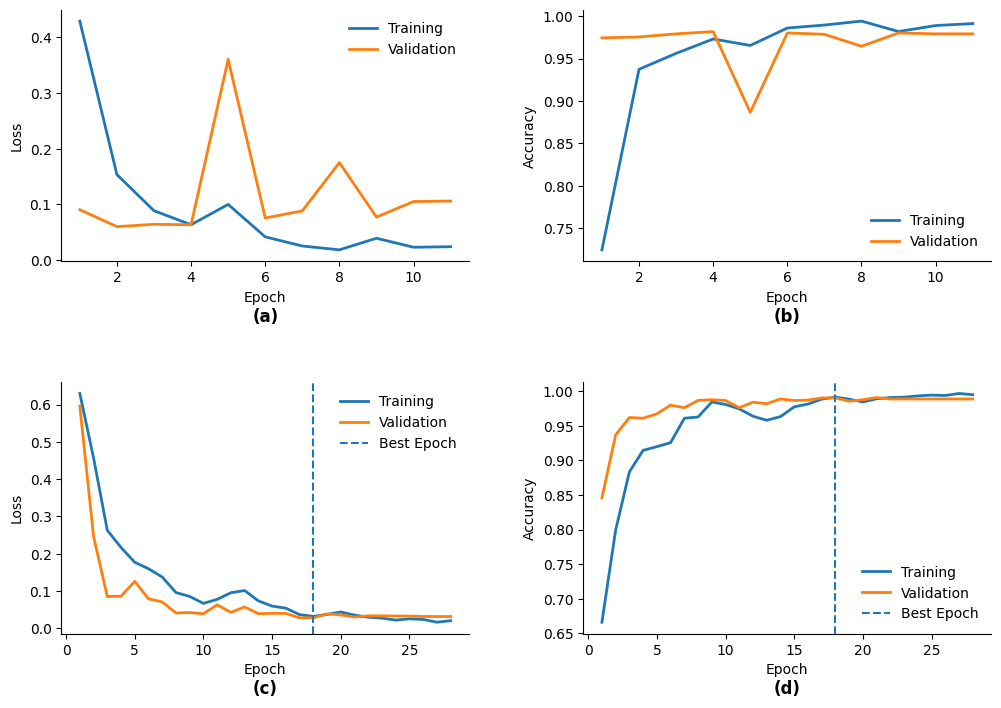


FIGURE GENERATED
B-BiLSTM epochs     : 11
R-GWO-BiLSTM epochs : 28
R-GWO-BiLSTM best epoch: 18

Saved PNG:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/Training_Validation_Curves_Baseline_vs_Robust.png

Saved PDF:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/Training_Validation_Curves_Baseline_vs_Robust.pdf

Training performed : False
Inference performed: False

STEP 47 COMPLETED


In [49]:
# ============================================================
# STEP 47: Training and Validation Curves
# B-BiLSTM vs R-GWO-BiLSTM
#
# (a) B-BiLSTM Loss
# (b) B-BiLSTM Accuracy
# (c) R-GWO-BiLSTM Loss
# (d) R-GWO-BiLSTM Accuracy
#
# NO TRAINING
# NO INFERENCE
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

BASELINE_HISTORY_PATH = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_Baseline_BiLSTM/training_history.csv"
)

ROBUST_HISTORY_PATH = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM/"
    "training_history.csv"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM/Final_Binary_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

PNG_PATH = os.path.join(
    OUTPUT_DIR,
    "Training_Validation_Curves_Baseline_vs_Robust.png"
)

PDF_PATH = os.path.join(
    OUTPUT_DIR,
    "Training_Validation_Curves_Baseline_vs_Robust.pdf"
)


# ------------------------------------------------------------
# 2. Check saved histories
# ------------------------------------------------------------

if not os.path.exists(BASELINE_HISTORY_PATH):
    raise FileNotFoundError(
        f"Baseline history not found:\n{BASELINE_HISTORY_PATH}"
    )

if not os.path.exists(ROBUST_HISTORY_PATH):
    raise FileNotFoundError(
        f"Robust model history not found:\n{ROBUST_HISTORY_PATH}"
    )


# ------------------------------------------------------------
# 3. Load histories
# ------------------------------------------------------------

baseline_history = pd.read_csv(BASELINE_HISTORY_PATH)
robust_history = pd.read_csv(ROBUST_HISTORY_PATH)


print("=" * 70)
print("STEP 47: TRAINING AND VALIDATION CURVES")
print("=" * 70)

print("\nBaseline history shape:")
print(baseline_history.shape)

print("\nR-GWO-BiLSTM history shape:")
print(robust_history.shape)

print("\nBaseline columns:")
print(list(baseline_history.columns))

print("\nR-GWO-BiLSTM columns:")
print(list(robust_history.columns))


# ------------------------------------------------------------
# 4. Epoch arrays
# ------------------------------------------------------------

baseline_epochs = range(
    1,
    len(baseline_history) + 1
)

robust_epochs = range(
    1,
    len(robust_history) + 1
)


# ------------------------------------------------------------
# 5. Publication-quality 2 x 2 figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8)
)


# ------------------------------------------------------------
# (a) B-BiLSTM Loss
# ------------------------------------------------------------

ax = axes[0, 0]

ax.plot(
    baseline_epochs,
    baseline_history["loss"],
    linewidth=2,
    label="Training"
)

ax.plot(
    baseline_epochs,
    baseline_history["val_loss"],
    linewidth=2,
    label="Validation"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(frameon=False)

ax.text(
    0.5,
    -0.22,
    "(a)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)


# ------------------------------------------------------------
# (b) B-BiLSTM Accuracy
# ------------------------------------------------------------

ax = axes[0, 1]

ax.plot(
    baseline_epochs,
    baseline_history["accuracy"],
    linewidth=2,
    label="Training"
)

ax.plot(
    baseline_epochs,
    baseline_history["val_accuracy"],
    linewidth=2,
    label="Validation"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend(frameon=False)

ax.text(
    0.5,
    -0.22,
    "(b)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)


# ------------------------------------------------------------
# (c) R-GWO-BiLSTM Loss
# ------------------------------------------------------------

ax = axes[1, 0]

ax.plot(
    robust_epochs,
    robust_history["loss"],
    linewidth=2,
    label="Training"
)

ax.plot(
    robust_epochs,
    robust_history["val_loss"],
    linewidth=2,
    label="Validation"
)

# Best epoch for final robust model
ax.axvline(
    x=18,
    linestyle="--",
    linewidth=1.5,
    label="Best Epoch"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(frameon=False)

ax.text(
    0.5,
    -0.22,
    "(c)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)


# ------------------------------------------------------------
# (d) R-GWO-BiLSTM Accuracy
# ------------------------------------------------------------

ax = axes[1, 1]

ax.plot(
    robust_epochs,
    robust_history["accuracy"],
    linewidth=2,
    label="Training"
)

ax.plot(
    robust_epochs,
    robust_history["val_accuracy"],
    linewidth=2,
    label="Validation"
)

ax.axvline(
    x=18,
    linestyle="--",
    linewidth=1.5,
    label="Best Epoch"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend(frameon=False)

ax.text(
    0.5,
    -0.22,
    "(d)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)


# ------------------------------------------------------------
# 6. Clean publication formatting
# ------------------------------------------------------------

for ax in axes.flat:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.grid(False)


plt.subplots_adjust(
    hspace=0.48,
    wspace=0.28,
    bottom=0.10
)


# ------------------------------------------------------------
# 7. Save high-resolution figures
# ------------------------------------------------------------

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FIGURE GENERATED")
print("=" * 70)

print(
    f"B-BiLSTM epochs     : {len(baseline_history)}"
)

print(
    f"R-GWO-BiLSTM epochs : {len(robust_history)}"
)

print(
    "R-GWO-BiLSTM best epoch: 18"
)

print("\nSaved PNG:")
print(PNG_PATH)

print("\nSaved PDF:")
print(PDF_PATH)

print("\nTraining performed : False")
print("Inference performed: False")

print("\n" + "=" * 70)
print("STEP 47 COMPLETED")
print("=" * 70)

STEP 47: R-GWO-BiLSTM TRAINING AND VALIDATION CURVES

Total epochs : 28
Best epoch   : 18

History columns:
['epoch', 'accuracy', 'loss', 'pr_auc', 'precision', 'recall', 'roc_auc', 'val_accuracy', 'val_loss', 'val_pr_auc', 'val_precision', 'val_recall', 'val_roc_auc', 'learning_rate', 'epoch_time_seconds']


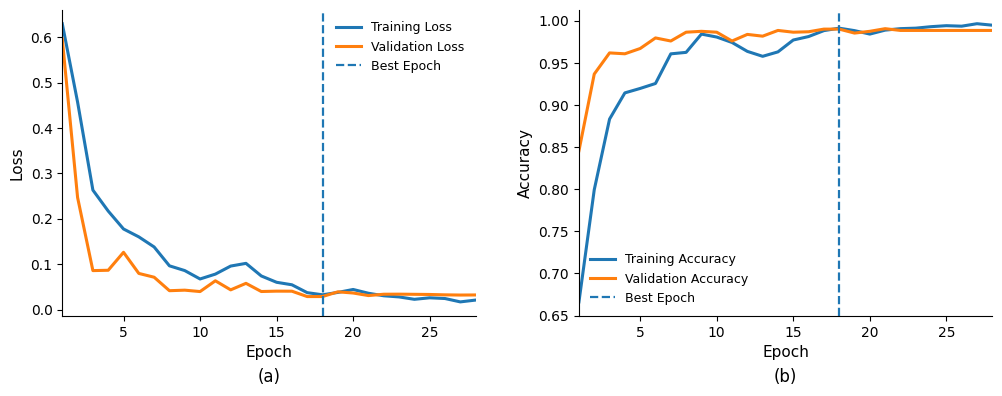


FIGURE GENERATED
Total epochs             : 28
Best epoch               : 18

Saved PNG:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/R_GWO_BiLSTM_Training_Validation_Curves.png

Saved PDF:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/R_GWO_BiLSTM_Training_Validation_Curves.pdf

Training performed       : False
Inference performed      : False

STEP 47 COMPLETED


In [56]:
# ============================================================
# STEP 47: R-GWO-BiLSTM Training and Validation Curves
#
# (a) Training and Validation Loss
# (b) Training and Validation Accuracy
#
# NO TRAINING
# NO INFERENCE
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

ROBUST_HISTORY_PATH = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM/"
    "training_history.csv"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM/Final_Binary_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

PNG_PATH = os.path.join(
    OUTPUT_DIR,
    "R_GWO_BiLSTM_Training_Validation_Curves.png"
)

PDF_PATH = os.path.join(
    OUTPUT_DIR,
    "R_GWO_BiLSTM_Training_Validation_Curves.pdf"
)


# ------------------------------------------------------------
# 2. Check and load saved training history
# ------------------------------------------------------------

if not os.path.exists(ROBUST_HISTORY_PATH):
    raise FileNotFoundError(
        f"Training history not found:\n{ROBUST_HISTORY_PATH}"
    )

history = pd.read_csv(ROBUST_HISTORY_PATH)


# ------------------------------------------------------------
# 3. Epoch information
# ------------------------------------------------------------

epochs = range(1, len(history) + 1)

BEST_EPOCH = 18


print("=" * 70)
print("STEP 47: R-GWO-BiLSTM TRAINING AND VALIDATION CURVES")
print("=" * 70)

print(f"\nTotal epochs : {len(history)}")
print(f"Best epoch   : {BEST_EPOCH}")

print("\nHistory columns:")
print(list(history.columns))


# ------------------------------------------------------------
# 4. Create side-by-side figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5)
)


# ============================================================
# (a) Training and Validation Loss
# ============================================================

ax = axes[0]

ax.plot(
    epochs,
    history["loss"],
    linewidth=2.2,
    label="Training Loss"
)

ax.plot(
    epochs,
    history["val_loss"],
    linewidth=2.2,
    label="Validation Loss"
)

ax.axvline(
    x=BEST_EPOCH,
    linestyle="--",
    linewidth=1.6,
    label=f"Best Epoch"
)

ax.set_xlabel(
    "Epoch",
    fontsize=11
)

ax.set_ylabel(
    "Loss",
    fontsize=11
)

ax.legend(
    frameon=False,
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

# Panel label
ax.text(
    0.5,
    -0.20,
    "(a)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12
)


# ============================================================
# (b) Training and Validation Accuracy
# ============================================================

ax = axes[1]

ax.plot(
    epochs,
    history["accuracy"],
    linewidth=2.2,
    label="Training Accuracy"
)

ax.plot(
    epochs,
    history["val_accuracy"],
    linewidth=2.2,
    label="Validation Accuracy"
)

ax.axvline(
    x=BEST_EPOCH,
    linestyle="--",
    linewidth=1.6,
    label=f"Best Epoch"
)

ax.set_xlabel(
    "Epoch",
    fontsize=11
)

ax.set_ylabel(
    "Accuracy",
    fontsize=11
)

# Legend positioned at the lower left for plot (b)
ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

# Panel label
ax.text(
    0.5,
    -0.20,
    "(b)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12
)


# ------------------------------------------------------------
# 5. Common formatting
# ------------------------------------------------------------

for ax in axes:

    ax.set_xlim(
        1,
        len(history)
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )


plt.subplots_adjust(
    wspace=0.25,
    bottom=0.20
)


# ------------------------------------------------------------
# 6. Save publication-quality figure
# ------------------------------------------------------------

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FIGURE GENERATED")
print("=" * 70)

print(f"Total epochs             : {len(history)}")
print(f"Best epoch               : {BEST_EPOCH}")

print("\nSaved PNG:")
print(PNG_PATH)

print("\nSaved PDF:")
print(PDF_PATH)

print("\nTraining performed       : False")
print("Inference performed      : False")

print("\n" + "=" * 70)
print("STEP 47 COMPLETED")
print("=" * 70)

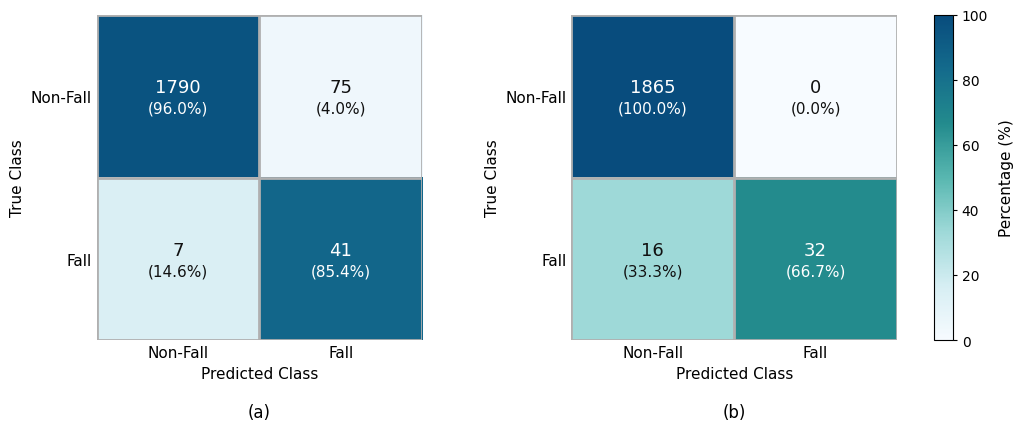

STEP 48: CONFUSION MATRICES COMPLETED

B-BiLSTM:
TN = 1790
FP = 75
FN = 7
TP = 41

R-GWO-BiLSTM:
TN = 1865
FP = 0
FN = 16
TP = 32

Saved PNG:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/Confusion_Matrix_Baseline_vs_R_GWO_BiLSTM_Colorful.png

Saved PDF:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/Confusion_Matrix_Baseline_vs_R_GWO_BiLSTM_Colorful.pdf

Training performed : False
Inference performed: False


In [58]:
# ============================================================
# STEP 48: Publication-Quality Confusion Matrices
#
# (a) B-BiLSTM
# (b) R-GWO-BiLSTM
#
# Counts + Row-normalized percentages
# NO TRAINING
# NO INFERENCE
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# ------------------------------------------------------------
# 1. Output paths
# ------------------------------------------------------------

OUTPUT_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM/Final_Binary_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

PNG_PATH = os.path.join(
    OUTPUT_DIR,
    "Confusion_Matrix_Baseline_vs_R_GWO_BiLSTM_Colorful.png"
)

PDF_PATH = os.path.join(
    OUTPUT_DIR,
    "Confusion_Matrix_Baseline_vs_R_GWO_BiLSTM_Colorful.pdf"
)


# ------------------------------------------------------------
# 2. Final test confusion matrices
#
# Format:
# [[TN, FP],
#  [FN, TP]]
# ------------------------------------------------------------

cm_baseline = np.array([
    [1790, 75],
    [7, 41]
])

cm_proposed = np.array([
    [1865, 0],
    [16, 32]
])


# ------------------------------------------------------------
# 3. Class labels
# ------------------------------------------------------------

class_labels = [
    "Non-Fall",
    "Fall"
]


# ------------------------------------------------------------
# 4. Attractive custom color map
# ------------------------------------------------------------

colors = [
    "#F7FBFF",   # very light
    "#D6EEF3",   # light cyan
    "#9ED9D8",   # turquoise
    "#58B7B0",   # teal
    "#238B8D",   # deep teal
    "#146B8C",   # blue-teal
    "#084C7D"    # dark blue
]

custom_cmap = LinearSegmentedColormap.from_list(
    "FallDetectionMap",
    colors
)


# ------------------------------------------------------------
# 5. Confusion matrix plotting function
# ------------------------------------------------------------

def plot_confusion_matrix(ax, cm, panel_label):

    # Row-normalized percentages
    percentages = (
        cm.astype(float)
        / cm.sum(axis=1, keepdims=True)
    ) * 100


    # --------------------------------------------------------
    # Heatmap
    # --------------------------------------------------------

    im = ax.imshow(
        percentages,
        cmap=custom_cmap,
        vmin=0,
        vmax=100,
        interpolation="nearest"
    )


    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(
        class_labels,
        fontsize=11
    )

    ax.set_yticklabels(
        class_labels,
        fontsize=11
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=11
    )

    ax.set_ylabel(
        "True Class",
        fontsize=11
    )


    # --------------------------------------------------------
    # Cell annotations
    # --------------------------------------------------------

    for i in range(2):
        for j in range(2):

            value = cm[i, j]
            percentage = percentages[i, j]

            # Choose text color according to background
            if percentage >= 55:
                text_color = "white"
            else:
                text_color = "#111111"

            ax.text(
                j,
                i - 0.055,
                f"{value}",
                ha="center",
                va="center",
                fontsize=13,
                fontweight="medium",
                color=text_color
            )

            ax.text(
                j,
                i + 0.075,
                f"({percentage:.1f}%)",
                ha="center",
                va="center",
                fontsize=11,
                color=text_color
            )


    # --------------------------------------------------------
    # White separation between cells
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        linewidth=2.0
    )

    # Set grid lines to white
    for line in ax.get_xgridlines() + ax.get_ygridlines():
        line.set_color("white")


    # --------------------------------------------------------
    # Remove outer spines and tick marks
    # --------------------------------------------------------

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        which="both",
        length=0
    )


    # --------------------------------------------------------
    # Panel label
    # --------------------------------------------------------

    ax.text(
        0.5,
        -0.22,
        panel_label,
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=12
    )

    return im


# ------------------------------------------------------------
# 6. Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10.5, 4.4)
)


# ------------------------------------------------------------
# 7. Plot baseline
# ------------------------------------------------------------

im = plot_confusion_matrix(
    axes[0],
    cm_baseline,
    "(a)"
)


# ------------------------------------------------------------
# 8. Plot proposed model
# ------------------------------------------------------------

plot_confusion_matrix(
    axes[1],
    cm_proposed,
    "(b)"
)


# ------------------------------------------------------------
# 9. Adjust main figure first
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.20,
    top=0.94,
    wspace=0.38
)


# ------------------------------------------------------------
# 10. Create a separate aligned colorbar
#
# This prevents the colorbar from touching the matrix
# and keeps its height aligned with the matrix.
# ------------------------------------------------------------

pos = axes[1].get_position()

cbar_width = 0.018
cbar_gap = 0.035

cbar_ax = fig.add_axes([
    pos.x1 + cbar_gap,
    pos.y0,
    cbar_width,
    pos.height
])

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

cbar.set_ticks(
    [0, 20, 40, 60, 80, 100]
)

cbar.set_label(
    "Percentage (%)",
    fontsize=11,
    labelpad=8
)

cbar.ax.tick_params(
    labelsize=10,
    length=3
)


# ------------------------------------------------------------
# 11. Save publication-quality figure
# ------------------------------------------------------------

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 12. Summary
# ------------------------------------------------------------

print("=" * 70)
print("STEP 48: CONFUSION MATRICES COMPLETED")
print("=" * 70)

print("\nB-BiLSTM:")
print("TN = 1790")
print("FP = 75")
print("FN = 7")
print("TP = 41")

print("\nR-GWO-BiLSTM:")
print("TN = 1865")
print("FP = 0")
print("FN = 16")
print("TP = 32")

print("\nSaved PNG:")
print(PNG_PATH)

print("\nSaved PDF:")
print(PDF_PATH)

print("\nTraining performed : False")
print("Inference performed: False")

print("=" * 70)

STEP 49: ROC AND PRECISION-RECALL CURVES

Baseline predictions:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_Baseline_BiLSTM/test_predictions.csv

R-GWO-BiLSTM predictions:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM/final_locked_test_predictions.csv

Baseline columns:
['subject', 'activity', 'true_binary_label', 'predicted_probability', 'predicted_binary_label']

R-GWO-BiLSTM columns:
['true_label', 'predicted_probability', 'locked_threshold', 'predicted_label']


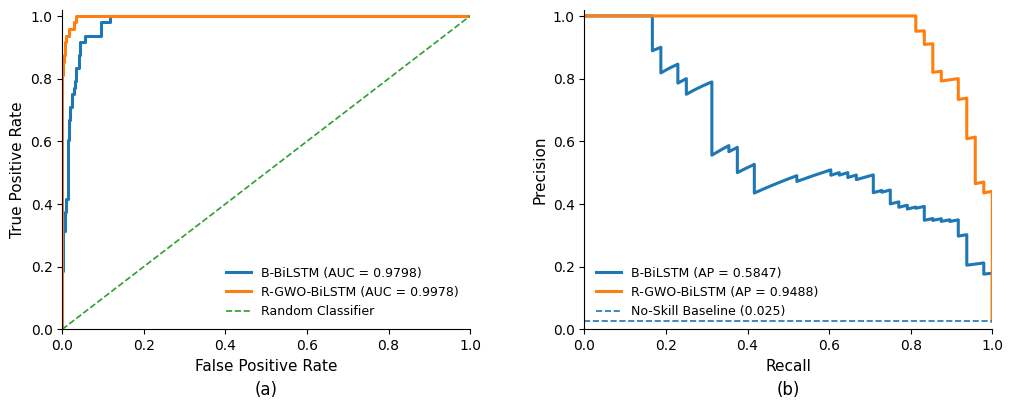


ROC AND PRECISION-RECALL RESULTS

B-BiLSTM:
ROC-AUC = 0.979770
AP      = 0.584667

R-GWO-BiLSTM:
ROC-AUC = 0.997811
AP      = 0.948848

Saved PNG:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/ROC_PR_Baseline_vs_R_GWO_BiLSTM.png

Saved PDF:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/ROC_PR_Baseline_vs_R_GWO_BiLSTM.pdf

Training performed : False
Inference performed: False
STEP 49 COMPLETED


In [59]:
# ============================================================
# STEP 49: ROC and Precision-Recall Curve Comparison
#
# (a) ROC Curve
# (b) Precision-Recall Curve
#
# Models:
# B-BiLSTM
# R-GWO-BiLSTM
#
# NO TRAINING
# NO INFERENCE
# Uses saved test probabilities only
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)


# ------------------------------------------------------------
# 1. Prediction file paths
# ------------------------------------------------------------

BASELINE_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_Baseline_BiLSTM"
)

ROBUST_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM/Final_Robust_GWO_BiLSTM"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM/Final_Binary_Results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. Find saved prediction files
# ------------------------------------------------------------

def find_prediction_file(folder):

    preferred_names = [
        "test_predictions.csv",
        "final_locked_test_predictions.csv"
    ]

    for name in preferred_names:
        path = os.path.join(folder, name)

        if os.path.exists(path):
            return path

    # Search for any prediction CSV
    if os.path.exists(folder):

        candidates = [
            os.path.join(folder, f)
            for f in os.listdir(folder)
            if f.endswith(".csv")
            and "prediction" in f.lower()
            and "test" in f.lower()
        ]

        if len(candidates) > 0:
            return candidates[0]

    return None


BASELINE_PRED_PATH = find_prediction_file(BASELINE_DIR)

ROBUST_PRED_PATH = find_prediction_file(ROBUST_DIR)


if BASELINE_PRED_PATH is None:
    raise FileNotFoundError(
        "Baseline test prediction file could not be found."
    )

if ROBUST_PRED_PATH is None:
    raise FileNotFoundError(
        "R-GWO-BiLSTM test prediction file could not be found."
    )


print("=" * 70)
print("STEP 49: ROC AND PRECISION-RECALL CURVES")
print("=" * 70)

print("\nBaseline predictions:")
print(BASELINE_PRED_PATH)

print("\nR-GWO-BiLSTM predictions:")
print(ROBUST_PRED_PATH)


# ------------------------------------------------------------
# 3. Load predictions
# ------------------------------------------------------------

baseline_df = pd.read_csv(BASELINE_PRED_PATH)
robust_df = pd.read_csv(ROBUST_PRED_PATH)

print("\nBaseline columns:")
print(list(baseline_df.columns))

print("\nR-GWO-BiLSTM columns:")
print(list(robust_df.columns))


# ------------------------------------------------------------
# 4. Automatically identify label and probability columns
# ------------------------------------------------------------

def extract_label_probability(df):

    label_candidates = [
        "y_true",
        "true_label",
        "label",
        "actual",
        "target"
    ]

    probability_candidates = [
        "y_prob",
        "probability",
        "predicted_probability",
        "prediction_probability",
        "y_probability",
        "prob"
    ]

    label_col = None
    prob_col = None


    for col in label_candidates:

        if col in df.columns:
            label_col = col
            break


    for col in probability_candidates:

        if col in df.columns:
            prob_col = col
            break


    if label_col is None:

        for col in df.columns:

            if (
                "true" in col.lower()
                or "label" in col.lower()
            ):
                label_col = col
                break


    if prob_col is None:

        for col in df.columns:

            if (
                "prob" in col.lower()
                or "score" in col.lower()
            ):
                prob_col = col
                break


    if label_col is None or prob_col is None:

        raise ValueError(
            "Could not automatically identify "
            "label/probability columns.\n"
            f"Available columns: {list(df.columns)}"
        )


    return (
        df[label_col].values.astype(int),
        df[prob_col].values.astype(float)
    )


y_baseline, p_baseline = extract_label_probability(
    baseline_df
)

y_robust, p_robust = extract_label_probability(
    robust_df
)


# ------------------------------------------------------------
# 5. Check test labels
# ------------------------------------------------------------

if not np.array_equal(y_baseline, y_robust):

    print(
        "\nWARNING: Saved prediction files do not have "
        "identical label ordering."
    )


# ------------------------------------------------------------
# 6. ROC calculations
# ------------------------------------------------------------

fpr_baseline, tpr_baseline, _ = roc_curve(
    y_baseline,
    p_baseline
)

fpr_robust, tpr_robust, _ = roc_curve(
    y_robust,
    p_robust
)

roc_auc_baseline = roc_auc_score(
    y_baseline,
    p_baseline
)

roc_auc_robust = roc_auc_score(
    y_robust,
    p_robust
)


# ------------------------------------------------------------
# 7. Precision-Recall calculations
# ------------------------------------------------------------

precision_baseline, recall_baseline, _ = (
    precision_recall_curve(
        y_baseline,
        p_baseline
    )
)

precision_robust, recall_robust, _ = (
    precision_recall_curve(
        y_robust,
        p_robust
    )
)


# Average Precision
ap_baseline = average_precision_score(
    y_baseline,
    p_baseline
)

ap_robust = average_precision_score(
    y_robust,
    p_robust
)


# ------------------------------------------------------------
# 8. Create side-by-side figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.7)
)


# ============================================================
# (a) ROC Curve
# ============================================================

ax = axes[0]

ax.plot(
    fpr_baseline,
    tpr_baseline,
    linewidth=2.2,
    label=f"B-BiLSTM (AUC = {roc_auc_baseline:.4f})"
)

ax.plot(
    fpr_robust,
    tpr_robust,
    linewidth=2.2,
    label=f"R-GWO-BiLSTM (AUC = {roc_auc_robust:.4f})"
)

# Random classifier reference
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    label="Random Classifier"
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=11
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=11
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.text(
    0.5,
    -0.19,
    "(a)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12
)


# ============================================================
# (b) Precision-Recall Curve
# ============================================================

ax = axes[1]

ax.plot(
    recall_baseline,
    precision_baseline,
    linewidth=2.2,
    label=f"B-BiLSTM (AP = {ap_baseline:.4f})"
)

ax.plot(
    recall_robust,
    precision_robust,
    linewidth=2.2,
    label=f"R-GWO-BiLSTM (AP = {ap_robust:.4f})"
)


# Random/no-skill baseline = prevalence of positive class
fall_prevalence = np.mean(y_robust)

ax.axhline(
    y=fall_prevalence,
    linestyle="--",
    linewidth=1.2,
    label=f"No-Skill Baseline ({fall_prevalence:.3f})"
)

ax.set_xlabel(
    "Recall",
    fontsize=11
)

ax.set_ylabel(
    "Precision",
    fontsize=11
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.text(
    0.5,
    -0.19,
    "(b)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=12
)


# ------------------------------------------------------------
# 9. Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    wspace=0.28,
    bottom=0.20
)


# ------------------------------------------------------------
# 10. Save
# ------------------------------------------------------------

PNG_PATH = os.path.join(
    OUTPUT_DIR,
    "ROC_PR_Baseline_vs_R_GWO_BiLSTM.png"
)

PDF_PATH = os.path.join(
    OUTPUT_DIR,
    "ROC_PR_Baseline_vs_R_GWO_BiLSTM.pdf"
)

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 11. Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ROC AND PRECISION-RECALL RESULTS")
print("=" * 70)

print("\nB-BiLSTM:")
print(f"ROC-AUC = {roc_auc_baseline:.6f}")
print(f"AP      = {ap_baseline:.6f}")

print("\nR-GWO-BiLSTM:")
print(f"ROC-AUC = {roc_auc_robust:.6f}")
print(f"AP      = {ap_robust:.6f}")

print("\nSaved PNG:")
print(PNG_PATH)

print("\nSaved PDF:")
print(PDF_PATH)

print("\nTraining performed : False")
print("Inference performed: False")

print("=" * 70)
print("STEP 49 COMPLETED")
print("=" * 70)

STEP 50: ENHANCED GWO CONVERGENCE CURVE

Available columns:
['iteration', 'iteration_best_pr_auc', 'global_best_pr_auc', 'mean_population_pr_auc', 'std_population_pr_auc', 'best_bilstm_units_1', 'best_bilstm_units_2', 'best_dropout_rate', 'best_learning_rate', 'best_batch_size']

Iteration column : iteration
Fitness column   : iteration_best_pr_auc

GWO CONVERGENCE SUMMARY
Iterations             : 15
Fitness improvements   : 4
Best validation fitness: 0.936963
Convergence iteration  : 5


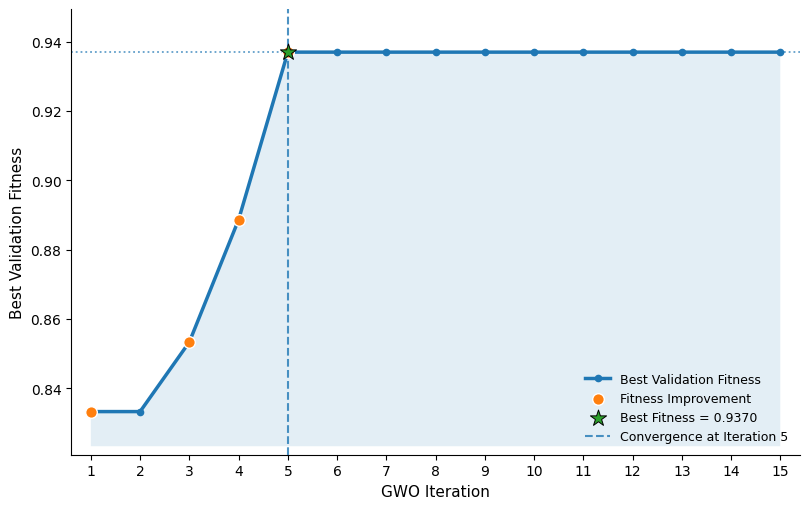


ENHANCED GWO CONVERGENCE FIGURE GENERATED
Best fitness          : 0.936963
Convergence iteration : 5
Improvement iterations: [np.int64(1), np.int64(3), np.int64(4), np.int64(5)]

Saved PNG:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/GWO_Convergence_Curve_Enhanced.png

Saved PDF:
/content/drive/MyDrive/GWO-BiLSTN/Experiments/Binary_GWO_BiLSTM/Final_Binary_Results/GWO_Convergence_Curve_Enhanced.pdf

GWO search performed : False
Training performed   : False
Inference performed  : False

STEP 50 COMPLETED


In [61]:
# ============================================================
# STEP 50: Enhanced GWO Convergence Curve
#
# Shows:
# 1. Best validation fitness by GWO iteration
# 2. Fitness improvement points
# 3. Best solution
# 4. Convergence point
#
# NO GWO SEARCH
# NO TRAINING
# NO INFERENCE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

GWO_DIR = (
    "/content/drive/MyDrive/GWO-BiLSTN/Experiments/"
    "Binary_GWO_BiLSTM"
)

GWO_HISTORY_PATH = os.path.join(
    GWO_DIR,
    "gwo_convergence_history.csv"
)

OUTPUT_DIR = os.path.join(
    GWO_DIR,
    "Final_Binary_Results"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

PNG_PATH = os.path.join(
    OUTPUT_DIR,
    "GWO_Convergence_Curve_Enhanced.png"
)

PDF_PATH = os.path.join(
    OUTPUT_DIR,
    "GWO_Convergence_Curve_Enhanced.pdf"
)


# ------------------------------------------------------------
# 2. Check saved convergence history
# ------------------------------------------------------------

if not os.path.exists(GWO_HISTORY_PATH):
    raise FileNotFoundError(
        f"GWO convergence history not found:\n"
        f"{GWO_HISTORY_PATH}"
    )


# ------------------------------------------------------------
# 3. Load saved history
# ------------------------------------------------------------

gwo_history = pd.read_csv(
    GWO_HISTORY_PATH
)

print("=" * 70)
print("STEP 50: ENHANCED GWO CONVERGENCE CURVE")
print("=" * 70)

print("\nAvailable columns:")
print(list(gwo_history.columns))


# ------------------------------------------------------------
# 4. Identify iteration column
# ------------------------------------------------------------

iteration_col = None

iteration_candidates = [
    "iteration",
    "Iteration",
    "iter",
    "Iter",
    "gwo_iteration"
]

for col in iteration_candidates:

    if col in gwo_history.columns:
        iteration_col = col
        break


if iteration_col is None:

    for col in gwo_history.columns:

        if "iter" in col.lower():
            iteration_col = col
            break


if iteration_col is None:

    raise ValueError(
        "Could not identify iteration column.\n"
        f"Available columns: {list(gwo_history.columns)}"
    )


# ------------------------------------------------------------
# 5. Identify fitness column
# ------------------------------------------------------------

fitness_col = None

fitness_candidates = [
    "best_fitness",
    "Best_Fitness",
    "best_pr_auc",
    "best_val_pr_auc",
    "global_best_fitness",
    "alpha_fitness"
]

for col in fitness_candidates:

    if col in gwo_history.columns:
        fitness_col = col
        break


if fitness_col is None:

    for col in gwo_history.columns:

        col_lower = col.lower()

        if (
            "best" in col_lower
            and (
                "fitness" in col_lower
                or "pr" in col_lower
            )
        ):
            fitness_col = col
            break


if fitness_col is None:

    raise ValueError(
        "Could not identify fitness column.\n"
        f"Available columns: {list(gwo_history.columns)}"
    )


print(f"\nIteration column : {iteration_col}")
print(f"Fitness column   : {fitness_col}")


# ------------------------------------------------------------
# 6. Prepare data
# ------------------------------------------------------------

plot_df = gwo_history[
    [iteration_col, fitness_col]
].copy()

plot_df = plot_df.dropna()

plot_df[iteration_col] = pd.to_numeric(
    plot_df[iteration_col]
)

plot_df[fitness_col] = pd.to_numeric(
    plot_df[fitness_col]
)

plot_df = plot_df.sort_values(
    iteration_col
)


# ------------------------------------------------------------
# 7. Best value within each iteration
# ------------------------------------------------------------

plot_df = (
    plot_df
    .groupby(
        iteration_col,
        as_index=False
    )[fitness_col]
    .max()
)


# ------------------------------------------------------------
# 8. Cumulative best fitness
# ------------------------------------------------------------

plot_df["best_so_far"] = (
    plot_df[fitness_col]
    .cummax()
)

iterations = plot_df[
    iteration_col
].to_numpy()

fitness = plot_df[
    "best_so_far"
].to_numpy()


# ------------------------------------------------------------
# 9. Detect genuine fitness improvements
# ------------------------------------------------------------

improvement_mask = np.zeros(
    len(fitness),
    dtype=bool
)

improvement_mask[0] = True

if len(fitness) > 1:

    improvement_mask[1:] = (
        np.diff(fitness) > 1e-12
    )


improvement_iterations = iterations[
    improvement_mask
]

improvement_fitness = fitness[
    improvement_mask
]


# ------------------------------------------------------------
# 10. Determine best and convergence point
# ------------------------------------------------------------

best_fitness = np.max(
    fitness
)

best_indices = np.where(
    np.isclose(
        fitness,
        best_fitness
    )
)[0]

# First iteration where final best fitness was reached
convergence_index = best_indices[0]

convergence_iteration = iterations[
    convergence_index
]


print("\n" + "=" * 70)
print("GWO CONVERGENCE SUMMARY")
print("=" * 70)

print(
    f"Iterations             : "
    f"{len(iterations)}"
)

print(
    f"Fitness improvements   : "
    f"{len(improvement_iterations)}"
)

print(
    f"Best validation fitness: "
    f"{best_fitness:.6f}"
)

print(
    f"Convergence iteration  : "
    f"{convergence_iteration}"
)


# ------------------------------------------------------------
# 11. Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.2, 5.2)
)


# ------------------------------------------------------------
# 12. Shaded convergence region
# ------------------------------------------------------------

lower_limit = max(
    0,
    np.min(fitness) - 0.01
)

ax.fill_between(
    iterations,
    lower_limit,
    fitness,
    alpha=0.12
)


# ------------------------------------------------------------
# 13. Main convergence curve
# ------------------------------------------------------------

ax.plot(
    iterations,
    fitness,
    linewidth=2.5,
    marker="o",
    markersize=4.5,
    label="Best Validation Fitness"
)


# ------------------------------------------------------------
# 14. Highlight genuine improvement points
# ------------------------------------------------------------

ax.scatter(
    improvement_iterations,
    improvement_fitness,
    s=70,
    marker="o",
    edgecolors="white",
    linewidths=1.0,
    zorder=5,
    label="Fitness Improvement"
)


# ------------------------------------------------------------
# 15. Highlight final best solution
# ------------------------------------------------------------

ax.scatter(
    convergence_iteration,
    best_fitness,
    s=150,
    marker="*",
    edgecolors="black",
    linewidths=0.7,
    zorder=7,
    label=f"Best Fitness = {best_fitness:.4f}"
)


# ------------------------------------------------------------
# 16. Mark convergence iteration
# ------------------------------------------------------------

ax.axvline(
    x=convergence_iteration,
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label=f"Convergence at Iteration {int(convergence_iteration)}"
)


# ------------------------------------------------------------
# 17. Plateau indication
# ------------------------------------------------------------

ax.axhline(
    y=best_fitness,
    linestyle=":",
    linewidth=1.3,
    alpha=0.7
)


# ------------------------------------------------------------
# 18. Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "GWO Iteration",
    fontsize=11
)

ax.set_ylabel(
    "Best Validation Fitness",
    fontsize=11
)


# ------------------------------------------------------------
# 19. X-axis
# ------------------------------------------------------------

ax.set_xticks(
    iterations
)

ax.set_xlim(
    np.min(iterations) - 0.4,
    np.max(iterations) + 0.4
)


# ------------------------------------------------------------
# 20. Y-axis
# ------------------------------------------------------------

fitness_range = (
    np.max(fitness)
    - np.min(fitness)
)

y_margin = max(
    fitness_range * 0.12,
    0.005
)

ax.set_ylim(
    max(
        0,
        np.min(fitness) - y_margin
    ),
    min(
        1.0,
        np.max(fitness) + y_margin
    )
)


# ------------------------------------------------------------
# 21. Legend
# ------------------------------------------------------------

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=9
)


# ------------------------------------------------------------
# 22. Publication formatting
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(False)

ax.tick_params(
    axis="both",
    labelsize=10
)


plt.tight_layout()


# ------------------------------------------------------------
# 23. Save
# ------------------------------------------------------------

plt.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 24. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENHANCED GWO CONVERGENCE FIGURE GENERATED")
print("=" * 70)

print(
    f"Best fitness          : "
    f"{best_fitness:.6f}"
)

print(
    f"Convergence iteration : "
    f"{convergence_iteration}"
)

print(
    f"Improvement iterations: "
    f"{list(improvement_iterations)}"
)

print("\nSaved PNG:")
print(PNG_PATH)

print("\nSaved PDF:")
print(PDF_PATH)

print("\nGWO search performed : False")
print("Training performed   : False")
print("Inference performed  : False")

print("\n" + "=" * 70)
print("STEP 50 COMPLETED")
print("=" * 70)